In [1]:
# Cell 1 — Imports and Setup

import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass, field
from typing import List, Tuple, Optional
from enum import Enum

# Plotting config
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
plt.style.use('seaborn-v0_8-whitegrid')

# Unit transfer overhead (seconds per byte) — synthetic baseline
UNIT_TRANSFER_OVERHEAD = 1e-9  # 1 ns per byte, roughly ~1 GB/s effective bandwidth

# Device power consumption estimates (watts) for throughput-per-watt calculations
GPU_POWER = 15.0   # Low-resource edge GPU (e.g., Jetson-class)
FPGA_POWER = 5.0   # Small FPGA fabric (e.g., Zynq 7020)

print("Environment ready.")

Environment ready.


In [2]:
# Cell 2 — Layer and Architecture Definitions

class LayerType(Enum):
    CONV = "conv"
    DEPTHWISE_CONV = "depthwise_conv"
    POINTWISE_CONV = "pointwise_conv"
    BATCHNORM = "batchnorm"
    RELU = "relu"
    POOL = "pool"
    FC = "fc"

class Device(Enum):
    GPU = "GPU"
    FPGA = "FPGA"

@dataclass
class Layer:
    name: str
    layer_type: LayerType
    
    # Input dimensions
    in_channels: int
    in_height: int
    in_width: int
    
    # Output dimensions
    out_channels: int
    out_height: int
    out_width: int
    
    # Kernel properties (where applicable)
    kernel_size: int = 1
    stride: int = 1
    groups: int = 1
    
    # Computed properties
    @property
    def flops(self) -> int:
        """Estimate FLOPs for this layer."""
        if self.layer_type == LayerType.CONV:
            # Standard conv: 2 * K^2 * Cin * Cout * Hout * Wout
            return 2 * (self.kernel_size ** 2) * self.in_channels * self.out_channels * self.out_height * self.out_width
        
        elif self.layer_type == LayerType.DEPTHWISE_CONV:
            # Depthwise: 2 * K^2 * C * Hout * Wout
            return 2 * (self.kernel_size ** 2) * self.in_channels * self.out_height * self.out_width
        
        elif self.layer_type == LayerType.POINTWISE_CONV:
            # 1x1 conv: 2 * Cin * Cout * Hout * Wout
            return 2 * self.in_channels * self.out_channels * self.out_height * self.out_width
        
        elif self.layer_type == LayerType.BATCHNORM:
            # ~4 ops per element (subtract mean, divide std, scale, shift)
            return 4 * self.out_channels * self.out_height * self.out_width
        
        elif self.layer_type == LayerType.RELU:
            # 1 comparison per element
            return self.out_channels * self.out_height * self.out_width
        
        elif self.layer_type == LayerType.POOL:
            # K^2 comparisons per output element
            return (self.kernel_size ** 2) * self.out_channels * self.out_height * self.out_width
        
        elif self.layer_type == LayerType.FC:
            # 2 * in_features * out_features
            return 2 * self.in_channels * self.out_channels
        
        return 0
    
    @property
    def param_count(self) -> int:
        """Estimate number of trainable parameters."""
        if self.layer_type == LayerType.CONV:
            return self.kernel_size ** 2 * self.in_channels * self.out_channels
        elif self.layer_type == LayerType.DEPTHWISE_CONV:
            return self.kernel_size ** 2 * self.in_channels
        elif self.layer_type == LayerType.POINTWISE_CONV:
            return self.in_channels * self.out_channels
        elif self.layer_type == LayerType.BATCHNORM:
            return 2 * self.out_channels  # gamma + beta
        elif self.layer_type == LayerType.FC:
            return self.in_channels * self.out_channels
        return 0
    
    @property
    def output_tensor_size_bytes(self) -> int:
        """Size of output activation tensor in bytes (float32)."""
        return 4 * self.out_channels * self.out_height * self.out_width
    
    @property
    def input_tensor_size_bytes(self) -> int:
        """Size of input activation tensor in bytes (float32)."""
        return 4 * self.in_channels * self.in_height * self.in_width

    def __repr__(self):
        return (f"{self.name:25s} | {self.layer_type.value:15s} | "
                f"FLOPs: {self.flops:>12,} | Params: {self.param_count:>10,} | "
                f"Out: {self.out_channels}x{self.out_height}x{self.out_width}")

# Quick test
test_layer = Layer("conv1", LayerType.CONV, 3, 224, 224, 64, 112, 112, kernel_size=7, stride=2)
print(test_layer)
print(f"Output tensor: {test_layer.output_tensor_size_bytes / 1024:.1f} KB")

conv1                     | conv            | FLOPs:  236,027,904 | Params:      9,408 | Out: 64x112x112
Output tensor: 3136.0 KB


In [3]:
# Cell 3 — CNN Architecture Builder

def build_resnet18() -> List[Layer]:
    """Build a simplified ResNet-18 architecture as a sequential layer list.
    Note: skip connections are omitted for the sequential simulation model.
    """
    layers = []
    
    # Initial conv + bn + relu + pool
    layers.append(Layer("conv1",      LayerType.CONV,      3, 224, 224,  64, 112, 112, kernel_size=7, stride=2))
    layers.append(Layer("bn1",        LayerType.BATCHNORM, 64, 112, 112, 64, 112, 112))
    layers.append(Layer("relu1",      LayerType.RELU,      64, 112, 112, 64, 112, 112))
    layers.append(Layer("maxpool",    LayerType.POOL,      64, 112, 112, 64,  56,  56, kernel_size=3, stride=2))
    
    # Layer group 1: 2 blocks, 64 channels, 56x56
    for i in range(2):
        prefix = f"layer1_b{i}"
        layers.append(Layer(f"{prefix}_conv1", LayerType.CONV,      64, 56, 56, 64, 56, 56, kernel_size=3))
        layers.append(Layer(f"{prefix}_bn1",   LayerType.BATCHNORM, 64, 56, 56, 64, 56, 56))
        layers.append(Layer(f"{prefix}_relu1", LayerType.RELU,      64, 56, 56, 64, 56, 56))
        layers.append(Layer(f"{prefix}_conv2", LayerType.CONV,      64, 56, 56, 64, 56, 56, kernel_size=3))
        layers.append(Layer(f"{prefix}_bn2",   LayerType.BATCHNORM, 64, 56, 56, 64, 56, 56))
        layers.append(Layer(f"{prefix}_relu2", LayerType.RELU,      64, 56, 56, 64, 56, 56))
    
    # Layer group 2: 2 blocks, 128 channels, 28x28
    for i in range(2):
        prefix = f"layer2_b{i}"
        in_c = 64 if i == 0 else 128
        h_in = 56 if i == 0 else 28
        stride = 2 if i == 0 else 1
        layers.append(Layer(f"{prefix}_conv1", LayerType.CONV,      in_c, h_in, h_in, 128, 28, 28, kernel_size=3, stride=stride))
        layers.append(Layer(f"{prefix}_bn1",   LayerType.BATCHNORM, 128,  28, 28,     128, 28, 28))
        layers.append(Layer(f"{prefix}_relu1", LayerType.RELU,      128,  28, 28,     128, 28, 28))
        layers.append(Layer(f"{prefix}_conv2", LayerType.CONV,      128,  28, 28,     128, 28, 28, kernel_size=3))
        layers.append(Layer(f"{prefix}_bn2",   LayerType.BATCHNORM, 128,  28, 28,     128, 28, 28))
        layers.append(Layer(f"{prefix}_relu2", LayerType.RELU,      128,  28, 28,     128, 28, 28))
    
    # Layer group 3: 2 blocks, 256 channels, 14x14
    for i in range(2):
        prefix = f"layer3_b{i}"
        in_c = 128 if i == 0 else 256
        h_in = 28 if i == 0 else 14
        stride = 2 if i == 0 else 1
        layers.append(Layer(f"{prefix}_conv1", LayerType.CONV,      in_c, h_in, h_in, 256, 14, 14, kernel_size=3, stride=stride))
        layers.append(Layer(f"{prefix}_bn1",   LayerType.BATCHNORM, 256,  14, 14,     256, 14, 14))
        layers.append(Layer(f"{prefix}_relu1", LayerType.RELU,      256,  14, 14,     256, 14, 14))
        layers.append(Layer(f"{prefix}_conv2", LayerType.CONV,      256,  14, 14,     256, 14, 14, kernel_size=3))
        layers.append(Layer(f"{prefix}_bn2",   LayerType.BATCHNORM, 256,  14, 14,     256, 14, 14))
        layers.append(Layer(f"{prefix}_relu2", LayerType.RELU,      256,  14, 14,     256, 14, 14))
    
    # Layer group 4: 2 blocks, 512 channels, 7x7
    for i in range(2):
        prefix = f"layer4_b{i}"
        in_c = 256 if i == 0 else 512
        h_in = 14 if i == 0 else 7
        stride = 2 if i == 0 else 1
        layers.append(Layer(f"{prefix}_conv1", LayerType.CONV,      in_c, h_in, h_in, 512, 7, 7, kernel_size=3, stride=stride))
        layers.append(Layer(f"{prefix}_bn1",   LayerType.BATCHNORM, 512,  7, 7,       512, 7, 7))
        layers.append(Layer(f"{prefix}_relu1", LayerType.RELU,      512,  7, 7,       512, 7, 7))
        layers.append(Layer(f"{prefix}_conv2", LayerType.CONV,      512,  7, 7,       512, 7, 7, kernel_size=3))
        layers.append(Layer(f"{prefix}_bn2",   LayerType.BATCHNORM, 512,  7, 7,       512, 7, 7))
        layers.append(Layer(f"{prefix}_relu2", LayerType.RELU,      512,  7, 7,       512, 7, 7))
    
    # Final pooling + FC
    layers.append(Layer("avgpool", LayerType.POOL, 512, 7, 7, 512, 1, 1, kernel_size=7))
    layers.append(Layer("fc",      LayerType.FC,   512, 1, 1, 1000, 1, 1))
    
    return layers


def build_mobilenetv2_simplified() -> List[Layer]:
    """Build a simplified MobileNetV2 architecture.
    Uses depthwise separable convolutions (depthwise + pointwise pairs).
    Expansion factors and exact block counts are simplified for simulation.
    """
    layers = []
    
    # Initial conv
    layers.append(Layer("conv_stem",   LayerType.CONV,      3, 224, 224, 32, 112, 112, kernel_size=3, stride=2))
    layers.append(Layer("bn_stem",     LayerType.BATCHNORM, 32, 112, 112, 32, 112, 112))
    layers.append(Layer("relu_stem",   LayerType.RELU,      32, 112, 112, 32, 112, 112))
    
    # Inverted residual blocks (simplified as expand → depthwise → project sequences)
    # Format: (in_c, expanded_c, out_c, h, w, stride)
    block_configs = [
        (32,   32,  16,  112, 56,  2),   # block 1
        (16,   96,  24,   56, 28,  2),   # block 2
        (24,  144,  24,   28, 28,  1),   # block 3
        (24,  144,  32,   28, 14,  2),   # block 4
        (32,  192,  32,   14, 14,  1),   # block 5
        (32,  192,  32,   14, 14,  1),   # block 6
        (32,  192,  64,   14,  7,  2),   # block 7
        (64,  384,  64,    7,  7,  1),   # block 8
        (64,  384,  64,    7,  7,  1),   # block 9
        (64,  384,  96,    7,  7,  1),   # block 10
        (96,  576,  96,    7,  7,  1),   # block 11
        (96,  576,  96,    7,  7,  1),   # block 12
        (96,  576, 160,    7,  4,  2),   # block 13
        (160, 960, 160,    4,  4,  1),   # block 14
        (160, 960, 160,    4,  4,  1),   # block 15
        (160, 960, 320,    4,  4,  1),   # block 16
    ]
    
    for idx, (in_c, exp_c, out_c, h_in, h_out, stride) in enumerate(block_configs):
        prefix = f"block{idx+1}"
        
        # Expansion (pointwise)
        if exp_c != in_c:
            layers.append(Layer(f"{prefix}_expand",   LayerType.POINTWISE_CONV, in_c,  h_in,  h_in,  exp_c, h_in,  h_in))
            layers.append(Layer(f"{prefix}_expand_bn", LayerType.BATCHNORM,     exp_c, h_in,  h_in,  exp_c, h_in,  h_in))
            layers.append(Layer(f"{prefix}_expand_relu", LayerType.RELU,        exp_c, h_in,  h_in,  exp_c, h_in,  h_in))
        
        # Depthwise
        layers.append(Layer(f"{prefix}_dw",      LayerType.DEPTHWISE_CONV, exp_c, h_in,  h_in,  exp_c, h_out, h_out, kernel_size=3, stride=stride))
        layers.append(Layer(f"{prefix}_dw_bn",   LayerType.BATCHNORM,     exp_c, h_out, h_out, exp_c, h_out, h_out))
        layers.append(Layer(f"{prefix}_dw_relu", LayerType.RELU,          exp_c, h_out, h_out, exp_c, h_out, h_out))
        
        # Projection (pointwise)
        layers.append(Layer(f"{prefix}_project",    LayerType.POINTWISE_CONV, exp_c, h_out, h_out, out_c, h_out, h_out))
        layers.append(Layer(f"{prefix}_project_bn", LayerType.BATCHNORM,     out_c, h_out, h_out, out_c, h_out, h_out))
    
    # Final conv + pool + FC
    layers.append(Layer("conv_final",  LayerType.POINTWISE_CONV, 320, 4, 4, 1280, 4, 4))
    layers.append(Layer("bn_final",    LayerType.BATCHNORM,     1280, 4, 4, 1280, 4, 4))
    layers.append(Layer("relu_final",  LayerType.RELU,          1280, 4, 4, 1280, 4, 4))
    layers.append(Layer("avgpool",     LayerType.POOL,          1280, 4, 4, 1280, 1, 1, kernel_size=4))
    layers.append(Layer("fc",          LayerType.FC,            1280, 1, 1, 1000, 1, 1))
    
    return layers


# Build and summarize both architectures
for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified)]:
    layers = builder()
    total_flops = sum(l.flops for l in layers)
    total_params = sum(l.param_count for l in layers)
    print(f"\n{'='*80}")
    print(f"{arch_name}: {len(layers)} layers | {total_flops/1e9:.2f} GFLOPs | {total_params/1e6:.2f}M params")
    print(f"{'='*80}")
    for l in layers:
        print(l)


ResNet-18: 54 layers | 3.60 GFLOPs | 11.51M params
conv1                     | conv            | FLOPs:  236,027,904 | Params:      9,408 | Out: 64x112x112
bn1                       | batchnorm       | FLOPs:    3,211,264 | Params:        128 | Out: 64x112x112
relu1                     | relu            | FLOPs:      802,816 | Params:          0 | Out: 64x112x112
maxpool                   | pool            | FLOPs:    1,806,336 | Params:          0 | Out: 64x56x56
layer1_b0_conv1           | conv            | FLOPs:  231,211,008 | Params:     36,864 | Out: 64x56x56
layer1_b0_bn1             | batchnorm       | FLOPs:      802,816 | Params:        128 | Out: 64x56x56
layer1_b0_relu1           | relu            | FLOPs:      200,704 | Params:          0 | Out: 64x56x56
layer1_b0_conv2           | conv            | FLOPs:  231,211,008 | Params:     36,864 | Out: 64x56x56
layer1_b0_bn2             | batchnorm       | FLOPs:      802,816 | Params:        128 | Out: 64x56x56
layer1_b0_relu2

In [4]:
# Cell 4 — Device Cost Model

# Hardware performance profiles for low-resource edge devices
# GPU: Jetson Nano class (~472 GFLOPS FP32, but effective throughput is lower)
# FPGA: Zynq 7020 class (~26 GOPS at INT8, ~6.5 GOPS at FP32 equivalent)

@dataclass
class DeviceProfile:
    name: str
    peak_gflops: float          # Peak theoretical throughput (GFLOPS FP32)
    memory_bandwidth_gbps: float # Memory bandwidth (GB/s)
    efficiency: dict             # Utilization efficiency per layer type (0 to 1)
    power_watts: float           # Power consumption

# GPU profile — strong at high-parallelism compute, weaker at small/irregular ops
gpu_profile = DeviceProfile(
    name="Edge GPU (Jetson Nano class)",
    peak_gflops=472.0,
    memory_bandwidth_gbps=25.6,
    efficiency={
        LayerType.CONV:           0.65,   # Good — high arithmetic intensity, parallelizable
        LayerType.DEPTHWISE_CONV: 0.20,   # Poor — low arithmetic intensity, memory bound
        LayerType.POINTWISE_CONV: 0.55,   # Decent — parallelizable but memory bound for small tensors
        LayerType.BATCHNORM:      0.15,   # Poor — element-wise, memory bound
        LayerType.RELU:           0.10,   # Poor — trivial compute, pure memory bound
        LayerType.POOL:           0.12,   # Poor — low compute, memory access pattern
        LayerType.FC:             0.50,   # Decent — matrix multiply but often small
    },
    power_watts=GPU_POWER
)

# FPGA profile — strong at custom-precision, streaming, low-latency ops
fpga_profile = DeviceProfile(
    name="FPGA (Zynq 7020 class)",
    peak_gflops=6.5,
    memory_bandwidth_gbps=4.2,
    efficiency={
        LayerType.CONV:           0.45,   # Moderate — can pipeline but limited DSP slices
        LayerType.DEPTHWISE_CONV: 0.80,   # Excellent — perfect for streaming datapath
        LayerType.POINTWISE_CONV: 0.60,   # Good — simple multiply-accumulate chains
        LayerType.BATCHNORM:      0.85,   # Excellent — fused into streaming pipeline easily
        LayerType.RELU:           0.90,   # Excellent — single comparator, near zero cost
        LayerType.POOL:           0.85,   # Excellent — simple comparator/accumulator
        LayerType.FC:             0.35,   # Poor — large weight matrices don't fit on-chip
    },
    power_watts=FPGA_POWER
)


def estimate_layer_time(layer: Layer, profile: DeviceProfile) -> float:
    """Estimate execution time (seconds) for a layer on a given device.
    
    Uses roofline model: time = max(compute_bound_time, memory_bound_time)
    Adjusted by per-layer-type efficiency factor.
    """
    # Compute bound time: FLOPs / (peak_throughput * efficiency)
    effective_gflops = profile.peak_gflops * profile.efficiency[layer.layer_type]
    if effective_gflops > 0:
        compute_time = (layer.flops / 1e9) / effective_gflops
    else:
        compute_time = float('inf')
    
    # Memory bound time: total bytes accessed / bandwidth
    # Read input tensor + write output tensor + read parameters
    bytes_accessed = (layer.input_tensor_size_bytes + 
                      layer.output_tensor_size_bytes + 
                      layer.param_count * 4)  # FP32 params
    memory_time = (bytes_accessed / 1e9) / profile.memory_bandwidth_gbps
    
    # Roofline: actual time is the bottleneck of compute or memory
    return max(compute_time, memory_time)


def estimate_all_layers(layers: List[Layer], profile: DeviceProfile) -> List[float]:
    """Estimate execution times for all layers on a given device."""
    return [estimate_layer_time(l, profile) for l in layers]


def transfer_cost(layer: Layer) -> float:
    """Cost of transferring this layer's output tensor between devices."""
    return layer.output_tensor_size_bytes * UNIT_TRANSFER_OVERHEAD


# Compute and display cost comparison for both architectures
for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified)]:
    layers = builder()
    gpu_times = estimate_all_layers(layers, gpu_profile)
    fpga_times = estimate_all_layers(layers, fpga_profile)
    
    print(f"\n{'='*100}")
    print(f"{arch_name} — Per-Layer Execution Time Estimates")
    print(f"{'='*100}")
    print(f"{'Layer':<28} {'Type':<17} {'GPU (ms)':>10} {'FPGA (ms)':>10} {'Faster':>8} {'Speedup':>8}")
    print(f"{'-'*100}")
    
    gpu_wins = 0
    fpga_wins = 0
    
    for l, gt, ft in zip(layers, gpu_times, fpga_times):
        faster = "GPU" if gt < ft else "FPGA"
        speedup = max(gt, ft) / min(gt, ft)
        if gt < ft:
            gpu_wins += 1
        else:
            fpga_wins += 1
        print(f"{l.name:<28} {l.layer_type.value:<17} {gt*1000:>10.4f} {ft*1000:>10.4f} {faster:>8} {speedup:>7.1f}x")
    
    total_gpu = sum(gpu_times) * 1000
    total_fpga = sum(fpga_times) * 1000
    print(f"{'-'*100}")
    print(f"{'TOTAL':<28} {'':17} {total_gpu:>10.2f} {total_fpga:>10.2f}")
    print(f"\nGPU faster on {gpu_wins}/{len(layers)} layers | FPGA faster on {fpga_wins}/{len(layers)} layers")
    print(f"GPU total: {total_gpu:.2f} ms | FPGA total: {total_fpga:.2f} ms")


ResNet-18 — Per-Layer Execution Time Estimates
Layer                        Type                GPU (ms)  FPGA (ms)   Faster  Speedup
----------------------------------------------------------------------------------------------------
conv1                        conv                  0.7693    80.6933      GPU   104.9x
bn1                          batchnorm             0.2509     1.5293      GPU     6.1x
relu1                        relu                  0.2509     1.5292      GPU     6.1x
maxpool                      pool                  0.1568     0.9557      GPU     6.1x
layer1_b0_conv1              conv                  0.7536    79.0465      GPU   104.9x
layer1_b0_bn1                batchnorm             0.0627     0.3824      GPU     6.1x
layer1_b0_relu1              relu                  0.0627     0.3823      GPU     6.1x
layer1_b0_conv2              conv                  0.7536    79.0465      GPU   104.9x
layer1_b0_bn2                batchnorm             0.0627     0.3824


ResNet-18 — Transfer Cost at Every Possible Split Point

--- Top 10 Cheapest Split Points (PCIe) ---
Split After                     Tensor Size    PCIe (ms) Unified (ms)
----------------------------------------------------------------------
avgpool                               2.0 KB     0.0505     0.0051
layer4_b0_bn2                        98.0 KB     0.0751     0.0089
layer4_b0_relu1                      98.0 KB     0.0751     0.0089
layer4_b0_bn1                        98.0 KB     0.0751     0.0089
layer4_b1_relu2                      98.0 KB     0.0751     0.0089
layer4_b1_relu1                      98.0 KB     0.0751     0.0089
layer4_b1_bn2                        98.0 KB     0.0751     0.0089
layer4_b0_conv1                      98.0 KB     0.0751     0.0089
layer4_b1_conv1                      98.0 KB     0.0751     0.0089
layer4_b0_relu2                      98.0 KB     0.0751     0.0089

--- Top 5 Most Expensive Split Points (PCIe) ---
Split After                     Tenso

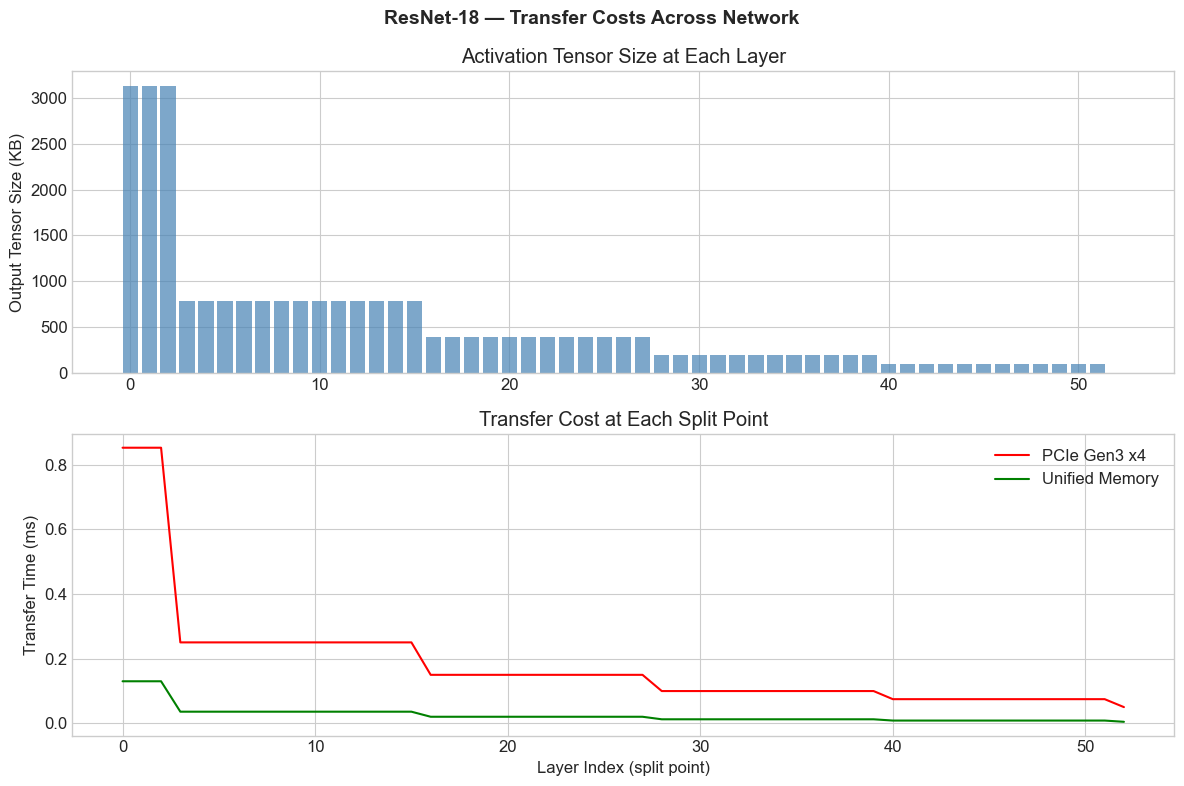


Summary:
  Min transfer cost (PCIe):     0.0505 ms
  Max transfer cost (PCIe):     0.8528 ms
  Min transfer cost (Unified):  0.0051 ms
  Max transfer cost (Unified):  0.1304 ms
  GPU-only total inference:     13.38 ms
  Transfer cost range is 0.4% to 6.4% of GPU-only inference time

MobileNetV2 — Transfer Cost at Every Possible Split Point

--- Top 10 Cheapest Split Points (PCIe) ---
Split After                     Tensor Size    PCIe (ms) Unified (ms)
----------------------------------------------------------------------
avgpool                               5.0 KB     0.0513     0.0052
block15_project_bn                   10.0 KB     0.0526     0.0054
block13_project                      10.0 KB     0.0526     0.0054
block15_project                      10.0 KB     0.0526     0.0054
block14_project_bn                   10.0 KB     0.0526     0.0054
block14_project                      10.0 KB     0.0526     0.0054
block13_project_bn                   10.0 KB     0.0526     0.0054
bl

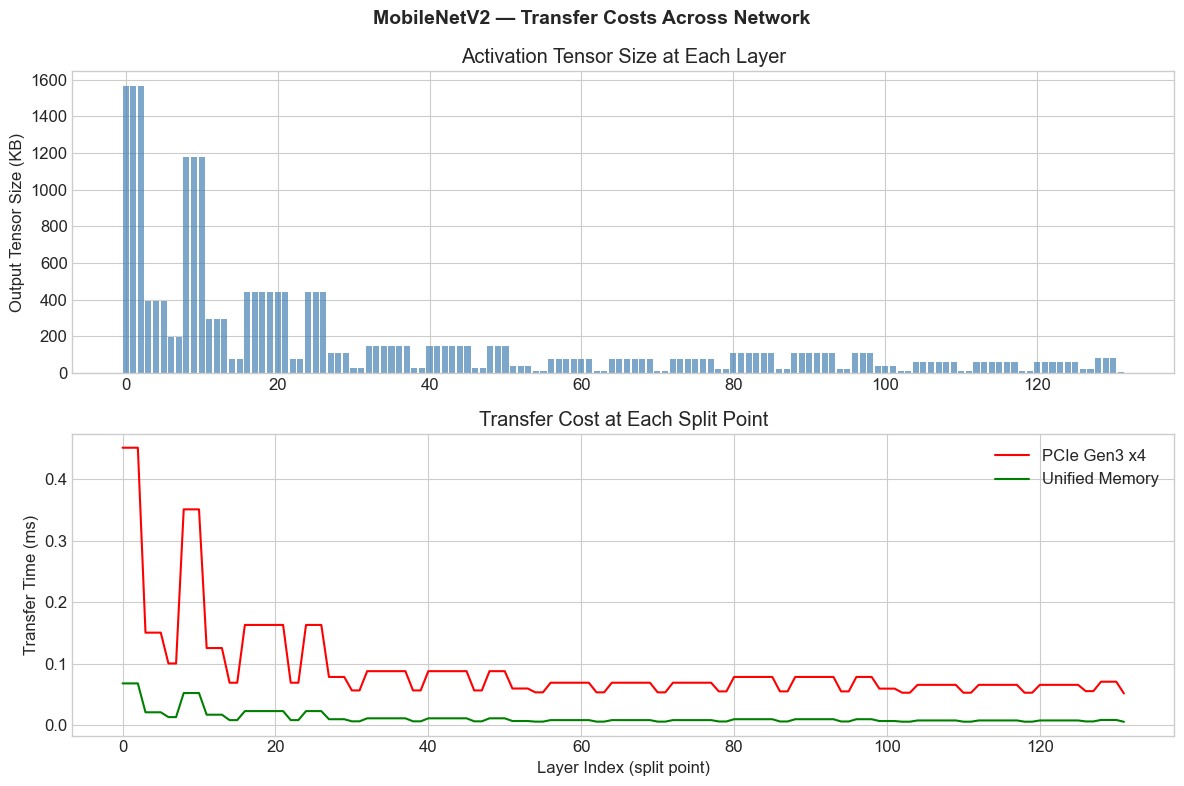


Summary:
  Min transfer cost (PCIe):     0.0513 ms
  Max transfer cost (PCIe):     0.4514 ms
  Min transfer cost (Unified):  0.0052 ms
  Max transfer cost (Unified):  0.0677 ms
  GPU-only total inference:     2.42 ms
  Transfer cost range is 2.1% to 18.7% of GPU-only inference time


In [6]:
# Cell 5 — Transfer Cost Model

@dataclass
class TransferProfile:
    """Models the cost of moving data between GPU and FPGA."""
    bandwidth_gbps: float       # Effective transfer bandwidth (GB/s)
    latency_overhead_us: float  # Fixed per-transfer setup latency (microseconds)
    is_unified_memory: bool     # If True, no copy needed — just pointer passing

# Profile options for different hardware configurations
pcie_transfer = TransferProfile(
    bandwidth_gbps=4.0,         # PCIe Gen 3 x4 effective (typical for edge boards)
    latency_overhead_us=50.0,   # DMA setup + synchronization overhead
    is_unified_memory=False
)

unified_memory_transfer = TransferProfile(
    bandwidth_gbps=25.6,        # Shared DRAM bandwidth (e.g., Zynq SoC with shared DDR4)
    latency_overhead_us=5.0,    # Minimal overhead — cache flush + pointer handoff
    is_unified_memory=True
)

# Default to PCIe for conservative estimates
active_transfer_profile = pcie_transfer


def compute_transfer_time(tensor_size_bytes: int, profile: TransferProfile = None) -> float:
    """Compute transfer time in seconds for a given tensor size.
    
    Args:
        tensor_size_bytes: Size of activation tensor to transfer
        profile: Transfer profile to use (defaults to active profile)
    
    Returns:
        Transfer time in seconds
    """
    if profile is None:
        profile = active_transfer_profile
    
    # Fixed setup latency
    setup_time = profile.latency_overhead_us * 1e-6
    
    # Bandwidth-dependent transfer time
    bulk_transfer_time = (tensor_size_bytes / 1e9) / profile.bandwidth_gbps
    
    return setup_time + bulk_transfer_time


def compute_transfer_at_layer(layers: List[Layer], split_idx: int, 
                               profile: TransferProfile = None) -> float:
    """Compute transfer cost at a specific split point.
    
    The split happens AFTER layer at split_idx, so we transfer
    that layer's output tensor to the next device.
    
    Args:
        layers: Full list of network layers
        split_idx: Index of the last layer before the split
        profile: Transfer profile to use
    
    Returns:
        Transfer time in seconds
    """
    tensor_bytes = layers[split_idx].output_tensor_size_bytes
    return compute_transfer_time(tensor_bytes, profile)


# Analyze transfer costs at every possible split point for both architectures
for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified)]:
    layers = builder()
    
    print(f"\n{'='*90}")
    print(f"{arch_name} — Transfer Cost at Every Possible Split Point")
    print(f"{'='*90}")
    
    split_times_pcie = []
    split_times_unified = []
    split_tensor_sizes = []
    
    for i in range(len(layers) - 1):
        t_pcie = compute_transfer_at_layer(layers, i, pcie_transfer)
        t_unified = compute_transfer_at_layer(layers, i, unified_memory_transfer)
        tensor_kb = layers[i].output_tensor_size_bytes / 1024
        
        split_times_pcie.append(t_pcie)
        split_times_unified.append(t_unified)
        split_tensor_sizes.append(tensor_kb)
    
    # Show the 10 cheapest and 5 most expensive split points
    sorted_indices = np.argsort(split_times_pcie)
    
    print(f"\n--- Top 10 Cheapest Split Points (PCIe) ---")
    print(f"{'Split After':<30} {'Tensor Size':>12} {'PCIe (ms)':>12} {'Unified (ms)':>12}")
    print(f"{'-'*70}")
    for idx in sorted_indices[:10]:
        print(f"{layers[idx].name:<30} {split_tensor_sizes[idx]:>10.1f} KB "
              f"{split_times_pcie[idx]*1000:>10.4f} {split_times_unified[idx]*1000:>10.4f}")
    
    print(f"\n--- Top 5 Most Expensive Split Points (PCIe) ---")
    print(f"{'Split After':<30} {'Tensor Size':>12} {'PCIe (ms)':>12} {'Unified (ms)':>12}")
    print(f"{'-'*70}")
    for idx in sorted_indices[-5:]:
        print(f"{layers[idx].name:<30} {split_tensor_sizes[idx]:>10.1f} KB "
              f"{split_times_pcie[idx]*1000:>10.4f} {split_times_unified[idx]*1000:>10.4f}")
    
    # Plot transfer cost across the network
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))
    fig.suptitle(f"{arch_name} — Transfer Costs Across Network", fontsize=14, fontweight='bold')
    
    x = range(len(split_times_pcie))
    
    ax1.bar(x, split_tensor_sizes, color='steelblue', alpha=0.7)
    ax1.set_ylabel("Output Tensor Size (KB)")
    ax1.set_title("Activation Tensor Size at Each Layer")
    
    ax2.plot(x, [t * 1000 for t in split_times_pcie], 'r-', linewidth=1.5, label='PCIe Gen3 x4')
    ax2.plot(x, [t * 1000 for t in split_times_unified], 'g-', linewidth=1.5, label='Unified Memory')
    ax2.set_ylabel("Transfer Time (ms)")
    ax2.set_xlabel("Layer Index (split point)")
    ax2.set_title("Transfer Cost at Each Split Point")
    ax2.legend()
    
    plt.tight_layout()
    plt.savefig(f"{arch_name.replace('-','')}_transfer_costs.png", dpi=150, bbox_inches='tight')
    plt.show()
    
    print(f"\nSummary:")
    print(f"  Min transfer cost (PCIe):     {min(split_times_pcie)*1000:.4f} ms")
    print(f"  Max transfer cost (PCIe):     {max(split_times_pcie)*1000:.4f} ms")
    print(f"  Min transfer cost (Unified):  {min(split_times_unified)*1000:.4f} ms")
    print(f"  Max transfer cost (Unified):  {max(split_times_unified)*1000:.4f} ms")
    print(f"  GPU-only total inference:     {sum(estimate_all_layers(layers, gpu_profile))*1000:.2f} ms")
    print(f"  Transfer cost range is {min(split_times_pcie)/sum(estimate_all_layers(layers, gpu_profile))*100:.1f}% "
          f"to {max(split_times_pcie)/sum(estimate_all_layers(layers, gpu_profile))*100:.1f}% of GPU-only inference time")

In [7]:
# Cell 6 — Operator Fusion and Compression Model

# ============================================================================
# FUSION RULES
# ============================================================================
# Define which consecutive layer patterns can be fused into single operators.
# Fusion eliminates intermediate memory reads/writes between layers.

FUSIBLE_PATTERNS = [
    # (pattern_name, layer_type_sequence)
    ("conv_bn_relu",   [LayerType.CONV, LayerType.BATCHNORM, LayerType.RELU]),
    ("dw_bn_relu",     [LayerType.DEPTHWISE_CONV, LayerType.BATCHNORM, LayerType.RELU]),
    ("pw_bn_relu",     [LayerType.POINTWISE_CONV, LayerType.BATCHNORM, LayerType.RELU]),
    ("conv_bn",        [LayerType.CONV, LayerType.BATCHNORM]),
    ("dw_bn",          [LayerType.DEPTHWISE_CONV, LayerType.BATCHNORM]),
    ("pw_bn",          [LayerType.POINTWISE_CONV, LayerType.BATCHNORM]),
]

@dataclass
class FusedBlock:
    """Represents a group of consecutive layers fused into a single operator."""
    name: str
    pattern: str                    # Which fusion pattern was applied
    layers: List[Layer]             # Original layers in this block
    
    @property
    def total_flops(self) -> int:
        return sum(l.flops for l in self.layers)
    
    @property
    def total_params(self) -> int:
        return sum(l.param_count for l in self.layers)
    
    @property
    def input_tensor_size_bytes(self) -> int:
        return self.layers[0].input_tensor_size_bytes
    
    @property
    def output_tensor_size_bytes(self) -> int:
        return self.layers[-1].output_tensor_size_bytes
    
    @property
    def dominant_layer_type(self) -> LayerType:
        """The compute-dominant layer type (first layer in the fused group)."""
        return self.layers[0].layer_type
    
    @property
    def intermediate_memory_saved(self) -> int:
        """Bytes of intermediate tensor reads/writes eliminated by fusion."""
        saved = 0
        for i in range(len(self.layers) - 1):
            # Each intermediate boundary saves a write + read
            saved += self.layers[i].output_tensor_size_bytes * 2
        return saved
    
    def __repr__(self):
        layer_names = " + ".join(l.name for l in self.layers)
        return (f"[{self.pattern}] {layer_names} | "
                f"FLOPs: {self.total_flops:>12,} | "
                f"Params: {self.total_params:>10,} | "
                f"Mem saved: {self.intermediate_memory_saved/1024:.1f} KB")


def apply_fusion(layers: List[Layer]) -> List:
    """Greedily apply fusion rules to a sequence of layers.
    
    Returns a mixed list of FusedBlock and Layer objects.
    Longer patterns are tried first (greedy longest match).
    """
    # Sort patterns by length (longest first) for greedy matching
    sorted_patterns = sorted(FUSIBLE_PATTERNS, key=lambda p: len(p[1]), reverse=True)
    
    result = []
    i = 0
    fused_count = 0
    
    while i < len(layers):
        matched = False
        
        for pattern_name, pattern_types in sorted_patterns:
            pat_len = len(pattern_types)
            
            if i + pat_len <= len(layers):
                # Check if the next layers match this pattern
                candidate = [layers[i + j] for j in range(pat_len)]
                if all(c.layer_type == pt for c, pt in zip(candidate, pattern_types)):
                    fused_count += 1
                    block = FusedBlock(
                        name=f"fused_{fused_count}_{pattern_name}",
                        pattern=pattern_name,
                        layers=candidate
                    )
                    result.append(block)
                    i += pat_len
                    matched = True
                    break
        
        if not matched:
            result.append(layers[i])
            i += 1
    
    return result


# ============================================================================
# FUSED BLOCK COST MODEL
# ============================================================================

# Fusion speedup factors — fusing eliminates intermediate memory accesses
# so the fused block runs faster than the sum of individual layers
FUSION_SPEEDUP = {
    "conv_bn_relu": 0.80,    # 20% savings from eliminating intermediate tensors
    "dw_bn_relu":   0.75,    # 25% savings — BN and ReLU are mostly memory ops
    "pw_bn_relu":   0.78,    # 22% savings
    "conv_bn":      0.85,    # 15% savings
    "dw_bn":        0.80,    # 20% savings
    "pw_bn":        0.83,    # 17% savings
}

# GPU overhead for preparing a fused operator (seconds)
# This is the "compilation" cost — analyzing layers, folding BN params, building fused kernel
FUSION_PREP_OVERHEAD_BASE = 0.05e-3   # 0.05 ms base overhead per fusion
FUSION_PREP_OVERHEAD_PER_PARAM = 1e-9  # Additional time proportional to parameters


def estimate_fused_block_time(block: FusedBlock, profile: DeviceProfile) -> float:
    """Estimate execution time for a fused block on a given device."""
    # Sum of individual layer times
    unfused_time = sum(estimate_layer_time(l, profile) for l in block.layers)
    
    # Apply fusion speedup
    speedup = FUSION_SPEEDUP.get(block.pattern, 1.0)
    return unfused_time * speedup


def estimate_fusion_prep_time(block: FusedBlock) -> float:
    """Estimate GPU-side time to prepare/compile a fused operator."""
    return FUSION_PREP_OVERHEAD_BASE + (block.total_params * FUSION_PREP_OVERHEAD_PER_PARAM)


# ============================================================================
# QLORA COMPRESSION MODEL
# ============================================================================

@dataclass
class CompressionConfig:
    """Configuration for LoRA/QLoRA compression of fused blocks."""
    lora_rank: int = 8           # Low-rank decomposition rank
    quantization_bits: int = 8   # Quantization bit-width (4, 8, or 32 for no quant)
    
    @property
    def quant_speedup_factor(self) -> float:
        """FPGA speedup from reduced-precision arithmetic."""
        # FPGA throughput scales roughly linearly with reduced bit-width
        if self.quantization_bits == 4:
            return 4.0    # 4x throughput vs FP32
        elif self.quantization_bits == 8:
            return 2.5    # 2.5x throughput vs FP32 (not full 4x due to overhead)
        return 1.0
    
    @property
    def transfer_compression_ratio(self) -> float:
        """How much the activation tensor shrinks for transfer."""
        return self.quantization_bits / 32.0


# Compression presets
NO_COMPRESSION = CompressionConfig(lora_rank=0, quantization_bits=32)
INT8_COMPRESSION = CompressionConfig(lora_rank=8, quantization_bits=8)
INT4_COMPRESSION = CompressionConfig(lora_rank=4, quantization_bits=4)


def estimate_compressed_fpga_time(block, fpga_profile: DeviceProfile, 
                                   config: CompressionConfig) -> float:
    """Estimate FPGA execution time with quantization speedup."""
    base_time = estimate_fused_block_time(block, fpga_profile)
    return base_time / config.quant_speedup_factor


def estimate_compressed_transfer_time(tensor_bytes: int, config: CompressionConfig,
                                       transfer_profile: TransferProfile = None) -> float:
    """Estimate transfer time with compressed activations."""
    compressed_bytes = int(tensor_bytes * config.transfer_compression_ratio)
    return compute_transfer_time(compressed_bytes, transfer_profile)


def lora_param_reduction(original_params: int, rank: int, 
                          in_dim: int, out_dim: int) -> Tuple[int, float]:
    """Compute parameter count after LoRA decomposition.
    
    Original: W (in_dim x out_dim) = original_params
    LoRA: A (in_dim x rank) + B (rank x out_dim) = rank * (in_dim + out_dim)
    
    Returns: (new_param_count, compression_ratio)
    """
    if rank == 0 or rank >= min(in_dim, out_dim):
        return original_params, 1.0
    
    lora_params = rank * (in_dim + out_dim)
    ratio = lora_params / original_params if original_params > 0 else 1.0
    return lora_params, ratio


# ============================================================================
# ANALYSIS — Apply fusion to both architectures
# ============================================================================

for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified)]:
    layers = builder()
    fused = apply_fusion(layers)
    
    n_fused_blocks = sum(1 for f in fused if isinstance(f, FusedBlock))
    n_unfused = sum(1 for f in fused if isinstance(f, Layer))
    total_layers_fused = sum(len(f.layers) for f in fused if isinstance(f, FusedBlock))
    
    print(f"\n{'='*100}")
    print(f"{arch_name} — Fusion Analysis")
    print(f"{'='*100}")
    print(f"Original: {len(layers)} layers → {len(fused)} blocks ({n_fused_blocks} fused + {n_unfused} unfused)")
    print(f"Layers absorbed into fused blocks: {total_layers_fused}")
    
    # Cost comparison: unfused vs fused on both devices
    print(f"\n{'Block':<45} {'GPU unfused':>12} {'GPU fused':>12} {'FPGA unfused':>12} {'FPGA fused':>12} {'FPGA+INT8':>12}")
    print(f"{'-'*110}")
    
    total_gpu_unfused = 0
    total_gpu_fused = 0
    total_fpga_unfused = 0
    total_fpga_fused = 0
    total_fpga_int8 = 0
    total_mem_saved = 0
    
    for block in fused:
        if isinstance(block, FusedBlock):
            gpu_unfused = sum(estimate_layer_time(l, gpu_profile) for l in block.layers)
            gpu_fused = estimate_fused_block_time(block, gpu_profile)
            fpga_unfused = sum(estimate_layer_time(l, fpga_profile) for l in block.layers)
            fpga_fused = estimate_fused_block_time(block, fpga_profile)
            fpga_int8 = estimate_compressed_fpga_time(block, fpga_profile, INT8_COMPRESSION)
            total_mem_saved += block.intermediate_memory_saved
            
            name = block.name
        else:
            gpu_unfused = estimate_layer_time(block, gpu_profile)
            gpu_fused = gpu_unfused
            fpga_unfused = estimate_layer_time(block, fpga_profile)
            fpga_fused = fpga_unfused
            fpga_int8 = fpga_unfused  # No compression benefit for unfused single layers
            
            name = block.name
        
        total_gpu_unfused += gpu_unfused
        total_gpu_fused += gpu_fused
        total_fpga_unfused += fpga_unfused
        total_fpga_fused += fpga_fused
        total_fpga_int8 += fpga_int8
        
        print(f"{name:<45} {gpu_unfused*1000:>10.4f}ms {gpu_fused*1000:>10.4f}ms "
              f"{fpga_unfused*1000:>10.4f}ms {fpga_fused*1000:>10.4f}ms {fpga_int8*1000:>10.4f}ms")
    
    print(f"{'-'*110}")
    print(f"{'TOTAL':<45} {total_gpu_unfused*1000:>10.2f}ms {total_gpu_fused*1000:>10.2f}ms "
          f"{total_fpga_unfused*1000:>10.2f}ms {total_fpga_fused*1000:>10.2f}ms {total_fpga_int8*1000:>10.2f}ms")
    
    print(f"\nFusion savings (GPU):  {(1 - total_gpu_fused/total_gpu_unfused)*100:.1f}%")
    print(f"Fusion savings (FPGA): {(1 - total_fpga_fused/total_fpga_unfused)*100:.1f}%")
    print(f"Fusion + INT8 savings (FPGA): {(1 - total_fpga_int8/total_fpga_unfused)*100:.1f}%")
    print(f"Total intermediate memory eliminated: {total_mem_saved/1024:.1f} KB")
    print(f"\nFPGA+INT8 vs GPU-fused ratio: {total_fpga_int8/total_gpu_fused:.1f}x")


ResNet-18 — Fusion Analysis
Original: 54 layers → 20 blocks (17 fused + 3 unfused)
Layers absorbed into fused blocks: 51

Block                                          GPU unfused    GPU fused FPGA unfused   FPGA fused    FPGA+INT8
--------------------------------------------------------------------------------------------------------------
fused_1_conv_bn_relu                              1.2711ms     1.0169ms    83.7518ms    67.0014ms    26.8006ms
maxpool                                           0.1568ms     0.1568ms     0.9557ms     0.9557ms     0.9557ms
fused_2_conv_bn_relu                              0.8791ms     0.7033ms    79.8112ms    63.8490ms    25.5396ms
fused_3_conv_bn_relu                              0.8791ms     0.7033ms    79.8112ms    63.8490ms    25.5396ms
fused_4_conv_bn_relu                              0.8791ms     0.7033ms    79.8112ms    63.8490ms    25.5396ms
fused_5_conv_bn_relu                              0.8791ms     0.7033ms    79.8112ms    63.8490ms   


ResNet-18 — Partition Optimization Results
GPU-only baseline: 10.75 ms | 93.0 inf/s | 6.20 inf/s/W

  --- No compression (FP32) | PCIe Transfer ---
  Best throughput split: after block 17 (fused_17_conv_bn_relu)
  GPU blocks:            18 | FPGA blocks: 2
  GPU stage:             10.6693 ms (+ 0.0000 ms prep)
  FPGA stage:            0.5134 ms (+ 0.0751 ms transfer)
  Pipeline bottleneck:   10.6693 ms
  Pipeline efficiency:   5.5%
  Throughput:            93.7 inf/s (+0.8% vs GPU-only)

  --- No compression (FP32) | Unified Transfer ---
  Best throughput split: after block 17 (fused_17_conv_bn_relu)
  GPU blocks:            18 | FPGA blocks: 2
  GPU stage:             10.6693 ms (+ 0.0000 ms prep)
  FPGA stage:            0.5134 ms (+ 0.0089 ms transfer)
  Pipeline bottleneck:   10.6693 ms
  Pipeline efficiency:   4.9%
  Throughput:            93.7 inf/s (+0.8% vs GPU-only)

  --- INT8 compression | PCIe Transfer ---
  Best throughput split: after block 17 (fused_17_conv_bn_relu)
  G

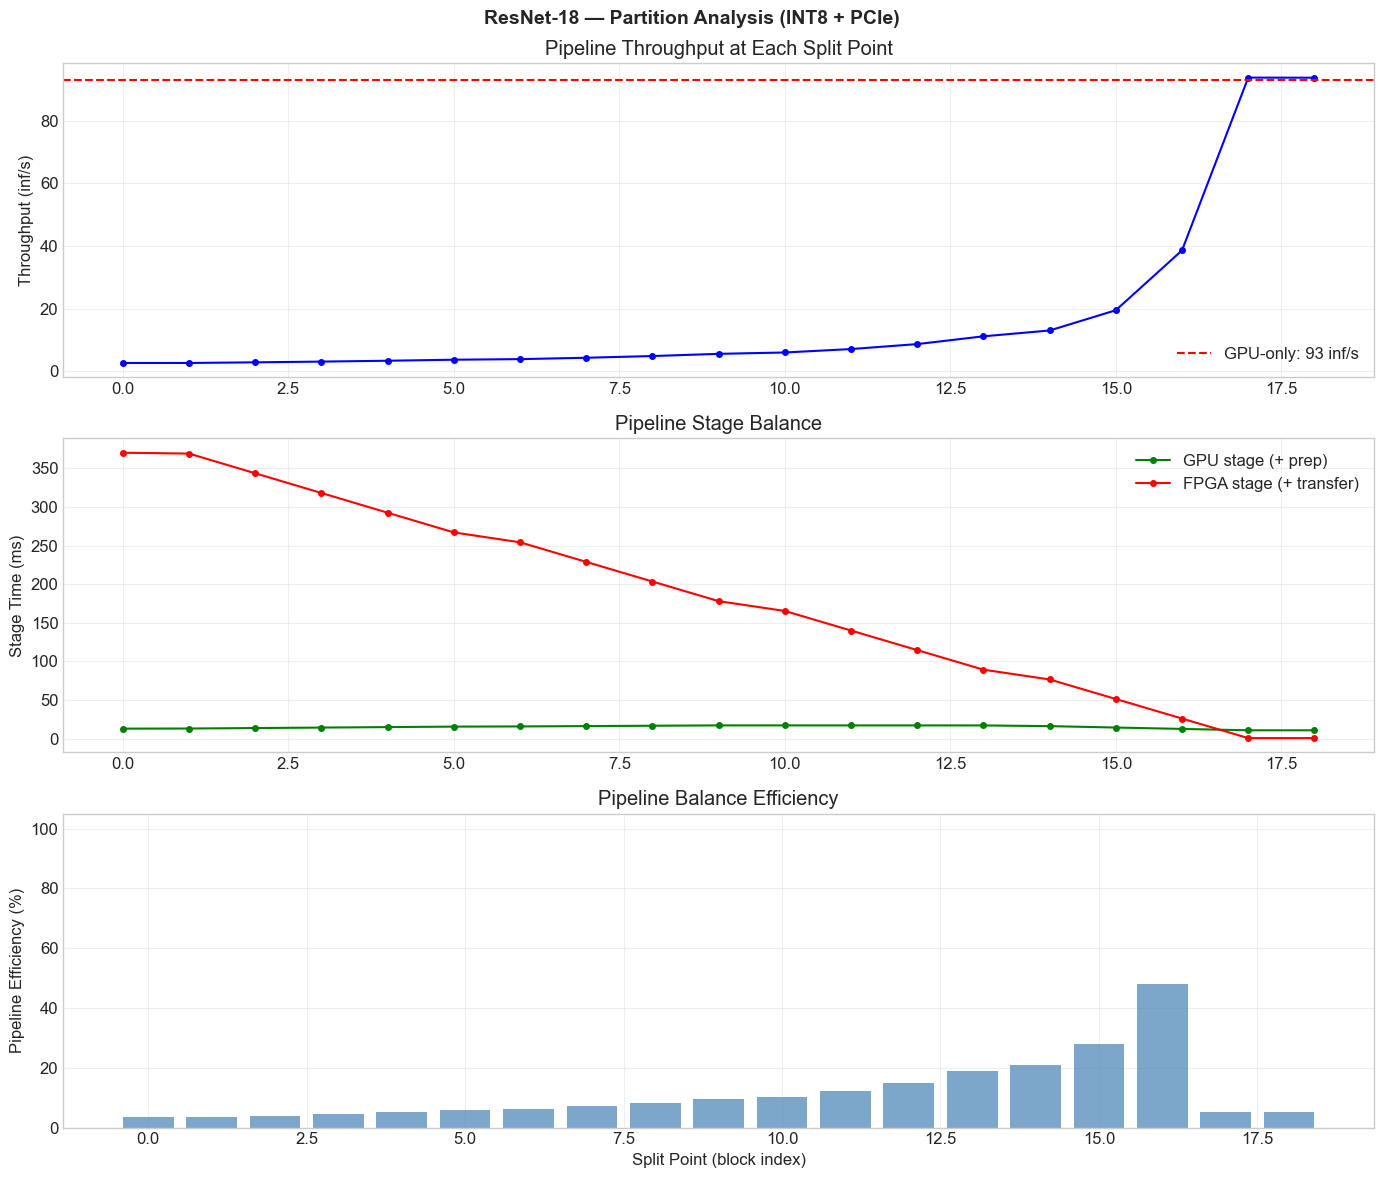


MobileNetV2 — Partition Optimization Results
GPU-only baseline: 1.93 ms | 517.3 inf/s | 34.49 inf/s/W

  --- No compression (FP32) | PCIe Transfer ---
  Best throughput split: after block 48 (fused_49_pw_bn_relu)
  GPU blocks:            49 | FPGA blocks: 2
  GPU stage:             1.7294 ms (+ 0.0000 ms prep)
  FPGA stage:            1.2419 ms (+ 0.0705 ms transfer)
  Pipeline bottleneck:   1.7294 ms
  Pipeline efficiency:   75.9%
  Throughput:            578.2 inf/s (+11.8% vs GPU-only)

  --- No compression (FP32) | Unified Transfer ---
  Best throughput split: after block 48 (fused_49_pw_bn_relu)
  GPU blocks:            49 | FPGA blocks: 2
  GPU stage:             1.7294 ms (+ 0.0000 ms prep)
  FPGA stage:            1.2419 ms (+ 0.0082 ms transfer)
  Pipeline bottleneck:   1.7294 ms
  Pipeline efficiency:   72.3%
  Throughput:            578.2 inf/s (+11.8% vs GPU-only)

  --- INT8 compression | PCIe Transfer ---
  Best throughput split: after block 48 (fused_49_pw_bn_relu)
  GP

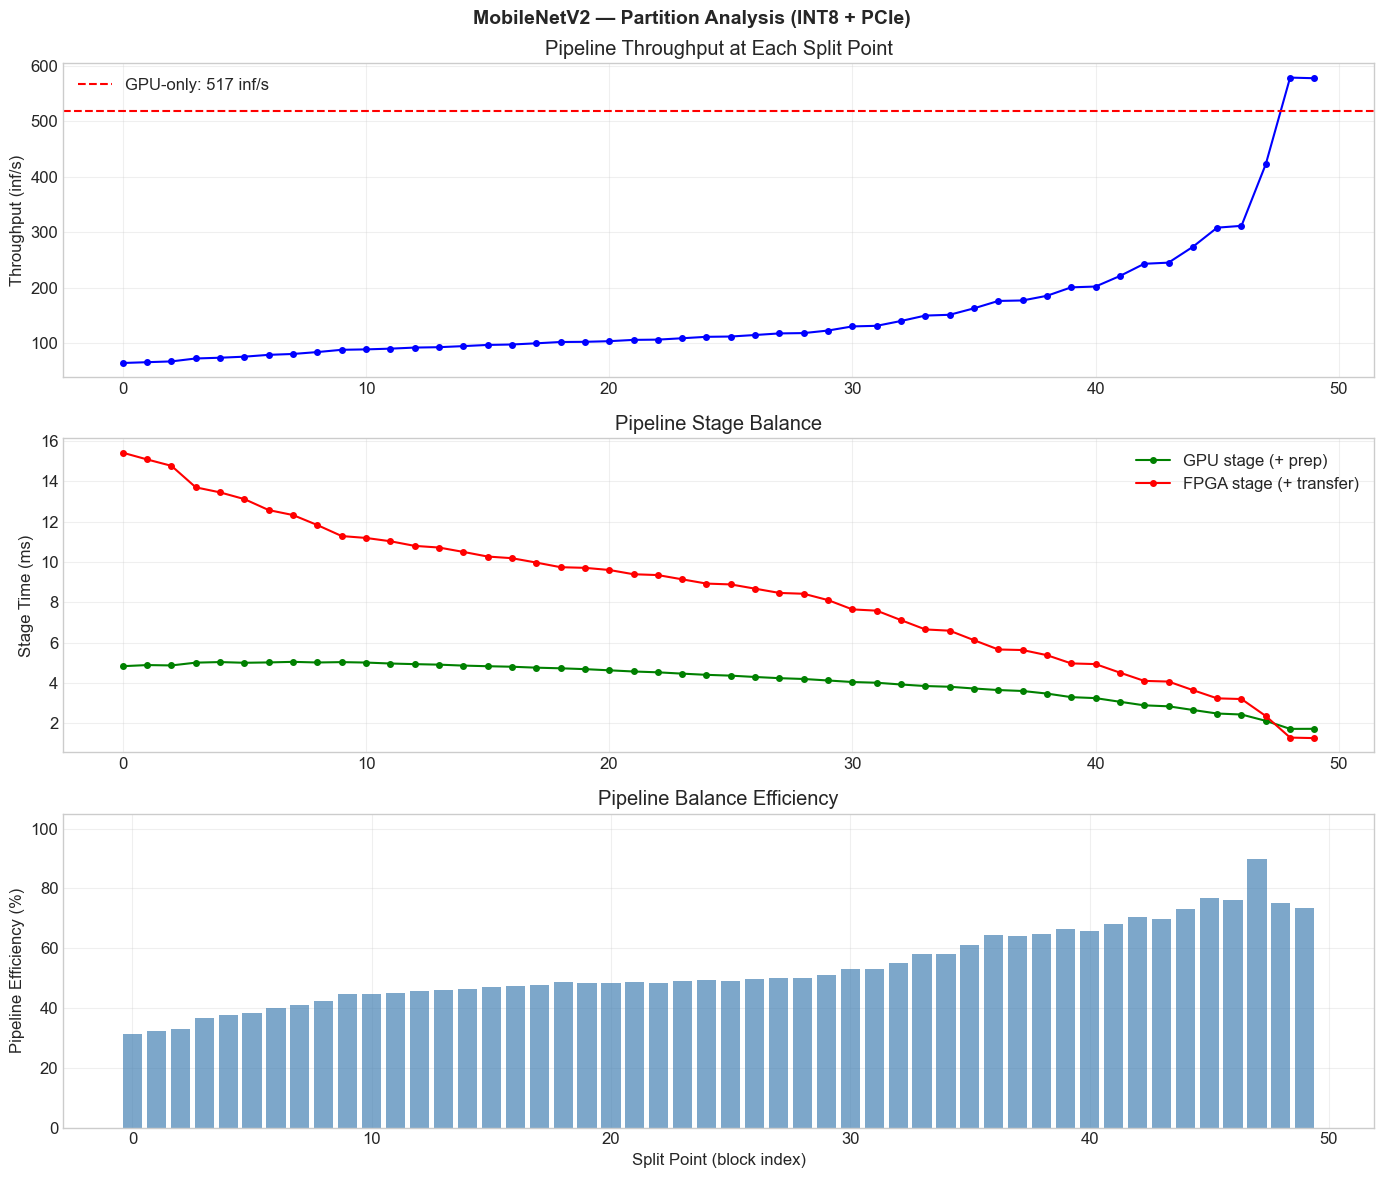

In [8]:
# Cell 7 — Partition Optimizer

@dataclass
class PartitionResult:
    """Stores the result of a single partition configuration."""
    split_idx: int                      # Split point in the fused block list (-1 = GPU-only)
    gpu_blocks: List                     # Blocks assigned to GPU
    fpga_blocks: List                    # Blocks assigned to FPGA
    gpu_stage_time: float               # Total GPU stage execution time (seconds)
    fpga_stage_time: float              # Total FPGA stage execution time (seconds)
    transfer_time: float                # Transfer cost at the split boundary (seconds)
    fusion_prep_time: float             # GPU overhead for preparing FPGA's fused blocks (seconds)
    compression: CompressionConfig      # Compression config used for FPGA blocks
    
    @property
    def single_inference_latency(self) -> float:
        """Total latency for a single inference (sequential)."""
        if not self.fpga_blocks:
            return self.gpu_stage_time
        return self.gpu_stage_time + self.transfer_time + self.fpga_stage_time
    
    @property
    def pipeline_bottleneck(self) -> float:
        """The slower stage — determines pipeline throughput."""
        if not self.fpga_blocks:
            return self.gpu_stage_time
        # GPU stage includes fusion prep time for FPGA blocks
        effective_gpu_time = self.gpu_stage_time + self.fusion_prep_time
        # FPGA stage includes receiving the transfer
        effective_fpga_time = self.fpga_stage_time + self.transfer_time
        return max(effective_gpu_time, effective_fpga_time)
    
    @property
    def pipeline_throughput(self) -> float:
        """Inferences per second in steady-state pipeline."""
        return 1.0 / self.pipeline_bottleneck if self.pipeline_bottleneck > 0 else 0
    
    @property
    def pipeline_efficiency(self) -> float:
        """How well-balanced the pipeline is (1.0 = perfect balance)."""
        if not self.fpga_blocks:
            return 1.0
        effective_gpu = self.gpu_stage_time + self.fusion_prep_time
        effective_fpga = self.fpga_stage_time + self.transfer_time
        slower = max(effective_gpu, effective_fpga)
        faster = min(effective_gpu, effective_fpga)
        return faster / slower if slower > 0 else 0
    
    @property
    def total_power(self) -> float:
        """Total power consumption (watts)."""
        if not self.fpga_blocks:
            return GPU_POWER
        return GPU_POWER + FPGA_POWER
    
    @property
    def throughput_per_watt(self) -> float:
        """Inferences per second per watt."""
        return self.pipeline_throughput / self.total_power


def get_block_time(block, profile: DeviceProfile, compression: CompressionConfig = None) -> float:
    """Get execution time for a block (fused or unfused) on a device."""
    if isinstance(block, FusedBlock):
        if compression and compression.quantization_bits < 32 and profile == fpga_profile:
            return estimate_compressed_fpga_time(block, profile, compression)
        return estimate_fused_block_time(block, profile)
    else:
        return estimate_layer_time(block, profile)


def get_block_output_bytes(block) -> int:
    """Get output tensor size for a block (fused or unfused)."""
    if isinstance(block, FusedBlock):
        return block.output_tensor_size_bytes
    else:
        return block.output_tensor_size_bytes


def evaluate_partition(fused_blocks: List, split_idx: int,
                       compression: CompressionConfig = NO_COMPRESSION,
                       transfer_profile: TransferProfile = None) -> PartitionResult:
    """Evaluate a single partition configuration.
    
    Blocks 0..split_idx run on GPU, blocks split_idx+1..end run on FPGA.
    split_idx = -1 means all blocks on GPU (baseline).
    split_idx = len-1 means all blocks on GPU (same as -1 since nothing left for FPGA).
    """
    n = len(fused_blocks)
    
    if split_idx < 0 or split_idx >= n - 1:
        # GPU-only: all blocks on GPU
        gpu_time = sum(get_block_time(b, gpu_profile) for b in fused_blocks)
        return PartitionResult(
            split_idx=-1, gpu_blocks=fused_blocks, fpga_blocks=[],
            gpu_stage_time=gpu_time, fpga_stage_time=0,
            transfer_time=0, fusion_prep_time=0, compression=compression
        )
    
    gpu_blocks = fused_blocks[:split_idx + 1]
    fpga_blocks = fused_blocks[split_idx + 1:]
    
    # GPU stage time
    gpu_time = sum(get_block_time(b, gpu_profile) for b in gpu_blocks)
    
    # FPGA stage time (with compression if configured)
    fpga_time = sum(get_block_time(b, fpga_profile, compression) for b in fpga_blocks)
    
    # Transfer cost at the split boundary
    boundary_tensor_bytes = get_block_output_bytes(fused_blocks[split_idx])
    if compression.quantization_bits < 32:
        xfer_time = estimate_compressed_transfer_time(boundary_tensor_bytes, compression, transfer_profile)
    else:
        xfer_time = compute_transfer_time(boundary_tensor_bytes, transfer_profile)
    
    # Fusion prep overhead — GPU prepares fused operators for FPGA
    prep_time = sum(estimate_fusion_prep_time(b) for b in fpga_blocks if isinstance(b, FusedBlock))
    
    return PartitionResult(
        split_idx=split_idx, gpu_blocks=gpu_blocks, fpga_blocks=fpga_blocks,
        gpu_stage_time=gpu_time, fpga_stage_time=fpga_time,
        transfer_time=xfer_time, fusion_prep_time=prep_time, compression=compression
    )


def find_optimal_partition(fused_blocks: List,
                           compression: CompressionConfig = NO_COMPRESSION,
                           transfer_profile: TransferProfile = None,
                           optimize_for: str = "throughput") -> Tuple[PartitionResult, List[PartitionResult]]:
    """Search all possible single-split partitions and find the optimal one.
    
    Args:
        fused_blocks: List of fused/unfused blocks
        compression: Compression config for FPGA blocks
        transfer_profile: Transfer profile to use
        optimize_for: "throughput" (max inf/s), "latency" (min single inference), 
                       or "throughput_per_watt" (max inf/s/W)
    
    Returns:
        (best_result, all_results)
    """
    all_results = []
    
    # GPU-only baseline
    baseline = evaluate_partition(fused_blocks, -1, compression, transfer_profile)
    all_results.append(baseline)
    
    # Try every possible split point
    for split_idx in range(len(fused_blocks) - 1):
        result = evaluate_partition(fused_blocks, split_idx, compression, transfer_profile)
        all_results.append(result)
    
    # Find optimal based on criteria
    if optimize_for == "throughput":
        best = max(all_results, key=lambda r: r.pipeline_throughput)
    elif optimize_for == "latency":
        best = min(all_results, key=lambda r: r.single_inference_latency)
    elif optimize_for == "throughput_per_watt":
        best = max(all_results, key=lambda r: r.throughput_per_watt)
    else:
        best = max(all_results, key=lambda r: r.pipeline_throughput)
    
    return best, all_results


# ============================================================================
# Run optimizer on both architectures with different configurations
# ============================================================================

configs = [
    ("No compression (FP32)",   NO_COMPRESSION),
    ("INT8 compression",        INT8_COMPRESSION),
    ("INT4 compression",        INT4_COMPRESSION),
]

for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified)]:
    layers = builder()
    fused_blocks = apply_fusion(layers)
    
    # GPU-only baseline
    gpu_only_time = sum(get_block_time(b, gpu_profile) for b in fused_blocks)
    gpu_only_throughput = 1.0 / gpu_only_time
    gpu_only_tpw = gpu_only_throughput / GPU_POWER
    
    print(f"\n{'='*110}")
    print(f"{arch_name} — Partition Optimization Results")
    print(f"{'='*110}")
    print(f"GPU-only baseline: {gpu_only_time*1000:.2f} ms | {gpu_only_throughput:.1f} inf/s | {gpu_only_tpw:.2f} inf/s/W")
    
    for config_name, compression in configs:
        for xfer_name, xfer_profile in [("PCIe", pcie_transfer), ("Unified", unified_memory_transfer)]:
            best, all_results = find_optimal_partition(
                fused_blocks, compression, xfer_profile, optimize_for="throughput"
            )
            
            # Also find best for throughput-per-watt
            best_tpw, _ = find_optimal_partition(
                fused_blocks, compression, xfer_profile, optimize_for="throughput_per_watt"
            )
            
            print(f"\n  --- {config_name} | {xfer_name} Transfer ---")
            
            if best.split_idx < 0:
                print(f"  Best throughput:       GPU-only (no beneficial split found)")
                print(f"  Throughput:            {best.pipeline_throughput:.1f} inf/s")
            else:
                split_block_name = fused_blocks[best.split_idx].name if hasattr(fused_blocks[best.split_idx], 'name') else str(best.split_idx)
                print(f"  Best throughput split: after block {best.split_idx} ({split_block_name})")
                print(f"  GPU blocks:            {len(best.gpu_blocks)} | FPGA blocks: {len(best.fpga_blocks)}")
                print(f"  GPU stage:             {best.gpu_stage_time*1000:.4f} ms (+ {best.fusion_prep_time*1000:.4f} ms prep)")
                print(f"  FPGA stage:            {best.fpga_stage_time*1000:.4f} ms (+ {best.transfer_time*1000:.4f} ms transfer)")
                print(f"  Pipeline bottleneck:   {best.pipeline_bottleneck*1000:.4f} ms")
                print(f"  Pipeline efficiency:   {best.pipeline_efficiency*100:.1f}%")
                print(f"  Throughput:            {best.pipeline_throughput:.1f} inf/s "
                      f"({'+'if best.pipeline_throughput > gpu_only_throughput else ''}"
                      f"{(best.pipeline_throughput/gpu_only_throughput - 1)*100:.1f}% vs GPU-only)")
            
            if best_tpw.split_idx >= 0:
                print(f"  Best throughput/watt:  {best_tpw.throughput_per_watt:.2f} inf/s/W "
                      f"({'+'if best_tpw.throughput_per_watt > gpu_only_tpw else ''}"
                      f"{(best_tpw.throughput_per_watt/gpu_only_tpw - 1)*100:.1f}% vs GPU-only)")
    
    # Detailed plot for best configuration
    print(f"\n  --- Throughput vs Split Point (INT8 + PCIe) ---")
    _, all_results = find_optimal_partition(fused_blocks, INT8_COMPRESSION, pcie_transfer)
    
    split_indices = []
    throughputs = []
    efficiencies = []
    gpu_stages = []
    fpga_stages = []
    
    for r in all_results:
        if r.split_idx < 0:
            continue
        split_indices.append(r.split_idx)
        throughputs.append(r.pipeline_throughput)
        efficiencies.append(r.pipeline_efficiency * 100)
        gpu_stages.append((r.gpu_stage_time + r.fusion_prep_time) * 1000)
        fpga_stages.append((r.fpga_stage_time + r.transfer_time) * 1000)
    
    fig, axes = plt.subplots(3, 1, figsize=(14, 12))
    fig.suptitle(f"{arch_name} — Partition Analysis (INT8 + PCIe)", fontsize=14, fontweight='bold')
    
    # Throughput vs split point
    axes[0].plot(split_indices, throughputs, 'b-o', markersize=4, linewidth=1.5)
    axes[0].axhline(y=gpu_only_throughput, color='r', linestyle='--', label=f'GPU-only: {gpu_only_throughput:.0f} inf/s')
    axes[0].set_ylabel("Throughput (inf/s)")
    axes[0].set_title("Pipeline Throughput at Each Split Point")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Stage times — shows pipeline balance
    axes[1].plot(split_indices, gpu_stages, 'g-o', markersize=4, linewidth=1.5, label='GPU stage (+ prep)')
    axes[1].plot(split_indices, fpga_stages, 'r-o', markersize=4, linewidth=1.5, label='FPGA stage (+ transfer)')
    axes[1].set_ylabel("Stage Time (ms)")
    axes[1].set_title("Pipeline Stage Balance")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    # Pipeline efficiency
    axes[2].bar(split_indices, efficiencies, color='steelblue', alpha=0.7)
    axes[2].set_ylabel("Pipeline Efficiency (%)")
    axes[2].set_xlabel("Split Point (block index)")
    axes[2].set_title("Pipeline Balance Efficiency")
    axes[2].set_ylim(0, 105)
    axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(f"{arch_name.replace('-','')}_partition_analysis.png", dpi=150, bbox_inches='tight')
    plt.show()


ResNet-18 — Complete Baseline Comparison
Strategy                        Latency (ms)    Throughput  Power (W)    Tput/Watt  vs GPU-fused  Efficiency
----------------------------------------------------------------------------------------------------------------------------------
GPU-only (unfused)                   13.38ms       74.7/s      15.0       4.98/s/W        -19.6%           —
GPU-only (fused)                     10.75ms       93.0/s      15.0       6.20/s/W         +0.0%           —
FPGA-only (unfused, FP32)          1237.14ms        0.8/s       5.0       0.16/s/W        -99.1%           —
FPGA-only (fused, INT8)             396.88ms        2.5/s       5.0       0.50/s/W        -97.3%           —
Hetero (FP32, PCIe)                  11.26ms       93.7/s      20.0       4.69/s/W         +0.8%          6%
Hetero (INT8, PCIe)                  11.24ms       93.7/s      20.0       4.69/s/W         +0.8%          5%
Hetero (INT4, PCIe)                  11.24ms       93.7/s      2

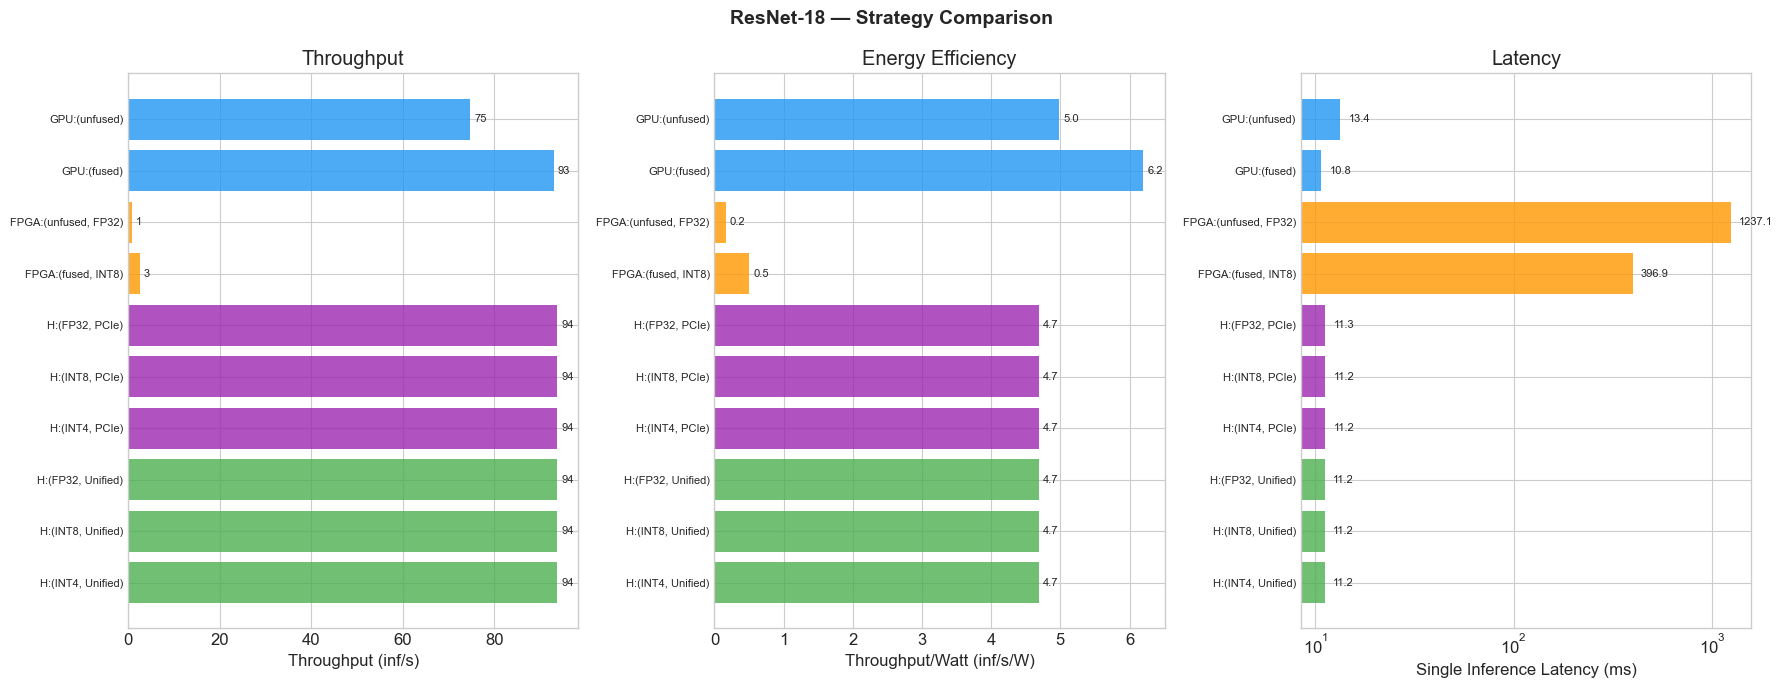

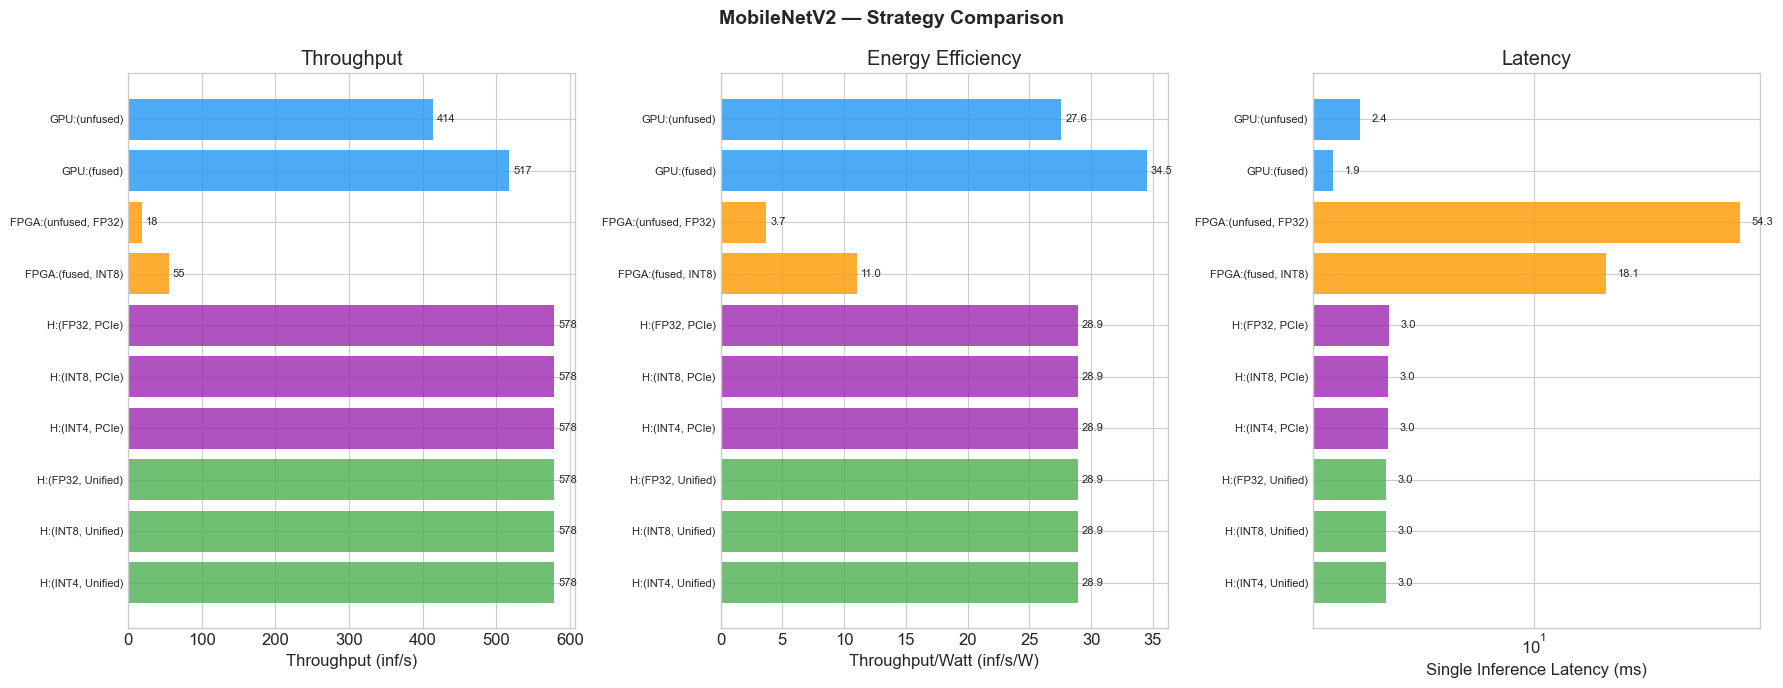


SUMMARY — Best Heterogeneous vs Best Single-Device

  ResNet-18:
    Best GPU-only:             93.0 inf/s | 6.20 inf/s/W | GPU-only (fused)
    Best FPGA-only:             2.5 inf/s | 0.50 inf/s/W | FPGA-only (fused, INT8)
    Best Hetero (tput):        93.7 inf/s | 4.69 inf/s/W | Hetero (FP32, PCIe)
    Best Hetero (tput/W):      93.7 inf/s | 4.69 inf/s/W | Hetero (FP32, PCIe)

    Throughput gain over GPU-only:      +0.8%
    Efficiency gain over GPU-only:      -24.4%

  MobileNetV2:
    Best GPU-only:            517.3 inf/s | 34.49 inf/s/W | GPU-only (fused)
    Best FPGA-only:            55.1 inf/s | 11.03 inf/s/W | FPGA-only (fused, INT8)
    Best Hetero (tput):       578.2 inf/s | 28.91 inf/s/W | Hetero (FP32, PCIe)
    Best Hetero (tput/W):     578.2 inf/s | 28.91 inf/s/W | Hetero (FP32, PCIe)

    Throughput gain over GPU-only:      +11.8%
    Efficiency gain over GPU-only:      -16.2%


In [9]:
# Cell 8 — Baseline Comparisons

@dataclass
class BaselineResult:
    """Stores results for a complete execution strategy."""
    name: str
    architecture: str
    single_latency_ms: float
    throughput_infs: float
    power_watts: float
    throughput_per_watt: float
    split_info: str = ""
    pipeline_efficiency: float = 0.0

def run_all_baselines(arch_name: str, layers: List[Layer]) -> List[BaselineResult]:
    """Run all baseline and heterogeneous configurations for an architecture."""
    fused_blocks = apply_fusion(layers)
    results = []
    
    # ---- Baseline 1: GPU-only (unfused) ----
    gpu_unfused_time = sum(estimate_layer_time(l, gpu_profile) for l in layers)
    results.append(BaselineResult(
        name="GPU-only (unfused)",
        architecture=arch_name,
        single_latency_ms=gpu_unfused_time * 1000,
        throughput_infs=1.0 / gpu_unfused_time,
        power_watts=GPU_POWER,
        throughput_per_watt=(1.0 / gpu_unfused_time) / GPU_POWER,
        split_info="All layers on GPU, no fusion"
    ))
    
    # ---- Baseline 2: GPU-only (fused) ----
    gpu_fused_time = sum(get_block_time(b, gpu_profile) for b in fused_blocks)
    results.append(BaselineResult(
        name="GPU-only (fused)",
        architecture=arch_name,
        single_latency_ms=gpu_fused_time * 1000,
        throughput_infs=1.0 / gpu_fused_time,
        power_watts=GPU_POWER,
        throughput_per_watt=(1.0 / gpu_fused_time) / GPU_POWER,
        split_info="All blocks on GPU, operator fusion applied"
    ))
    
    # ---- Baseline 3: FPGA-only (unfused, FP32) ----
    fpga_unfused_time = sum(estimate_layer_time(l, fpga_profile) for l in layers)
    results.append(BaselineResult(
        name="FPGA-only (unfused, FP32)",
        architecture=arch_name,
        single_latency_ms=fpga_unfused_time * 1000,
        throughput_infs=1.0 / fpga_unfused_time,
        power_watts=FPGA_POWER,
        throughput_per_watt=(1.0 / fpga_unfused_time) / FPGA_POWER,
        split_info="All layers on FPGA, no fusion, FP32"
    ))
    
    # ---- Baseline 4: FPGA-only (fused + INT8) ----
    fpga_int8_time = sum(get_block_time(b, fpga_profile, INT8_COMPRESSION) for b in fused_blocks)
    results.append(BaselineResult(
        name="FPGA-only (fused, INT8)",
        architecture=arch_name,
        single_latency_ms=fpga_int8_time * 1000,
        throughput_infs=1.0 / fpga_int8_time,
        power_watts=FPGA_POWER,
        throughput_per_watt=(1.0 / fpga_int8_time) / FPGA_POWER,
        split_info="All blocks on FPGA, fused, INT8 quantized"
    ))
    
    # ---- Heterogeneous configurations ----
    hetero_configs = [
        ("Hetero (FP32, PCIe)",           NO_COMPRESSION,   pcie_transfer),
        ("Hetero (INT8, PCIe)",           INT8_COMPRESSION,  pcie_transfer),
        ("Hetero (INT4, PCIe)",           INT4_COMPRESSION,  pcie_transfer),
        ("Hetero (FP32, Unified)",        NO_COMPRESSION,    unified_memory_transfer),
        ("Hetero (INT8, Unified)",        INT8_COMPRESSION,  unified_memory_transfer),
        ("Hetero (INT4, Unified)",        INT4_COMPRESSION,  unified_memory_transfer),
    ]
    
    for config_name, compression, xfer_profile in hetero_configs:
        # Optimize for throughput
        best, _ = find_optimal_partition(fused_blocks, compression, xfer_profile, "throughput")
        
        if best.split_idx < 0:
            split_desc = "No beneficial split — defaults to GPU-only"
        else:
            block_name = fused_blocks[best.split_idx].name if hasattr(fused_blocks[best.split_idx], 'name') else f"block_{best.split_idx}"
            split_desc = (f"Split after block {best.split_idx} ({block_name}) | "
                         f"GPU: {len(best.gpu_blocks)} blocks, FPGA: {len(best.fpga_blocks)} blocks")
        
        results.append(BaselineResult(
            name=config_name,
            architecture=arch_name,
            single_latency_ms=best.single_inference_latency * 1000,
            throughput_infs=best.pipeline_throughput,
            power_watts=best.total_power,
            throughput_per_watt=best.throughput_per_watt,
            split_info=split_desc,
            pipeline_efficiency=best.pipeline_efficiency * 100
        ))
    
    return results


# ============================================================================
# Run and display results
# ============================================================================

all_arch_results = {}

for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified)]:
    results = run_all_baselines(arch_name, builder())
    all_arch_results[arch_name] = results
    
    # Find GPU-only fused as reference
    gpu_ref = next(r for r in results if r.name == "GPU-only (fused)")
    
    print(f"\n{'='*130}")
    print(f"{arch_name} — Complete Baseline Comparison")
    print(f"{'='*130}")
    print(f"{'Strategy':<30} {'Latency (ms)':>13} {'Throughput':>13} {'Power (W)':>10} {'Tput/Watt':>12} {'vs GPU-fused':>13} {'Efficiency':>11}")
    print(f"{'-'*130}")
    
    for r in results:
        vs_gpu = f"{(r.throughput_infs / gpu_ref.throughput_infs - 1) * 100:+.1f}%"
        eff = f"{r.pipeline_efficiency:.0f}%" if r.pipeline_efficiency > 0 else "—"
        print(f"{r.name:<30} {r.single_latency_ms:>11.2f}ms {r.throughput_infs:>10.1f}/s {r.power_watts:>9.1f} "
              f"{r.throughput_per_watt:>10.2f}/s/W {vs_gpu:>13} {eff:>11}")
    
    print(f"\nSplit details:")
    for r in results:
        if r.split_info:
            print(f"  {r.name:<30} → {r.split_info}")


# ============================================================================
# Visualization — Side-by-side comparison
# ============================================================================

for arch_name, results in all_arch_results.items():
    fig, axes = plt.subplots(1, 3, figsize=(18, 7))
    fig.suptitle(f"{arch_name} — Strategy Comparison", fontsize=14, fontweight='bold')
    
    names = [r.name for r in results]
    short_names = [n.replace("Hetero ", "H:").replace("GPU-only ", "GPU:").replace("FPGA-only ", "FPGA:") 
                   for n in names]
    
    # Color coding
    colors = []
    for n in names:
        if "GPU-only" in n:
            colors.append('#2196F3')      # Blue
        elif "FPGA-only" in n:
            colors.append('#FF9800')      # Orange
        elif "Unified" in n:
            colors.append('#4CAF50')      # Green
        else:
            colors.append('#9C27B0')      # Purple for PCIe hetero
    
    # Throughput comparison
    throughputs = [r.throughput_infs for r in results]
    bars = axes[0].barh(range(len(results)), throughputs, color=colors, alpha=0.8)
    axes[0].set_yticks(range(len(results)))
    axes[0].set_yticklabels(short_names, fontsize=8)
    axes[0].set_xlabel("Throughput (inf/s)")
    axes[0].set_title("Throughput")
    axes[0].invert_yaxis()
    
    # Add value labels
    for i, (bar, val) in enumerate(zip(bars, throughputs)):
        axes[0].text(val + max(throughputs) * 0.01, i, f"{val:.0f}", va='center', fontsize=8)
    
    # Throughput per watt
    tpw = [r.throughput_per_watt for r in results]
    bars = axes[1].barh(range(len(results)), tpw, color=colors, alpha=0.8)
    axes[1].set_yticks(range(len(results)))
    axes[1].set_yticklabels(short_names, fontsize=8)
    axes[1].set_xlabel("Throughput/Watt (inf/s/W)")
    axes[1].set_title("Energy Efficiency")
    axes[1].invert_yaxis()
    
    for i, (bar, val) in enumerate(zip(bars, tpw)):
        axes[1].text(val + max(tpw) * 0.01, i, f"{val:.1f}", va='center', fontsize=8)
    
    # Single inference latency (log scale for readability)
    latencies = [r.single_latency_ms for r in results]
    bars = axes[2].barh(range(len(results)), latencies, color=colors, alpha=0.8)
    axes[2].set_yticks(range(len(results)))
    axes[2].set_yticklabels(short_names, fontsize=8)
    axes[2].set_xlabel("Single Inference Latency (ms)")
    axes[2].set_title("Latency")
    axes[2].set_xscale('log')
    axes[2].invert_yaxis()
    
    for i, (bar, val) in enumerate(zip(bars, latencies)):
        axes[2].text(val * 1.1, i, f"{val:.1f}", va='center', fontsize=8)
    
    plt.tight_layout()
    plt.savefig(f"{arch_name.replace('-','')}_baseline_comparison.png", dpi=150, bbox_inches='tight')
    plt.show()


# ============================================================================
# Summary table — best heterogeneous vs best single-device
# ============================================================================

print(f"\n{'='*100}")
print(f"SUMMARY — Best Heterogeneous vs Best Single-Device")
print(f"{'='*100}")

for arch_name, results in all_arch_results.items():
    gpu_best = max([r for r in results if "GPU-only" in r.name], key=lambda r: r.throughput_infs)
    fpga_best = max([r for r in results if "FPGA-only" in r.name], key=lambda r: r.throughput_infs)
    hetero_best_tput = max([r for r in results if "Hetero" in r.name], key=lambda r: r.throughput_infs)
    hetero_best_tpw = max([r for r in results if "Hetero" in r.name], key=lambda r: r.throughput_per_watt)
    
    print(f"\n  {arch_name}:")
    print(f"    Best GPU-only:         {gpu_best.throughput_infs:>8.1f} inf/s | {gpu_best.throughput_per_watt:.2f} inf/s/W | {gpu_best.name}")
    print(f"    Best FPGA-only:        {fpga_best.throughput_infs:>8.1f} inf/s | {fpga_best.throughput_per_watt:.2f} inf/s/W | {fpga_best.name}")
    print(f"    Best Hetero (tput):    {hetero_best_tput.throughput_infs:>8.1f} inf/s | {hetero_best_tput.throughput_per_watt:.2f} inf/s/W | {hetero_best_tput.name}")
    print(f"    Best Hetero (tput/W):  {hetero_best_tpw.throughput_infs:>8.1f} inf/s | {hetero_best_tpw.throughput_per_watt:.2f} inf/s/W | {hetero_best_tpw.name}")
    
    tput_gain = (hetero_best_tput.throughput_infs / gpu_best.throughput_infs - 1) * 100
    tpw_gain = (hetero_best_tpw.throughput_per_watt / gpu_best.throughput_per_watt - 1) * 100
    
    print(f"\n    Throughput gain over GPU-only:      {tput_gain:+.1f}%")
    print(f"    Efficiency gain over GPU-only:      {tpw_gain:+.1f}%")

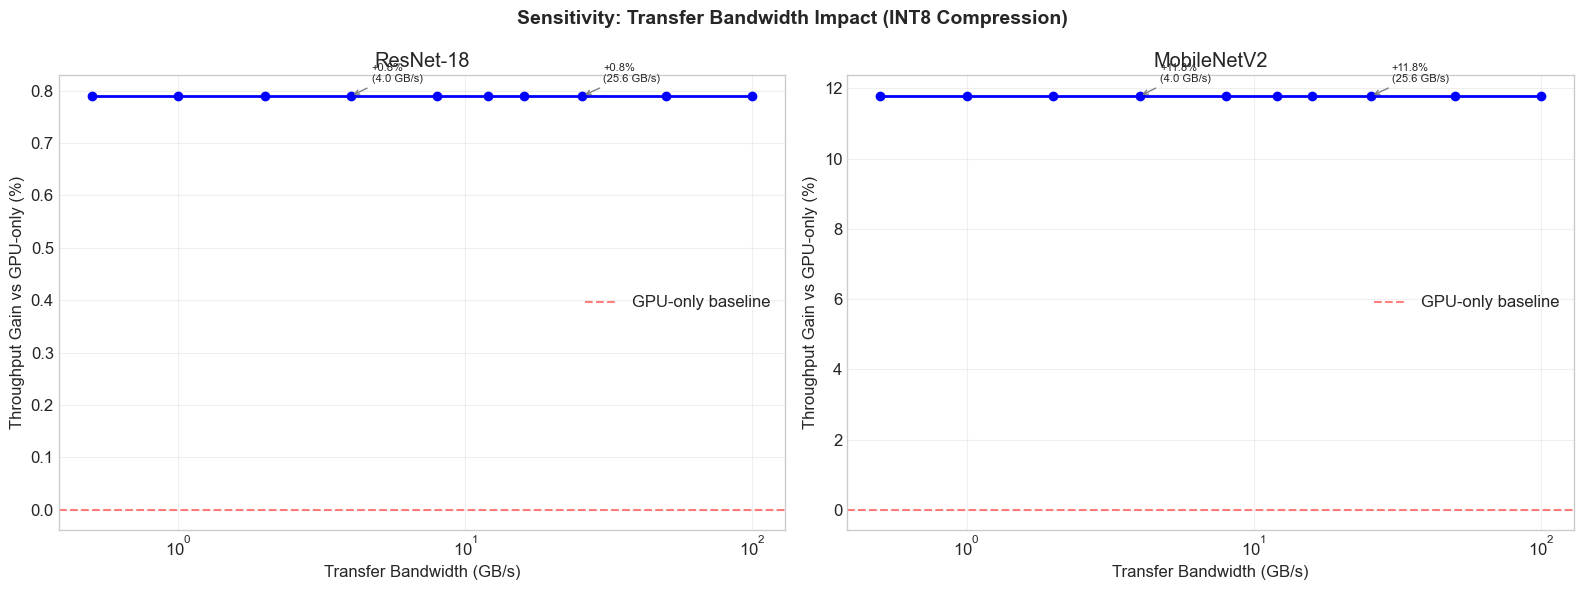

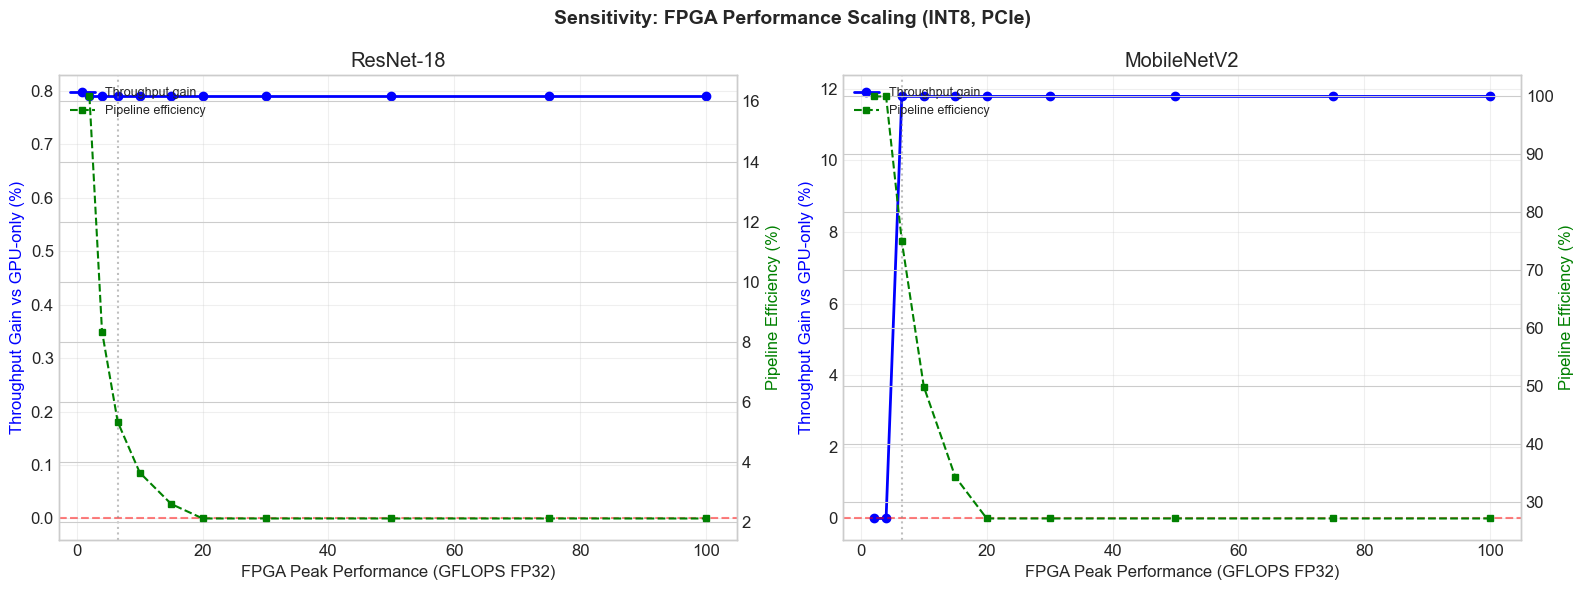

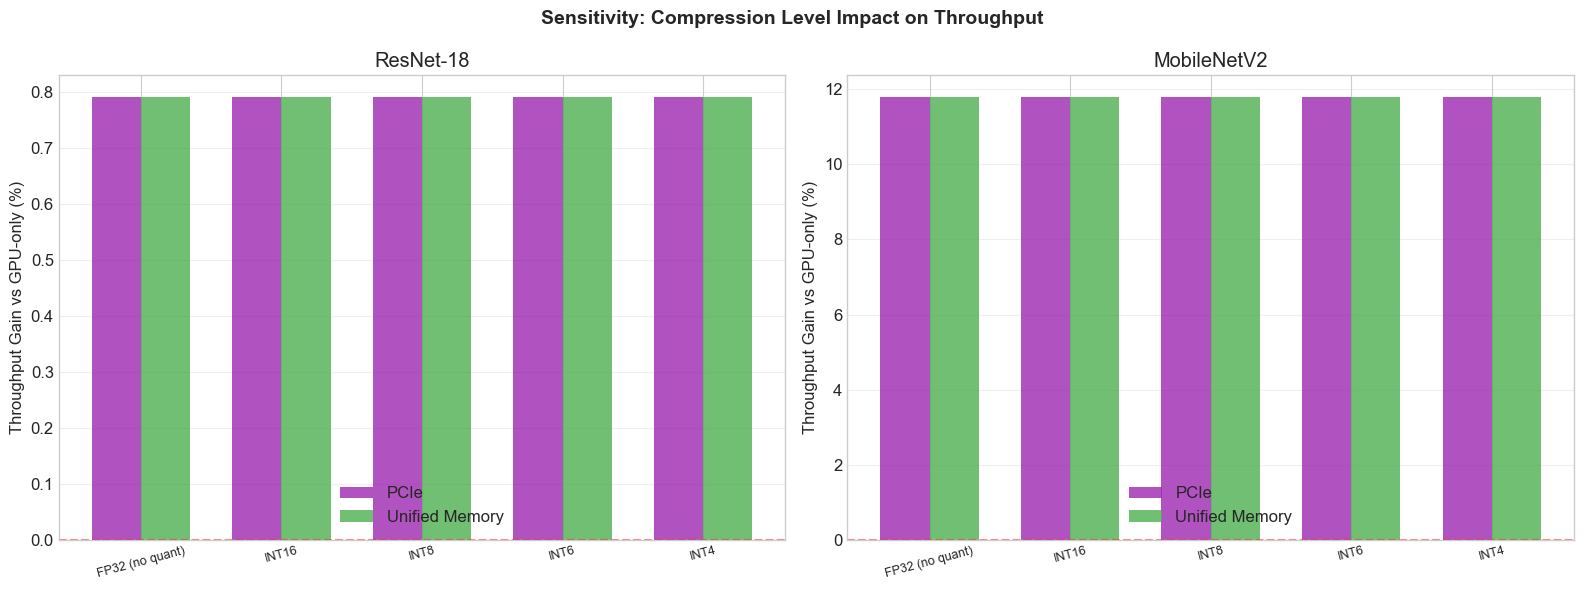

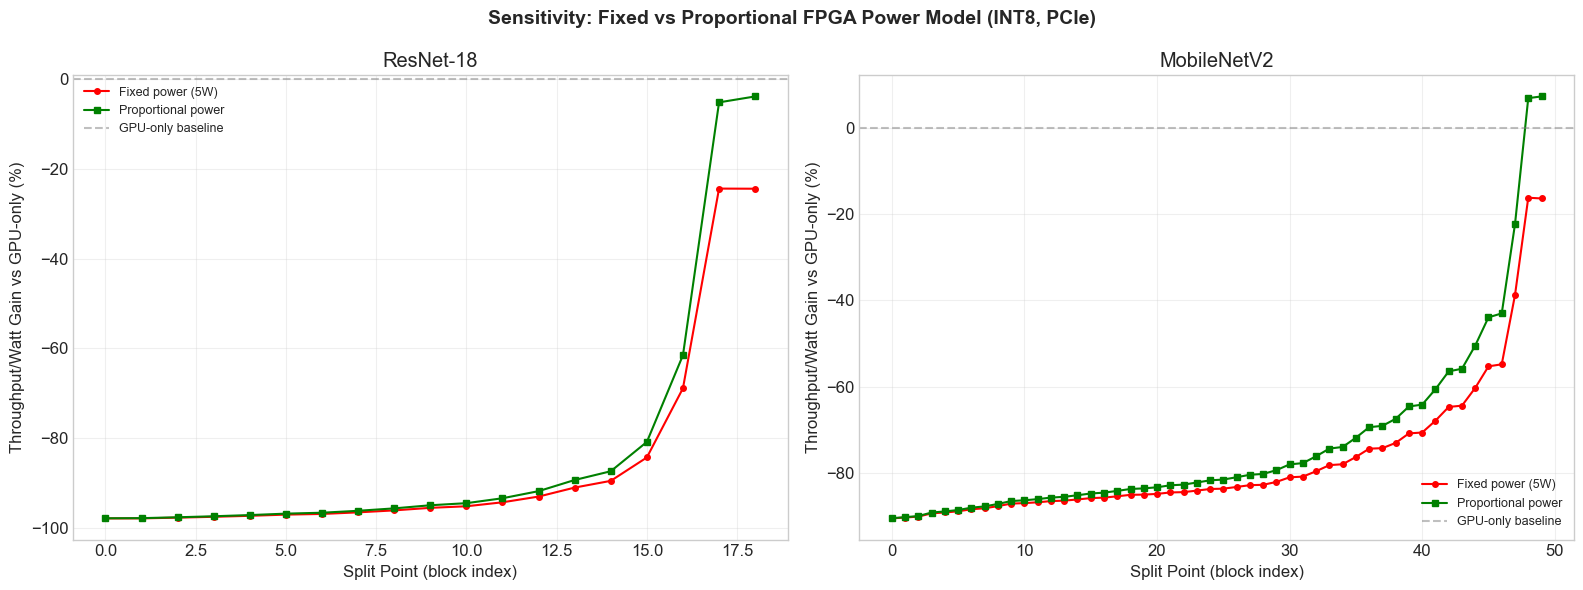


Proportional Power Model — Best Throughput/Watt Results

  ResNet-18:
    GPU-only:              6.20 inf/s/W
    Best (fixed power):    4.69 inf/s/W (-24.4%) | split at 17, 2 FPGA blocks
    Best (proportional):   5.96 inf/s/W (-3.9%) | split at 18, 1 FPGA blocks | FPGA power: 0.7W

  MobileNetV2:
    GPU-only:              34.49 inf/s/W
    Best (fixed power):    28.91 inf/s/W (-16.2%) | split at 48, 2 FPGA blocks
    Best (proportional):   37.02 inf/s/W (+7.4%) | split at 49, 1 FPGA blocks | FPGA power: 0.6W


In [10]:
# Cell 9 — Sensitivity Analysis

# ============================================================================
# 1. Sweep: Transfer Bandwidth Impact
# ============================================================================

def sweep_transfer_bandwidth(arch_name: str, layers: List[Layer], 
                              bandwidths_gbps: List[float],
                              compression: CompressionConfig = INT8_COMPRESSION):
    """Sweep transfer bandwidth and measure throughput at optimal split."""
    fused_blocks = apply_fusion(layers)
    gpu_only_tput = 1.0 / sum(get_block_time(b, gpu_profile) for b in fused_blocks)
    
    results = []
    for bw in bandwidths_gbps:
        profile = TransferProfile(
            bandwidth_gbps=bw,
            latency_overhead_us=50.0 * (4.0 / bw),  # Scale setup latency with bandwidth
            is_unified_memory=(bw >= 20.0)
        )
        best, _ = find_optimal_partition(fused_blocks, compression, profile, "throughput")
        results.append({
            'bandwidth': bw,
            'throughput': best.pipeline_throughput,
            'gain_pct': (best.pipeline_throughput / gpu_only_tput - 1) * 100,
            'split_idx': best.split_idx,
            'efficiency': best.pipeline_efficiency * 100
        })
    
    return results, gpu_only_tput

bandwidths = [0.5, 1.0, 2.0, 4.0, 8.0, 12.0, 16.0, 25.6, 50.0, 100.0]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Sensitivity: Transfer Bandwidth Impact (INT8 Compression)", fontsize=14, fontweight='bold')

for idx, (arch_name, builder) in enumerate([("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified)]):
    results, gpu_baseline = sweep_transfer_bandwidth(arch_name, builder(), bandwidths)
    
    gains = [r['gain_pct'] for r in results]
    
    axes[idx].plot(bandwidths, gains, 'b-o', markersize=6, linewidth=2)
    axes[idx].axhline(y=0, color='r', linestyle='--', alpha=0.5, label='GPU-only baseline')
    axes[idx].set_xlabel("Transfer Bandwidth (GB/s)")
    axes[idx].set_ylabel("Throughput Gain vs GPU-only (%)")
    axes[idx].set_title(f"{arch_name}")
    axes[idx].set_xscale('log')
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)
    
    # Annotate key points
    for r in results:
        if r['bandwidth'] in [4.0, 25.6]:
            axes[idx].annotate(f"{r['gain_pct']:+.1f}%\n({r['bandwidth']} GB/s)", 
                             xy=(r['bandwidth'], r['gain_pct']),
                             textcoords="offset points", xytext=(15, 10), fontsize=8,
                             arrowprops=dict(arrowstyle='->', color='gray'))

plt.tight_layout()
plt.savefig("sensitivity_transfer_bandwidth.png", dpi=150, bbox_inches='tight')
plt.show()


# ============================================================================
# 2. Sweep: FPGA Performance Scaling
# ============================================================================

def sweep_fpga_performance(arch_name: str, layers: List[Layer],
                            fpga_gflops_range: List[float],
                            compression: CompressionConfig = INT8_COMPRESSION):
    """Sweep FPGA peak performance and measure optimal throughput."""
    fused_blocks = apply_fusion(layers)
    gpu_only_tput = 1.0 / sum(get_block_time(b, gpu_profile) for b in fused_blocks)
    
    results = []
    for gflops in fpga_gflops_range:
        # Create modified FPGA profile
        scale = gflops / fpga_profile.peak_gflops
        modified_fpga = DeviceProfile(
            name=f"FPGA ({gflops} GFLOPS)",
            peak_gflops=gflops,
            memory_bandwidth_gbps=fpga_profile.memory_bandwidth_gbps * min(scale, 3.0),  # BW scales but caps
            efficiency=fpga_profile.efficiency.copy(),
            power_watts=fpga_profile.power_watts * (0.5 + 0.5 * scale)  # Power scales sub-linearly
        )
        
        # Temporarily swap the global fpga_profile for cost estimation
        # We need to recompute costs with the modified profile
        fpga_times = []
        for b in fused_blocks:
            if isinstance(b, FusedBlock):
                unfused = sum(estimate_layer_time(l, modified_fpga) for l in b.layers)
                speedup = FUSION_SPEEDUP.get(b.pattern, 1.0)
                base = unfused * speedup
                t = base / compression.quant_speedup_factor if compression.quantization_bits < 32 else base
            else:
                t = estimate_layer_time(b, modified_fpga)
            fpga_times.append(t)
        
        # Find best split manually
        gpu_times = [get_block_time(b, gpu_profile) for b in fused_blocks]
        
        best_tput = gpu_only_tput
        best_split = -1
        best_eff = 1.0
        
        for split_idx in range(len(fused_blocks) - 1):
            gpu_stage = sum(gpu_times[:split_idx + 1])
            fpga_stage = sum(fpga_times[split_idx + 1:])
            
            # Add transfer and prep costs
            tensor_bytes = get_block_output_bytes(fused_blocks[split_idx])
            xfer = compute_transfer_time(int(tensor_bytes * compression.transfer_compression_ratio), pcie_transfer)
            prep = sum(estimate_fusion_prep_time(b) for b in fused_blocks[split_idx + 1:] if isinstance(b, FusedBlock))
            
            effective_gpu = gpu_stage + prep
            effective_fpga = fpga_stage + xfer
            bottleneck = max(effective_gpu, effective_fpga)
            tput = 1.0 / bottleneck
            
            if tput > best_tput:
                best_tput = tput
                best_split = split_idx
                best_eff = min(effective_gpu, effective_fpga) / max(effective_gpu, effective_fpga)
        
        results.append({
            'gflops': gflops,
            'throughput': best_tput,
            'gain_pct': (best_tput / gpu_only_tput - 1) * 100,
            'split_idx': best_split,
            'efficiency': best_eff * 100,
            'power': modified_fpga.power_watts
        })
    
    return results, gpu_only_tput

fpga_gflops_range = [2.0, 4.0, 6.5, 10.0, 15.0, 20.0, 30.0, 50.0, 75.0, 100.0]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Sensitivity: FPGA Performance Scaling (INT8, PCIe)", fontsize=14, fontweight='bold')

for idx, (arch_name, builder) in enumerate([("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified)]):
    results, gpu_baseline = sweep_fpga_performance(arch_name, builder(), fpga_gflops_range)
    
    gains = [r['gain_pct'] for r in results]
    efficiencies = [r['efficiency'] for r in results]
    
    ax1 = axes[idx]
    ax2 = ax1.twinx()
    
    l1 = ax1.plot(fpga_gflops_range, gains, 'b-o', markersize=6, linewidth=2, label='Throughput gain')
    l2 = ax2.plot(fpga_gflops_range, efficiencies, 'g--s', markersize=5, linewidth=1.5, label='Pipeline efficiency')
    
    ax1.axhline(y=0, color='r', linestyle='--', alpha=0.5)
    ax1.axvline(x=6.5, color='gray', linestyle=':', alpha=0.5, label='Current FPGA (6.5 GFLOPS)')
    ax1.set_xlabel("FPGA Peak Performance (GFLOPS FP32)")
    ax1.set_ylabel("Throughput Gain vs GPU-only (%)", color='b')
    ax2.set_ylabel("Pipeline Efficiency (%)", color='g')
    ax1.set_title(f"{arch_name}")
    
    lines = l1 + l2
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='upper left', fontsize=9)
    ax1.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("sensitivity_fpga_performance.png", dpi=150, bbox_inches='tight')
plt.show()


# ============================================================================
# 3. Sweep: Compression Level Impact
# ============================================================================

def sweep_compression(arch_name: str, layers: List[Layer]):
    """Compare different compression configurations."""
    fused_blocks = apply_fusion(layers)
    gpu_only_tput = 1.0 / sum(get_block_time(b, gpu_profile) for b in fused_blocks)
    
    quant_configs = [
        ("FP32 (no quant)",  CompressionConfig(lora_rank=0, quantization_bits=32)),
        ("INT16",            CompressionConfig(lora_rank=16, quantization_bits=16)),
        ("INT8",             CompressionConfig(lora_rank=8, quantization_bits=8)),
        ("INT6",             CompressionConfig(lora_rank=6, quantization_bits=6)),
        ("INT4",             CompressionConfig(lora_rank=4, quantization_bits=4)),
    ]
    
    results = []
    for name, config in quant_configs:
        # Update quant speedup for non-standard bit-widths
        if config.quantization_bits == 16:
            config_adjusted = CompressionConfig(lora_rank=config.lora_rank, quantization_bits=16)
            # Manually compute with 1.5x speedup for INT16
            fused_blocks_copy = apply_fusion(layers)
            fpga_time = 0
            for b in fused_blocks_copy:
                if isinstance(b, FusedBlock):
                    base = estimate_fused_block_time(b, fpga_profile)
                    fpga_time += base / 1.5
                else:
                    fpga_time += estimate_layer_time(b, fpga_profile)
        elif config.quantization_bits == 6:
            fused_blocks_copy = apply_fusion(layers)
            fpga_time = 0
            for b in fused_blocks_copy:
                if isinstance(b, FusedBlock):
                    base = estimate_fused_block_time(b, fpga_profile)
                    fpga_time += base / 3.0
                else:
                    fpga_time += estimate_layer_time(b, fpga_profile)
        
        best_pcie, _ = find_optimal_partition(fused_blocks, config, pcie_transfer, "throughput")
        best_unified, _ = find_optimal_partition(fused_blocks, config, unified_memory_transfer, "throughput")
        
        results.append({
            'name': name,
            'bits': config.quantization_bits,
            'pcie_throughput': best_pcie.pipeline_throughput,
            'pcie_gain': (best_pcie.pipeline_throughput / gpu_only_tput - 1) * 100,
            'unified_throughput': best_unified.pipeline_throughput,
            'unified_gain': (best_unified.pipeline_throughput / gpu_only_tput - 1) * 100,
        })
    
    return results, gpu_only_tput

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Sensitivity: Compression Level Impact on Throughput", fontsize=14, fontweight='bold')

for idx, (arch_name, builder) in enumerate([("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified)]):
    results, gpu_baseline = sweep_compression(arch_name, builder())
    
    names = [r['name'] for r in results]
    pcie_gains = [r['pcie_gain'] for r in results]
    unified_gains = [r['unified_gain'] for r in results]
    
    x = np.arange(len(names))
    width = 0.35
    
    axes[idx].bar(x - width/2, pcie_gains, width, label='PCIe', color='#9C27B0', alpha=0.8)
    axes[idx].bar(x + width/2, unified_gains, width, label='Unified Memory', color='#4CAF50', alpha=0.8)
    axes[idx].axhline(y=0, color='r', linestyle='--', alpha=0.5)
    axes[idx].set_xticks(x)
    axes[idx].set_xticklabels(names, rotation=15, fontsize=9)
    axes[idx].set_ylabel("Throughput Gain vs GPU-only (%)")
    axes[idx].set_title(f"{arch_name}")
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig("sensitivity_compression.png", dpi=150, bbox_inches='tight')
plt.show()


# ============================================================================
# 4. Sweep: FPGA Power Model (Proportional Utilization)
# ============================================================================

def sweep_power_model(arch_name: str, layers: List[Layer]):
    """Compare fixed vs proportional FPGA power models."""
    fused_blocks = apply_fusion(layers)
    n_blocks = len(fused_blocks)
    
    gpu_only_time = sum(get_block_time(b, gpu_profile) for b in fused_blocks)
    gpu_only_tput = 1.0 / gpu_only_time
    gpu_only_tpw = gpu_only_tput / GPU_POWER
    
    results_fixed = []
    results_proportional = []
    
    for split_idx in range(n_blocks - 1):
        best = evaluate_partition(fused_blocks, split_idx, INT8_COMPRESSION, pcie_transfer)
        
        if best.pipeline_throughput <= 0:
            continue
        
        # Fixed power model
        tpw_fixed = best.pipeline_throughput / (GPU_POWER + FPGA_POWER)
        
        # Proportional power model: FPGA power scales with fraction of work
        fpga_utilization = len(best.fpga_blocks) / n_blocks
        fpga_idle_power = 0.5  # Watts — static power when idle
        fpga_proportional_power = fpga_idle_power + (FPGA_POWER - fpga_idle_power) * fpga_utilization
        tpw_proportional = best.pipeline_throughput / (GPU_POWER + fpga_proportional_power)
        
        results_fixed.append({
            'split': split_idx,
            'fpga_blocks': len(best.fpga_blocks),
            'throughput': best.pipeline_throughput,
            'tpw': tpw_fixed,
            'tpw_gain': (tpw_fixed / gpu_only_tpw - 1) * 100
        })
        results_proportional.append({
            'split': split_idx,
            'fpga_blocks': len(best.fpga_blocks),
            'throughput': best.pipeline_throughput,
            'tpw': tpw_proportional,
            'tpw_gain': (tpw_proportional / gpu_only_tpw - 1) * 100,
            'fpga_power': fpga_proportional_power
        })
    
    return results_fixed, results_proportional, gpu_only_tpw

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Sensitivity: Fixed vs Proportional FPGA Power Model (INT8, PCIe)", fontsize=14, fontweight='bold')

for idx, (arch_name, builder) in enumerate([("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified)]):
    fixed, proportional, gpu_tpw = sweep_power_model(arch_name, builder())
    
    splits = [r['split'] for r in fixed]
    gains_fixed = [r['tpw_gain'] for r in fixed]
    gains_prop = [r['tpw_gain'] for r in proportional]
    
    axes[idx].plot(splits, gains_fixed, 'r-o', markersize=4, linewidth=1.5, label='Fixed power (5W)')
    axes[idx].plot(splits, gains_prop, 'g-s', markersize=4, linewidth=1.5, label='Proportional power')
    axes[idx].axhline(y=0, color='gray', linestyle='--', alpha=0.5, label='GPU-only baseline')
    axes[idx].set_xlabel("Split Point (block index)")
    axes[idx].set_ylabel("Throughput/Watt Gain vs GPU-only (%)")
    axes[idx].set_title(f"{arch_name}")
    axes[idx].legend(fontsize=9)
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("sensitivity_power_model.png", dpi=150, bbox_inches='tight')
plt.show()

# Print summary of proportional power model findings
print(f"\n{'='*90}")
print(f"Proportional Power Model — Best Throughput/Watt Results")
print(f"{'='*90}")
for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified)]:
    fixed, proportional, gpu_tpw = sweep_power_model(arch_name, builder())
    
    best_prop = max(proportional, key=lambda r: r['tpw'])
    best_fixed = max(fixed, key=lambda r: r['tpw'])
    
    print(f"\n  {arch_name}:")
    print(f"    GPU-only:              {gpu_tpw:.2f} inf/s/W")
    print(f"    Best (fixed power):    {best_fixed['tpw']:.2f} inf/s/W ({best_fixed['tpw_gain']:+.1f}%) "
          f"| split at {best_fixed['split']}, {best_fixed['fpga_blocks']} FPGA blocks")
    print(f"    Best (proportional):   {best_prop['tpw']:.2f} inf/s/W ({best_prop['tpw_gain']:+.1f}%) "
          f"| split at {best_prop['split']}, {best_prop['fpga_blocks']} FPGA blocks "
          f"| FPGA power: {best_prop['fpga_power']:.1f}W")

Calibration dataset: 71 blocks, 14 features
Features: ['total_flops', 'total_params', 'input_tensor_bytes', 'output_tensor_bytes', 'num_layers', 'is_fused', 'has_conv', 'has_dw_conv', 'has_pw_conv', 'has_fc', 'kernel_size_max', 'out_channels', 'out_spatial', 'arithmetic_intensity']
GPU time range:  0.0035 - 1.0421 ms
FPGA time range: 0.0194 - 27.6713 ms

Predictor Evaluation — Leave-One-Out Cross Validation

  --- GPU Execution Time Prediction ---
  Model                           R²   MAE (ms)     MAPE
  -------------------------------------------------------
  Linear Regression           0.9905   0.0126ms    17.3%
  Ridge Regression            0.9798   0.0162ms    26.0%
  Random Forest               0.9583   0.0209ms    39.7%

  --- FPGA (INT8) Execution Time Prediction ---
  Model                           R²   MAE (ms)     MAPE
  -------------------------------------------------------
  Linear Regression           0.9951   0.3450ms    80.5%
  Ridge Regression            0.9858   0.

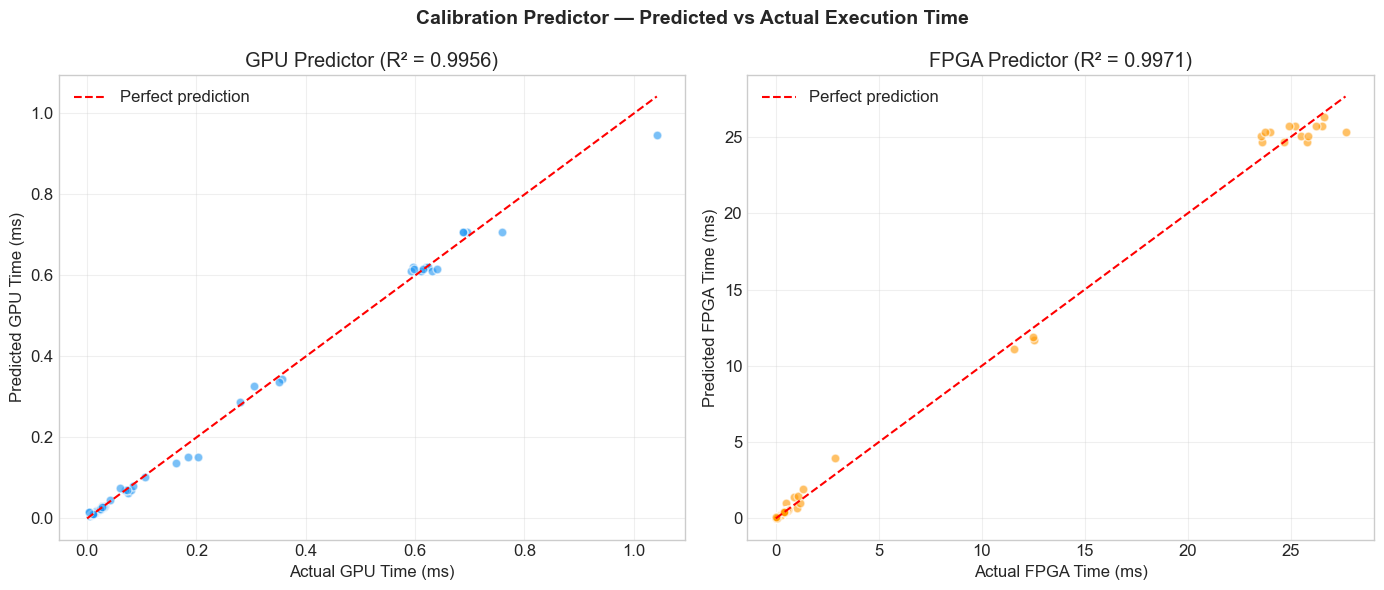

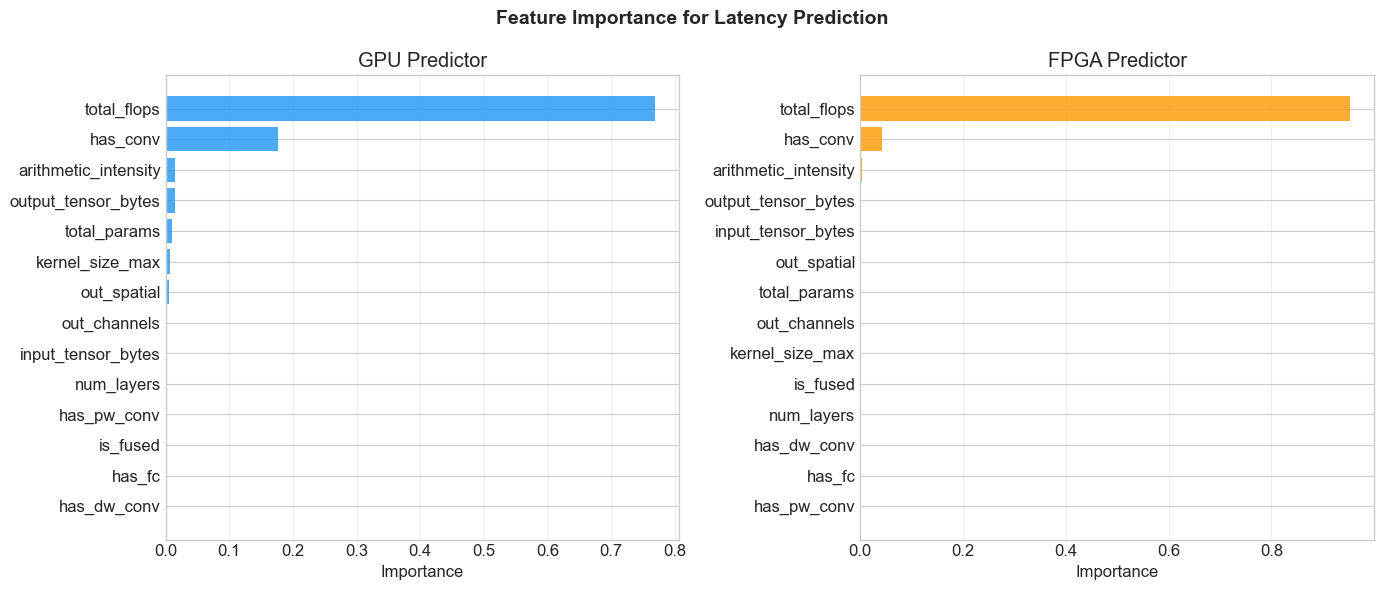


Scheduling Accuracy — Predictor-Guided vs Oracle Split Decisions

  ResNet-18:
    Oracle optimal split:     17 → 93.7 inf/s
    Predictor chosen split:   17 → 93.7 inf/s
    Scheduling regret:        0.00%
    Decision match:           YES

  MobileNetV2:
    Oracle optimal split:     48 → 578.2 inf/s
    Predictor chosen split:   -1 → 517.3 inf/s
    Scheduling regret:        10.54%
    Decision match:           NO


In [11]:
# Cell 10 — Calibration Predictor

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import cross_val_score, LeaveOneOut
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# ============================================================================
# Feature Extraction — Convert blocks into feature vectors
# ============================================================================

def extract_block_features(block) -> dict:
    """Extract numerical features from a fused block or single layer for prediction."""
    if isinstance(block, FusedBlock):
        return {
            'total_flops':          block.total_flops,
            'total_params':         block.total_params,
            'input_tensor_bytes':   block.input_tensor_size_bytes,
            'output_tensor_bytes':  block.output_tensor_size_bytes,
            'num_layers':           len(block.layers),
            'is_fused':             1,
            'has_conv':             int(any(l.layer_type == LayerType.CONV for l in block.layers)),
            'has_dw_conv':          int(any(l.layer_type == LayerType.DEPTHWISE_CONV for l in block.layers)),
            'has_pw_conv':          int(any(l.layer_type == LayerType.POINTWISE_CONV for l in block.layers)),
            'has_fc':               int(any(l.layer_type == LayerType.FC for l in block.layers)),
            'kernel_size_max':      max((l.kernel_size for l in block.layers), default=1),
            'out_channels':         block.layers[-1].out_channels,
            'out_spatial':          block.layers[-1].out_height * block.layers[-1].out_width,
            'arithmetic_intensity': block.total_flops / max(block.input_tensor_size_bytes + block.output_tensor_size_bytes, 1),
        }
    else:
        return {
            'total_flops':          block.flops,
            'total_params':         block.param_count,
            'input_tensor_bytes':   block.input_tensor_size_bytes,
            'output_tensor_bytes':  block.output_tensor_size_bytes,
            'num_layers':           1,
            'is_fused':             0,
            'has_conv':             int(block.layer_type == LayerType.CONV),
            'has_dw_conv':          int(block.layer_type == LayerType.DEPTHWISE_CONV),
            'has_pw_conv':          int(block.layer_type == LayerType.POINTWISE_CONV),
            'has_fc':               int(block.layer_type == LayerType.FC),
            'kernel_size_max':      block.kernel_size,
            'out_channels':         block.out_channels,
            'out_spatial':          block.out_height * block.out_width,
            'arithmetic_intensity': block.flops / max(block.input_tensor_size_bytes + block.output_tensor_size_bytes, 1),
        }


# ============================================================================
# Generate Training Data — Simulate measurements across architectures
# ============================================================================

def generate_calibration_data(architectures: dict, 
                               compression: CompressionConfig = INT8_COMPRESSION,
                               noise_std: float = 0.05):
    """Generate synthetic calibration data (simulating real hardware measurements).
    
    In a real deployment, this would come from actual profiling runs on the target FPGA.
    Here we use our cost model + noise to simulate measurement variability.
    
    Args:
        architectures: Dict of {name: layer_list}
        compression: Compression config for FPGA
        noise_std: Relative noise standard deviation (simulates measurement variance)
    
    Returns:
        features_list, gpu_times, fpga_times, block_names
    """
    features_list = []
    gpu_times = []
    fpga_times = []
    block_names = []
    
    np.random.seed(42)  # Reproducibility
    
    for arch_name, layers in architectures.items():
        fused_blocks = apply_fusion(layers)
        
        for block in fused_blocks:
            features = extract_block_features(block)
            
            # "Ground truth" from cost model
            gpu_t = get_block_time(block, gpu_profile)
            fpga_t = get_block_time(block, fpga_profile, compression)
            
            # Add measurement noise (simulates real hardware variability)
            gpu_t_noisy = gpu_t * (1.0 + np.random.normal(0, noise_std))
            fpga_t_noisy = fpga_t * (1.0 + np.random.normal(0, noise_std))
            
            features_list.append(features)
            gpu_times.append(max(gpu_t_noisy, 1e-9))  # Clamp to positive
            fpga_times.append(max(fpga_t_noisy, 1e-9))
            block_names.append(f"{arch_name}:{block.name}")
    
    return features_list, gpu_times, fpga_times, block_names


# Build training data from both architectures
architectures = {
    "ResNet-18": build_resnet18(),
    "MobileNetV2": build_mobilenetv2_simplified(),
}

features_list, gpu_times, fpga_times, block_names = generate_calibration_data(architectures)

# Convert to numpy arrays
feature_names = list(features_list[0].keys())
X = np.array([[f[k] for k in feature_names] for f in features_list])
y_gpu = np.array(gpu_times)
y_fpga = np.array(fpga_times)

print(f"Calibration dataset: {X.shape[0]} blocks, {X.shape[1]} features")
print(f"Features: {feature_names}")
print(f"GPU time range:  {y_gpu.min()*1000:.4f} - {y_gpu.max()*1000:.4f} ms")
print(f"FPGA time range: {y_fpga.min()*1000:.4f} - {y_fpga.max()*1000:.4f} ms")


# ============================================================================
# Train and Evaluate Predictors
# ============================================================================

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=50, max_depth=8, random_state=42),
}

print(f"\n{'='*90}")
print(f"Predictor Evaluation — Leave-One-Out Cross Validation")
print(f"{'='*90}")

best_model_gpu = None
best_model_fpga = None
best_gpu_score = -np.inf
best_fpga_score = -np.inf

for target_name, y_target in [("GPU", y_gpu), ("FPGA (INT8)", y_fpga)]:
    print(f"\n  --- {target_name} Execution Time Prediction ---")
    print(f"  {'Model':<25} {'R²':>8} {'MAE (ms)':>10} {'MAPE':>8}")
    print(f"  {'-'*55}")
    
    for model_name, model in models.items():
        # Use LOO cross-validation for small dataset
        loo = LeaveOneOut()
        predictions = np.zeros(len(y_target))
        
        for train_idx, test_idx in loo.split(X_scaled):
            model.fit(X_scaled[train_idx], y_target[train_idx])
            predictions[test_idx] = model.predict(X_scaled[test_idx])
        
        # Clamp predictions to positive
        predictions = np.maximum(predictions, 1e-9)
        
        r2 = r2_score(y_target, predictions)
        mae = mean_absolute_error(y_target, predictions) * 1000  # Convert to ms
        mape = mean_absolute_percentage_error(y_target, predictions) * 100
        
        print(f"  {model_name:<25} {r2:>8.4f} {mae:>8.4f}ms {mape:>7.1f}%")
        
        # Track best
        if target_name == "GPU" and r2 > best_gpu_score:
            best_gpu_score = r2
            best_gpu_model_name = model_name
        if target_name == "FPGA (INT8)" and r2 > best_fpga_score:
            best_fpga_score = r2
            best_fpga_model_name = model_name

print(f"\n  Best GPU predictor:  {best_gpu_model_name} (R² = {best_gpu_score:.4f})")
print(f"  Best FPGA predictor: {best_fpga_model_name} (R² = {best_fpga_score:.4f})")


# ============================================================================
# Train final models on full dataset
# ============================================================================

final_gpu_model = RandomForestRegressor(n_estimators=50, max_depth=8, random_state=42)
final_fpga_model = RandomForestRegressor(n_estimators=50, max_depth=8, random_state=42)

final_gpu_model.fit(X_scaled, y_gpu)
final_fpga_model.fit(X_scaled, y_fpga)

gpu_predictions = final_gpu_model.predict(X_scaled)
fpga_predictions = final_fpga_model.predict(X_scaled)


# ============================================================================
# Feature Importance Analysis
# ============================================================================

print(f"\n{'='*90}")
print(f"Feature Importance (Random Forest)")
print(f"{'='*90}")

gpu_importances = final_gpu_model.feature_importances_
fpga_importances = final_fpga_model.feature_importances_

sorted_idx = np.argsort(gpu_importances)[::-1]
print(f"\n  {'Feature':<25} {'GPU Importance':>15} {'FPGA Importance':>16}")
print(f"  {'-'*60}")
for i in sorted_idx:
    print(f"  {feature_names[i]:<25} {gpu_importances[i]:>14.3f} {fpga_importances[i]:>15.3f}")


# ============================================================================
# Visualization — Predicted vs Actual
# ============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Calibration Predictor — Predicted vs Actual Execution Time", fontsize=14, fontweight='bold')

# GPU predictions
axes[0].scatter(y_gpu * 1000, gpu_predictions * 1000, c='#2196F3', alpha=0.6, s=40, edgecolors='white')
max_val = max(y_gpu.max(), gpu_predictions.max()) * 1000
axes[0].plot([0, max_val], [0, max_val], 'r--', linewidth=1.5, label='Perfect prediction')
axes[0].set_xlabel("Actual GPU Time (ms)")
axes[0].set_ylabel("Predicted GPU Time (ms)")
axes[0].set_title(f"GPU Predictor (R² = {r2_score(y_gpu, gpu_predictions):.4f})")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# FPGA predictions
axes[1].scatter(y_fpga * 1000, fpga_predictions * 1000, c='#FF9800', alpha=0.6, s=40, edgecolors='white')
max_val = max(y_fpga.max(), fpga_predictions.max()) * 1000
axes[1].plot([0, max_val], [0, max_val], 'r--', linewidth=1.5, label='Perfect prediction')
axes[1].set_xlabel("Actual FPGA Time (ms)")
axes[1].set_ylabel("Predicted FPGA Time (ms)")
axes[1].set_title(f"FPGA Predictor (R² = {r2_score(y_fpga, fpga_predictions):.4f})")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("calibration_predictor_accuracy.png", dpi=150, bbox_inches='tight')
plt.show()


# ============================================================================
# Visualization — Feature Importance
# ============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Feature Importance for Latency Prediction", fontsize=14, fontweight='bold')

sorted_gpu_idx = np.argsort(gpu_importances)
sorted_fpga_idx = np.argsort(fpga_importances)

axes[0].barh([feature_names[i] for i in sorted_gpu_idx], gpu_importances[sorted_gpu_idx], color='#2196F3', alpha=0.8)
axes[0].set_xlabel("Importance")
axes[0].set_title("GPU Predictor")
axes[0].grid(True, alpha=0.3, axis='x')

axes[1].barh([feature_names[i] for i in sorted_fpga_idx], fpga_importances[sorted_fpga_idx], color='#FF9800', alpha=0.8)
axes[1].set_xlabel("Importance")
axes[1].set_title("FPGA Predictor")
axes[1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig("calibration_feature_importance.png", dpi=150, bbox_inches='tight')
plt.show()


# ============================================================================
# Scheduling Accuracy — Does the predictor make correct split decisions?
# ============================================================================

print(f"\n{'='*90}")
print(f"Scheduling Accuracy — Predictor-Guided vs Oracle Split Decisions")
print(f"{'='*90}")

for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified)]:
    layers = builder()
    fused_blocks = apply_fusion(layers)
    
    # Oracle: use true cost model
    oracle_best, oracle_all = find_optimal_partition(fused_blocks, INT8_COMPRESSION, pcie_transfer, "throughput")
    
    # Predictor: use predicted times to evaluate partitions
    predicted_gpu_times = []
    predicted_fpga_times = []
    
    for block in fused_blocks:
        feat = extract_block_features(block)
        feat_vec = np.array([[feat[k] for k in feature_names]])
        feat_scaled = scaler.transform(feat_vec)
        
        predicted_gpu_times.append(max(final_gpu_model.predict(feat_scaled)[0], 1e-9))
        predicted_fpga_times.append(max(final_fpga_model.predict(feat_scaled)[0], 1e-9))
    
    # Find best split using predicted times
    best_pred_tput = 0
    best_pred_split = -1
    
    pred_gpu_only_time = sum(predicted_gpu_times)
    pred_gpu_only_tput = 1.0 / pred_gpu_only_time
    best_pred_tput = pred_gpu_only_tput
    
    for split_idx in range(len(fused_blocks) - 1):
        gpu_stage = sum(predicted_gpu_times[:split_idx + 1])
        fpga_stage = sum(predicted_fpga_times[split_idx + 1:])
        
        tensor_bytes = get_block_output_bytes(fused_blocks[split_idx])
        xfer = estimate_compressed_transfer_time(tensor_bytes, INT8_COMPRESSION, pcie_transfer)
        prep = sum(estimate_fusion_prep_time(b) for b in fused_blocks[split_idx + 1:] if isinstance(b, FusedBlock))
        
        bottleneck = max(gpu_stage + prep, fpga_stage + xfer)
        tput = 1.0 / bottleneck
        
        if tput > best_pred_tput:
            best_pred_tput = tput
            best_pred_split = split_idx
    
    # Compare
    oracle_tput = oracle_best.pipeline_throughput
    
    # What throughput do we actually get if we use the predictor's split decision?
    if best_pred_split >= 0:
        actual_at_pred_split = evaluate_partition(fused_blocks, best_pred_split, INT8_COMPRESSION, pcie_transfer)
        actual_tput_at_pred = actual_at_pred_split.pipeline_throughput
    else:
        actual_tput_at_pred = 1.0 / sum(get_block_time(b, gpu_profile) for b in fused_blocks)
    
    regret = (1 - actual_tput_at_pred / oracle_tput) * 100
    
    print(f"\n  {arch_name}:")
    print(f"    Oracle optimal split:     {oracle_best.split_idx} → {oracle_tput:.1f} inf/s")
    print(f"    Predictor chosen split:   {best_pred_split} → {actual_tput_at_pred:.1f} inf/s")
    print(f"    Scheduling regret:        {regret:.2f}%")
    print(f"    Decision match:           {'YES' if best_pred_split == oracle_best.split_idx else 'NO'}")

Multi-Split Partition Optimization (INT8, PCIe)

──────────────────────────────────────────────────────────────────────────────────────────────────────────────
ResNet-18 (GPU-only baseline: 93.0 inf/s)
──────────────────────────────────────────────────────────────────────────────────────────────────────────────

  Max 1 split(s):
    Best split points:     [17]
    Throughput:            93.7 inf/s (+0.8% vs GPU-only)
    Pipeline efficiency:   5.3%
    Single latency:        11.24 ms
    Segments:
      [GPU ] 18 blocks (fused_1_conv_bn_relu..fused_17_conv_bn_relu) → 10.6693 ms
      [FPGA]  2 blocks (avgpool..fc) → 0.5134 ms
    Transfer overhead:     0.0563 ms (1 transfers)
    Fusion prep overhead:  0.0000 ms
    GPU total stage:       10.6693 ms
    FPGA total stage:      0.5697 ms
    Configs evaluated:     20

  Max 2 split(s):
    Best split points:     [17]
    Throughput:            93.7 inf/s (+0.8% vs GPU-only)
    Pipeline efficiency:   5.3%
    Single latency:        11.2

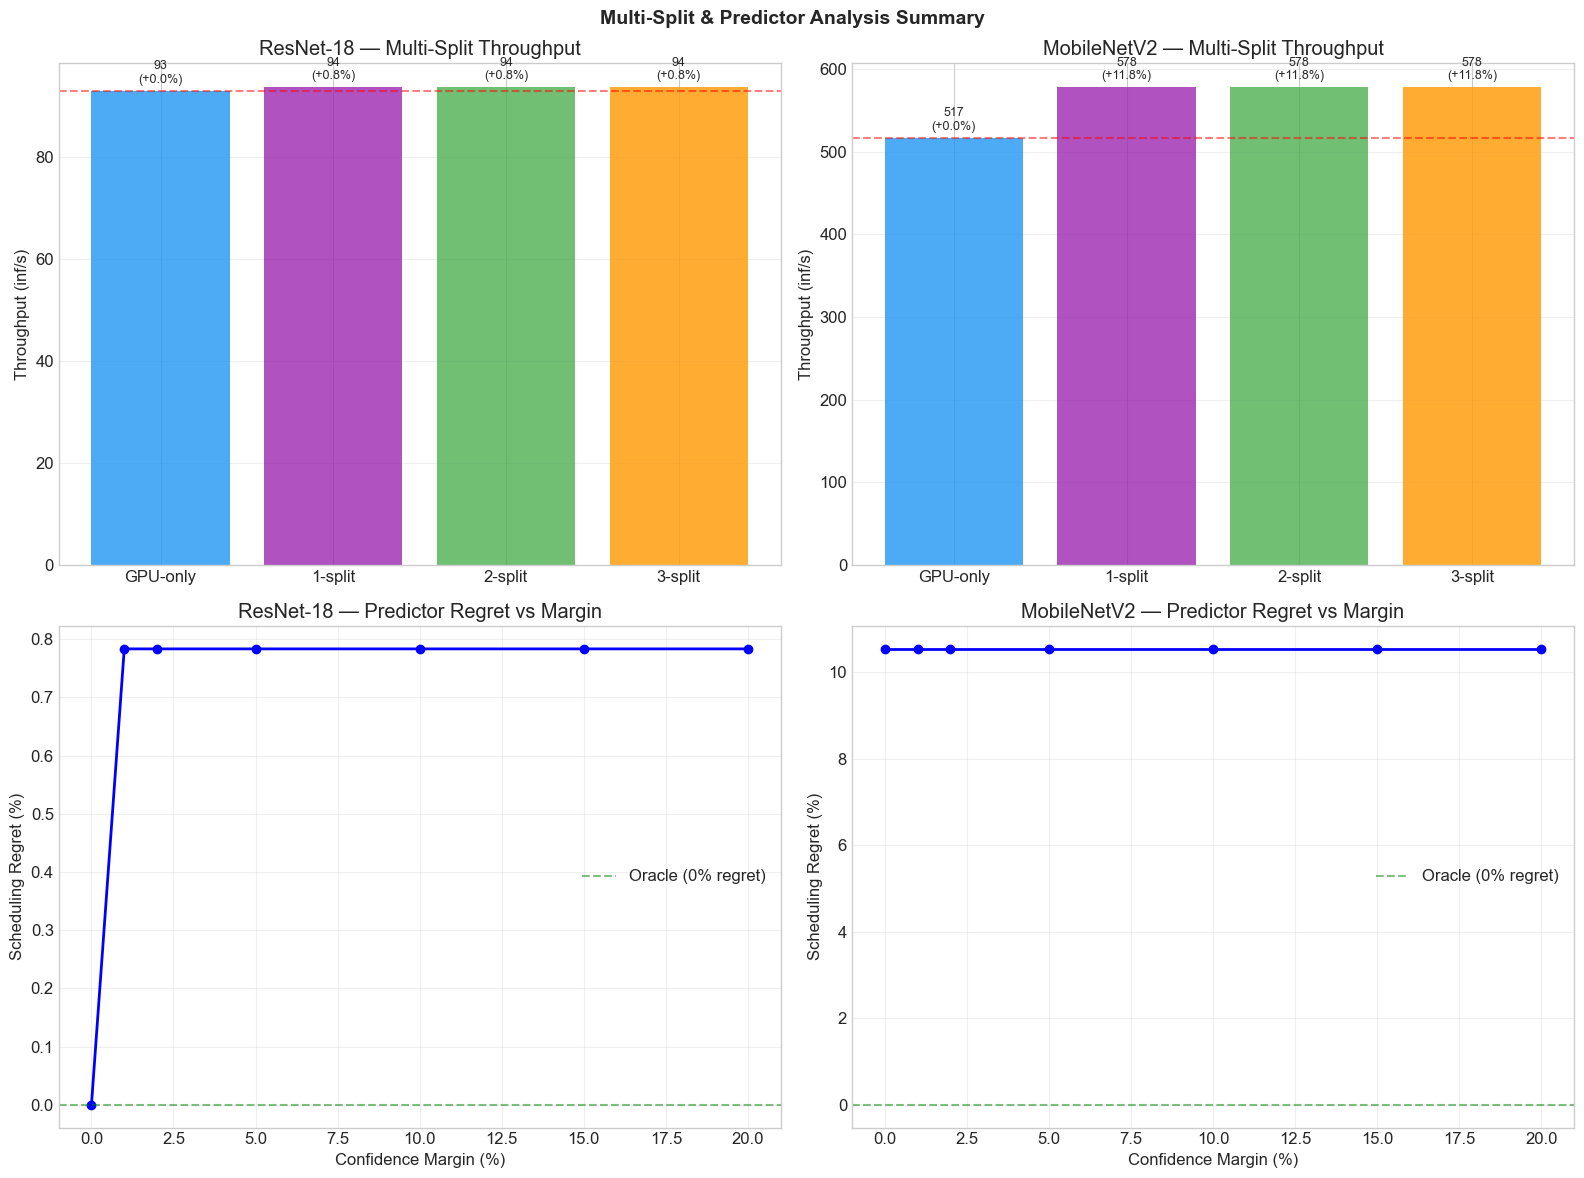

In [12]:
# Cell 11 — Multi-Split Partitioning and Improved Scheduling

# ============================================================================
# Multi-Split Partition Model
# ============================================================================
# Instead of a single split (GPU stage → FPGA stage), allow multiple splits
# where execution alternates: GPU → FPGA → GPU → FPGA ...
# This lets the framework assign small FPGA-friendly pockets in the middle
# of the network, not just the tail.

@dataclass
class MultiSplitResult:
    """Result of a multi-split partition configuration."""
    split_points: List[int]             # List of split indices
    segments: List[Tuple[str, List]]    # [(device, blocks), ...] alternating GPU/FPGA
    segment_times: List[float]          # Execution time per segment
    transfer_times: List[float]         # Transfer cost at each split boundary
    fusion_prep_times: List[float]      # GPU prep time for each FPGA segment
    compression: CompressionConfig
    
    @property
    def n_splits(self) -> int:
        return len(self.split_points)
    
    @property
    def total_gpu_time(self) -> float:
        return sum(t for (dev, _), t in zip(self.segments, self.segment_times) if dev == "GPU")
    
    @property
    def total_fpga_time(self) -> float:
        return sum(t for (dev, _), t in zip(self.segments, self.segment_times) if dev == "FPGA")
    
    @property
    def total_transfer_time(self) -> float:
        return sum(self.transfer_times)
    
    @property
    def single_inference_latency(self) -> float:
        """Sequential latency — sum of all segments + transfers."""
        return sum(self.segment_times) + sum(self.transfer_times)
    
    @property
    def pipeline_throughput(self) -> float:
        """Pipeline throughput — limited by the slowest stage.
        
        For multi-split, we model it as:
        - All GPU segments + their prep overhead form one pipeline stage
        - All FPGA segments + their transfer overhead form the other stage
        - Throughput = 1 / max(gpu_total_stage, fpga_total_stage)
        """
        gpu_total = self.total_gpu_time + sum(self.fusion_prep_times)
        fpga_total = self.total_fpga_time + self.total_transfer_time
        
        if fpga_total == 0:
            return 1.0 / gpu_total if gpu_total > 0 else 0
        
        return 1.0 / max(gpu_total, fpga_total)
    
    @property
    def pipeline_efficiency(self) -> float:
        gpu_total = self.total_gpu_time + sum(self.fusion_prep_times)
        fpga_total = self.total_fpga_time + self.total_transfer_time
        
        if fpga_total == 0:
            return 1.0
        
        slower = max(gpu_total, fpga_total)
        faster = min(gpu_total, fpga_total)
        return faster / slower if slower > 0 else 0
    
    @property
    def total_power(self) -> float:
        if self.total_fpga_time > 0:
            return GPU_POWER + FPGA_POWER
        return GPU_POWER
    
    @property
    def throughput_per_watt(self) -> float:
        return self.pipeline_throughput / self.total_power


def evaluate_multi_split(fused_blocks: List, split_points: List[int],
                          compression: CompressionConfig = INT8_COMPRESSION,
                          transfer_profile: TransferProfile = None) -> MultiSplitResult:
    """Evaluate a multi-split partition.
    
    Segments alternate: GPU → FPGA → GPU → FPGA → ...
    split_points define boundaries between segments.
    
    Args:
        fused_blocks: List of fused/unfused blocks
        split_points: Sorted list of split indices. Segment k contains blocks
                      from split_points[k-1]+1 to split_points[k].
        compression: Compression config for FPGA segments
        transfer_profile: Transfer profile for device boundaries
    """
    n = len(fused_blocks)
    
    # Build segment boundaries
    boundaries = [-1] + sorted(split_points) + [n - 1]
    segments = []
    segment_times = []
    transfer_times = []
    fusion_prep_times = []
    
    for i in range(len(boundaries) - 1):
        start = boundaries[i] + 1
        end = boundaries[i + 1] + 1  # Exclusive
        blocks = fused_blocks[start:end]
        
        # Alternate device: even segments = GPU, odd = FPGA
        device = "GPU" if i % 2 == 0 else "FPGA"
        segments.append((device, blocks))
        
        # Compute segment time
        if device == "GPU":
            seg_time = sum(get_block_time(b, gpu_profile) for b in blocks)
            fusion_prep_times.append(0)
        else:
            seg_time = sum(get_block_time(b, fpga_profile, compression) for b in blocks)
            prep = sum(estimate_fusion_prep_time(b) for b in blocks if isinstance(b, FusedBlock))
            fusion_prep_times.append(prep)
        
        segment_times.append(seg_time)
        
        # Transfer cost at the boundary (except before first segment)
        if i > 0:
            boundary_block = fused_blocks[boundaries[i]]
            tensor_bytes = get_block_output_bytes(boundary_block)
            if compression.quantization_bits < 32:
                xfer = estimate_compressed_transfer_time(tensor_bytes, compression, transfer_profile)
            else:
                xfer = compute_transfer_time(tensor_bytes, transfer_profile)
            transfer_times.append(xfer)
    
    return MultiSplitResult(
        split_points=split_points,
        segments=segments,
        segment_times=segment_times,
        transfer_times=transfer_times,
        fusion_prep_times=fusion_prep_times,
        compression=compression
    )


def find_optimal_multi_split(fused_blocks: List, max_splits: int = 2,
                              compression: CompressionConfig = INT8_COMPRESSION,
                              transfer_profile: TransferProfile = None) -> Tuple[MultiSplitResult, List[MultiSplitResult]]:
    """Search for optimal multi-split partition.
    
    For 1 split: O(n) search
    For 2 splits: O(n²) search
    For 3 splits: O(n³) search — may be slow for large networks
    """
    n = len(fused_blocks)
    
    # GPU-only baseline
    gpu_only = evaluate_multi_split(fused_blocks, [], compression, transfer_profile)
    
    all_results = [gpu_only]
    best = gpu_only
    
    # 1-split search
    for s1 in range(n - 1):
        result = evaluate_multi_split(fused_blocks, [s1], compression, transfer_profile)
        all_results.append(result)
        if result.pipeline_throughput > best.pipeline_throughput:
            best = result
    
    # 2-split search
    if max_splits >= 2:
        for s1 in range(n - 2):
            for s2 in range(s1 + 2, n - 1):  # s2 must be at least s1 + 2
                result = evaluate_multi_split(fused_blocks, [s1, s2], compression, transfer_profile)
                all_results.append(result)
                if result.pipeline_throughput > best.pipeline_throughput:
                    best = result
    
    # 3-split search (limited range to avoid combinatorial explosion)
    if max_splits >= 3 and n <= 60:
        step = max(1, n // 20)  # Coarse search for 3 splits
        for s1 in range(0, n - 4, step):
            for s2 in range(s1 + 2, n - 2, step):
                for s3 in range(s2 + 2, n - 1, step):
                    result = evaluate_multi_split(fused_blocks, [s1, s2, s3], compression, transfer_profile)
                    all_results.append(result)
                    if result.pipeline_throughput > best.pipeline_throughput:
                        best = result
    
    return best, all_results


# ============================================================================
# Run Multi-Split Optimization
# ============================================================================

print(f"{'='*110}")
print(f"Multi-Split Partition Optimization (INT8, PCIe)")
print(f"{'='*110}")

for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified)]:
    layers = builder()
    fused_blocks = apply_fusion(layers)
    
    gpu_only_time = sum(get_block_time(b, gpu_profile) for b in fused_blocks)
    gpu_only_tput = 1.0 / gpu_only_time
    
    print(f"\n{'─'*110}")
    print(f"{arch_name} (GPU-only baseline: {gpu_only_tput:.1f} inf/s)")
    print(f"{'─'*110}")
    
    for max_splits in [1, 2, 3]:
        best, all_results = find_optimal_multi_split(
            fused_blocks, max_splits, INT8_COMPRESSION, pcie_transfer
        )
        
        gain = (best.pipeline_throughput / gpu_only_tput - 1) * 100
        
        print(f"\n  Max {max_splits} split(s):")
        print(f"    Best split points:     {best.split_points if best.split_points else 'None (GPU-only)'}")
        print(f"    Throughput:            {best.pipeline_throughput:.1f} inf/s ({gain:+.1f}% vs GPU-only)")
        print(f"    Pipeline efficiency:   {best.pipeline_efficiency*100:.1f}%")
        print(f"    Single latency:        {best.single_inference_latency*1000:.2f} ms")
        
        if best.split_points:
            print(f"    Segments:")
            for i, ((dev, blocks), seg_time) in enumerate(zip(best.segments, best.segment_times)):
                block_range = f"{blocks[0].name}..{blocks[-1].name}" if len(blocks) > 1 else blocks[0].name
                print(f"      [{dev:4s}] {len(blocks):2d} blocks ({block_range}) → {seg_time*1000:.4f} ms")
            
            print(f"    Transfer overhead:     {best.total_transfer_time*1000:.4f} ms ({len(best.transfer_times)} transfers)")
            print(f"    Fusion prep overhead:  {sum(best.fusion_prep_times)*1000:.4f} ms")
            print(f"    GPU total stage:       {(best.total_gpu_time + sum(best.fusion_prep_times))*1000:.4f} ms")
            print(f"    FPGA total stage:      {(best.total_fpga_time + best.total_transfer_time)*1000:.4f} ms")
        
        print(f"    Configs evaluated:     {len(all_results)}")


# ============================================================================
# Improved Predictor with Confidence Margin
# ============================================================================

print(f"\n\n{'='*110}")
print(f"Improved Scheduling with Confidence Margin")
print(f"{'='*110}")

def predictor_guided_split(fused_blocks: List, 
                            gpu_model, fpga_model, scaler_obj,
                            feature_names: List[str],
                            compression: CompressionConfig = INT8_COMPRESSION,
                            transfer_profile: TransferProfile = None,
                            confidence_margin: float = 0.05) -> Tuple[int, float]:
    """Use predictor to choose split point, with confidence margin.
    
    Only splits if predicted gain exceeds confidence_margin (e.g., 5%).
    This prevents risky splits for marginal predicted improvements.
    
    Returns: (chosen_split_idx, predicted_throughput)
    """
    # Predict times for all blocks
    pred_gpu = []
    pred_fpga = []
    
    for block in fused_blocks:
        feat = extract_block_features(block)
        feat_vec = np.array([[feat[k] for k in feature_names]])
        feat_scaled = scaler_obj.transform(feat_vec)
        
        pred_gpu.append(max(gpu_model.predict(feat_scaled)[0], 1e-9))
        pred_fpga.append(max(fpga_model.predict(feat_scaled)[0], 1e-9))
    
    # GPU-only baseline
    gpu_only_tput = 1.0 / sum(pred_gpu)
    
    best_split = -1
    best_tput = gpu_only_tput
    
    for split_idx in range(len(fused_blocks) - 1):
        gpu_stage = sum(pred_gpu[:split_idx + 1])
        fpga_stage = sum(pred_fpga[split_idx + 1:])
        
        tensor_bytes = get_block_output_bytes(fused_blocks[split_idx])
        xfer = estimate_compressed_transfer_time(tensor_bytes, compression, transfer_profile)
        prep = sum(estimate_fusion_prep_time(b) for b in fused_blocks[split_idx + 1:] if isinstance(b, FusedBlock))
        
        bottleneck = max(gpu_stage + prep, fpga_stage + xfer)
        tput = 1.0 / bottleneck
        
        # Only accept if gain exceeds confidence margin
        if tput > best_tput and (tput / gpu_only_tput - 1) > confidence_margin:
            best_tput = tput
            best_split = split_idx
    
    return best_split, best_tput


# Sweep confidence margins
margins = [0.0, 0.01, 0.02, 0.05, 0.10, 0.15, 0.20]

for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified)]:
    layers = builder()
    fused_blocks = apply_fusion(layers)
    
    # Oracle result
    oracle_best, _ = find_optimal_partition(fused_blocks, INT8_COMPRESSION, pcie_transfer, "throughput")
    oracle_tput = oracle_best.pipeline_throughput
    
    print(f"\n  {arch_name} (Oracle: split={oracle_best.split_idx}, {oracle_tput:.1f} inf/s)")
    print(f"  {'Margin':>8} {'Chosen Split':>14} {'Actual Tput':>14} {'Regret':>10} {'Decision':>10}")
    print(f"  {'-'*60}")
    
    for margin in margins:
        chosen_split, pred_tput = predictor_guided_split(
            fused_blocks, final_gpu_model, final_fpga_model, scaler,
            feature_names, INT8_COMPRESSION, pcie_transfer, margin
        )
        
        # Actual throughput at chosen split
        if chosen_split >= 0:
            actual = evaluate_partition(fused_blocks, chosen_split, INT8_COMPRESSION, pcie_transfer)
            actual_tput = actual.pipeline_throughput
        else:
            actual_tput = 1.0 / sum(get_block_time(b, gpu_profile) for b in fused_blocks)
        
        regret = (1 - actual_tput / oracle_tput) * 100
        match = "MATCH" if chosen_split == oracle_best.split_idx else "MISS"
        
        print(f"  {margin:>7.0%} {chosen_split:>14} {actual_tput:>12.1f}/s {regret:>9.2f}% {match:>10}")


# ============================================================================
# Combined Summary Plot
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("Multi-Split & Predictor Analysis Summary", fontsize=14, fontweight='bold')

# Plot 1 & 2: Multi-split throughput comparison
for idx, (arch_name, builder) in enumerate([("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified)]):
    layers = builder()
    fused_blocks = apply_fusion(layers)
    gpu_only_tput = 1.0 / sum(get_block_time(b, gpu_profile) for b in fused_blocks)
    
    split_configs = ["GPU-only"]
    throughputs = [gpu_only_tput]
    colors_bar = ['#2196F3']
    
    for max_s in [1, 2, 3]:
        best, _ = find_optimal_multi_split(fused_blocks, max_s, INT8_COMPRESSION, pcie_transfer)
        split_configs.append(f"{max_s}-split")
        throughputs.append(best.pipeline_throughput)
        colors_bar.append(['#9C27B0', '#4CAF50', '#FF9800'][max_s - 1])
    
    bars = axes[0, idx].bar(split_configs, throughputs, color=colors_bar, alpha=0.8)
    axes[0, idx].axhline(y=gpu_only_tput, color='r', linestyle='--', alpha=0.5)
    axes[0, idx].set_ylabel("Throughput (inf/s)")
    axes[0, idx].set_title(f"{arch_name} — Multi-Split Throughput")
    axes[0, idx].grid(True, alpha=0.3, axis='y')
    
    for bar, val in zip(bars, throughputs):
        pct = (val / gpu_only_tput - 1) * 100
        axes[0, idx].text(bar.get_x() + bar.get_width()/2, val + max(throughputs)*0.01,
                         f"{val:.0f}\n({pct:+.1f}%)", ha='center', va='bottom', fontsize=9)

# Plot 3 & 4: Predictor regret vs confidence margin
for idx, (arch_name, builder) in enumerate([("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified)]):
    layers = builder()
    fused_blocks = apply_fusion(layers)
    oracle_best, _ = find_optimal_partition(fused_blocks, INT8_COMPRESSION, pcie_transfer, "throughput")
    oracle_tput = oracle_best.pipeline_throughput
    
    regrets = []
    for margin in margins:
        chosen_split, _ = predictor_guided_split(
            fused_blocks, final_gpu_model, final_fpga_model, scaler,
            feature_names, INT8_COMPRESSION, pcie_transfer, margin
        )
        if chosen_split >= 0:
            actual = evaluate_partition(fused_blocks, chosen_split, INT8_COMPRESSION, pcie_transfer)
            actual_tput = actual.pipeline_throughput
        else:
            actual_tput = 1.0 / sum(get_block_time(b, gpu_profile) for b in fused_blocks)
        regrets.append((1 - actual_tput / oracle_tput) * 100)
    
    axes[1, idx].plot([m * 100 for m in margins], regrets, 'b-o', markersize=6, linewidth=2)
    axes[1, idx].axhline(y=0, color='g', linestyle='--', alpha=0.5, label='Oracle (0% regret)')
    axes[1, idx].set_xlabel("Confidence Margin (%)")
    axes[1, idx].set_ylabel("Scheduling Regret (%)")
    axes[1, idx].set_title(f"{arch_name} — Predictor Regret vs Margin")
    axes[1, idx].legend()
    axes[1, idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("multi_split_and_predictor_summary.png", dpi=150, bbox_inches='tight')
plt.show()

Expanded Architecture Set
  ResNet-18                54 layers →  20 fused blocks | 3.60 GFLOPs | 11.51M params
  MobileNetV2             133 layers →  51 fused blocks | 0.19 GFLOPs | 3.45M params
  VGG-11                   32 layers →  16 fused blocks | 3.80 GFLOPs | 32.19M params
  EfficientNet-Lite        61 layers →  24 fused blocks | 0.36 GFLOPs | 2.66M params
  SmallCustomNet           20 layers →   9 fused blocks | 0.01 GFLOPs | 0.01M params
  WideMobileNet            69 layers →  27 fused blocks | 0.33 GFLOPs | 2.35M params

Expanded dataset: 735 samples, 14 features
  (from 6 architectures × multiple blocks × 5 noise samples)

Expanded Predictor Training

  --- GPU time ---
  Model                           R²          MAE     MAPE
  -------------------------------------------------------
  Linear Regression           0.9941     0.0153ms   231.4%
  Ridge Regression            0.9941     0.0153ms   228.2%
  Random Forest               0.9984     0.0071ms    30.8%

  --- FPGA ti

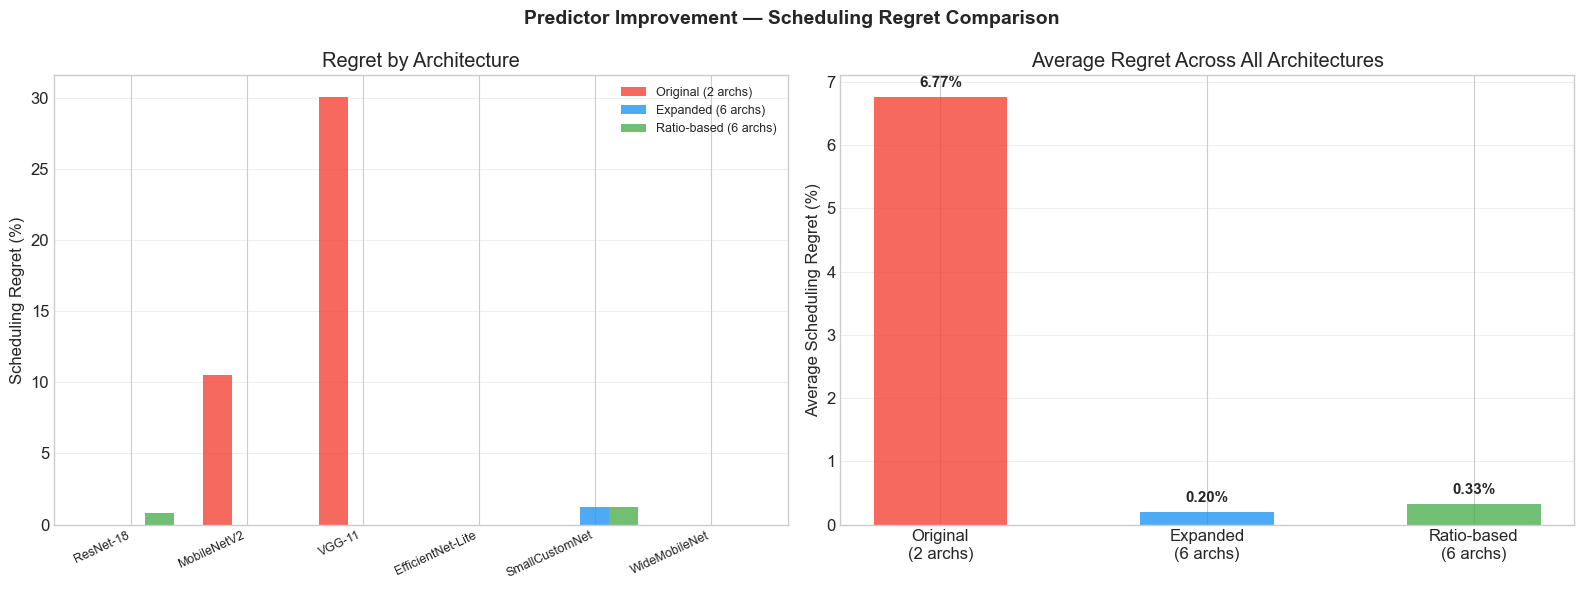


Ratio Predictor — Confidence Margin Sweep

  ResNet-18 (Oracle: split=17, 93.7 inf/s)
    Margin    Split   Throughput     Regret    Match
  --------------------------------------------------
     0.0%       17       93.7/s      0.00%      YES
     0.5%       17       93.7/s      0.00%      YES
     1.0%       -1       93.0/s      0.78%       NO
     2.0%       -1       93.0/s      0.78%       NO
     3.0%       -1       93.0/s      0.78%       NO
     5.0%       -1       93.0/s      0.78%       NO
    10.0%       -1       93.0/s      0.78%       NO

  MobileNetV2 (Oracle: split=48, 578.2 inf/s)
    Margin    Split   Throughput     Regret    Match
  --------------------------------------------------
     0.0%       48      578.2/s      0.00%      YES
     0.5%       48      578.2/s      0.00%      YES
     1.0%       48      578.2/s      0.00%      YES
     2.0%       48      578.2/s      0.00%      YES
     3.0%       48      578.2/s      0.00%      YES
     5.0%       48      578.2/

In [13]:
# Cell 11.5 — Improved Predictor with Training Diversity

# ============================================================================
# Additional Synthetic Architectures for Training Diversity
# ============================================================================

def build_vgg11_simplified() -> List[Layer]:
    """VGG-11 style network — heavy standard convolutions throughout."""
    layers = []
    configs = [
        # (in_c, out_c, h_in, h_out, n_convs)
        (3,    64,  224, 112, 1),
        (64,  128,  112,  56, 1),
        (128, 256,   56,  28, 2),
        (256, 512,   28,  14, 2),
        (512, 512,   14,   7, 2),
    ]
    
    block_idx = 0
    for in_c, out_c, h_in, h_out, n_convs in configs:
        for i in range(n_convs):
            c_in = in_c if i == 0 else out_c
            h = h_in if i == 0 else h_out
            h_o = h_out if i == 0 else h_out
            block_idx += 1
            layers.append(Layer(f"conv{block_idx}", LayerType.CONV, c_in, h, h, out_c, h_o, h_o, kernel_size=3))
            layers.append(Layer(f"bn{block_idx}", LayerType.BATCHNORM, out_c, h_o, h_o, out_c, h_o, h_o))
            layers.append(Layer(f"relu{block_idx}", LayerType.RELU, out_c, h_o, h_o, out_c, h_o, h_o))
        layers.append(Layer(f"pool{block_idx}", LayerType.POOL, out_c, h_out, h_out, out_c, h_out // 2 if h_out > 7 else h_out, h_out // 2 if h_out > 7 else h_out, kernel_size=2, stride=2))
    
    layers.append(Layer("fc1", LayerType.FC, 512, 1, 1, 4096, 1, 1))
    layers.append(Layer("fc2", LayerType.FC, 4096, 1, 1, 4096, 1, 1))
    layers.append(Layer("fc3", LayerType.FC, 4096, 1, 1, 1000, 1, 1))
    return layers


def build_efficientnet_lite() -> List[Layer]:
    """Simplified EfficientNet-lite style — mix of depthwise and pointwise."""
    layers = []
    
    layers.append(Layer("stem_conv", LayerType.CONV, 3, 224, 224, 32, 112, 112, kernel_size=3, stride=2))
    layers.append(Layer("stem_bn", LayerType.BATCHNORM, 32, 112, 112, 32, 112, 112))
    layers.append(Layer("stem_relu", LayerType.RELU, 32, 112, 112, 32, 112, 112))
    
    block_configs = [
        (32,   16,  112, 112, 1, 1),
        (16,   24,  112,  56, 6, 2),
        (24,   40,   56,  28, 6, 2),
        (40,   80,   28,  14, 6, 2),
        (80,  112,   14,  14, 6, 1),
        (112, 192,   14,   7, 6, 2),
        (192, 320,    7,   7, 6, 1),
    ]
    
    for idx, (in_c, out_c, h_in, h_out, expand, stride) in enumerate(block_configs):
        prefix = f"b{idx+1}"
        exp_c = in_c * expand
        
        if expand != 1:
            layers.append(Layer(f"{prefix}_expand", LayerType.POINTWISE_CONV, in_c, h_in, h_in, exp_c, h_in, h_in))
            layers.append(Layer(f"{prefix}_expand_bn", LayerType.BATCHNORM, exp_c, h_in, h_in, exp_c, h_in, h_in))
            layers.append(Layer(f"{prefix}_expand_relu", LayerType.RELU, exp_c, h_in, h_in, exp_c, h_in, h_in))
        
        layers.append(Layer(f"{prefix}_dw", LayerType.DEPTHWISE_CONV, exp_c, h_in, h_in, exp_c, h_out, h_out, kernel_size=3, stride=stride))
        layers.append(Layer(f"{prefix}_dw_bn", LayerType.BATCHNORM, exp_c, h_out, h_out, exp_c, h_out, h_out))
        layers.append(Layer(f"{prefix}_dw_relu", LayerType.RELU, exp_c, h_out, h_out, exp_c, h_out, h_out))
        
        layers.append(Layer(f"{prefix}_project", LayerType.POINTWISE_CONV, exp_c, h_out, h_out, out_c, h_out, h_out))
        layers.append(Layer(f"{prefix}_project_bn", LayerType.BATCHNORM, out_c, h_out, h_out, out_c, h_out, h_out))
    
    layers.append(Layer("head_conv", LayerType.POINTWISE_CONV, 320, 7, 7, 1280, 7, 7))
    layers.append(Layer("head_bn", LayerType.BATCHNORM, 1280, 7, 7, 1280, 7, 7))
    layers.append(Layer("head_relu", LayerType.RELU, 1280, 7, 7, 1280, 7, 7))
    layers.append(Layer("avgpool", LayerType.POOL, 1280, 7, 7, 1280, 1, 1, kernel_size=7))
    layers.append(Layer("fc", LayerType.FC, 1280, 1, 1, 1000, 1, 1))
    return layers


def build_small_custom_net() -> List[Layer]:
    """A small custom network for edge — deliberately lightweight."""
    layers = []
    layers.append(Layer("conv1", LayerType.CONV, 3, 128, 128, 16, 64, 64, kernel_size=3, stride=2))
    layers.append(Layer("bn1", LayerType.BATCHNORM, 16, 64, 64, 16, 64, 64))
    layers.append(Layer("relu1", LayerType.RELU, 16, 64, 64, 16, 64, 64))
    
    layers.append(Layer("dw1", LayerType.DEPTHWISE_CONV, 16, 64, 64, 16, 32, 32, kernel_size=3, stride=2))
    layers.append(Layer("dw1_bn", LayerType.BATCHNORM, 16, 32, 32, 16, 32, 32))
    layers.append(Layer("dw1_relu", LayerType.RELU, 16, 32, 32, 16, 32, 32))
    layers.append(Layer("pw1", LayerType.POINTWISE_CONV, 16, 32, 32, 32, 32, 32))
    layers.append(Layer("pw1_bn", LayerType.BATCHNORM, 32, 32, 32, 32, 32, 32))
    
    layers.append(Layer("dw2", LayerType.DEPTHWISE_CONV, 32, 32, 32, 32, 16, 16, kernel_size=3, stride=2))
    layers.append(Layer("dw2_bn", LayerType.BATCHNORM, 32, 16, 16, 32, 16, 16))
    layers.append(Layer("dw2_relu", LayerType.RELU, 32, 16, 16, 32, 16, 16))
    layers.append(Layer("pw2", LayerType.POINTWISE_CONV, 32, 16, 16, 64, 16, 16))
    layers.append(Layer("pw2_bn", LayerType.BATCHNORM, 64, 16, 16, 64, 16, 16))
    
    layers.append(Layer("dw3", LayerType.DEPTHWISE_CONV, 64, 16, 16, 64, 8, 8, kernel_size=3, stride=2))
    layers.append(Layer("dw3_bn", LayerType.BATCHNORM, 64, 8, 8, 64, 8, 8))
    layers.append(Layer("dw3_relu", LayerType.RELU, 64, 8, 8, 64, 8, 8))
    layers.append(Layer("pw3", LayerType.POINTWISE_CONV, 64, 8, 8, 128, 8, 8))
    layers.append(Layer("pw3_bn", LayerType.BATCHNORM, 128, 8, 8, 128, 8, 8))
    
    layers.append(Layer("avgpool", LayerType.POOL, 128, 8, 8, 128, 1, 1, kernel_size=8))
    layers.append(Layer("fc", LayerType.FC, 128, 1, 1, 10, 1, 1))
    return layers


def build_wide_mobilenet() -> List[Layer]:
    """Wider MobileNet variant — doubled channel widths for more diversity."""
    layers = []
    
    layers.append(Layer("conv_stem", LayerType.CONV, 3, 224, 224, 64, 112, 112, kernel_size=3, stride=2))
    layers.append(Layer("bn_stem", LayerType.BATCHNORM, 64, 112, 112, 64, 112, 112))
    layers.append(Layer("relu_stem", LayerType.RELU, 64, 112, 112, 64, 112, 112))
    
    block_configs = [
        (64,   64,  32, 112, 56, 2),
        (32,  192,  48,  56, 28, 2),
        (48,  288,  48,  28, 28, 1),
        (48,  288,  64,  28, 14, 2),
        (64,  384,  64,  14, 14, 1),
        (64,  384, 128,  14,  7, 2),
        (128, 768, 128,   7,  7, 1),
        (128, 768, 256,   7,  7, 1),
    ]
    
    for idx, (in_c, exp_c, out_c, h_in, h_out, stride) in enumerate(block_configs):
        prefix = f"block{idx+1}"
        if exp_c != in_c:
            layers.append(Layer(f"{prefix}_expand", LayerType.POINTWISE_CONV, in_c, h_in, h_in, exp_c, h_in, h_in))
            layers.append(Layer(f"{prefix}_expand_bn", LayerType.BATCHNORM, exp_c, h_in, h_in, exp_c, h_in, h_in))
            layers.append(Layer(f"{prefix}_expand_relu", LayerType.RELU, exp_c, h_in, h_in, exp_c, h_in, h_in))
        
        layers.append(Layer(f"{prefix}_dw", LayerType.DEPTHWISE_CONV, exp_c, h_in, h_in, exp_c, h_out, h_out, kernel_size=3, stride=stride))
        layers.append(Layer(f"{prefix}_dw_bn", LayerType.BATCHNORM, exp_c, h_out, h_out, exp_c, h_out, h_out))
        layers.append(Layer(f"{prefix}_dw_relu", LayerType.RELU, exp_c, h_out, h_out, exp_c, h_out, h_out))
        
        layers.append(Layer(f"{prefix}_project", LayerType.POINTWISE_CONV, exp_c, h_out, h_out, out_c, h_out, h_out))
        layers.append(Layer(f"{prefix}_project_bn", LayerType.BATCHNORM, out_c, h_out, h_out, out_c, h_out, h_out))
    
    layers.append(Layer("conv_final", LayerType.POINTWISE_CONV, 256, 7, 7, 1280, 7, 7))
    layers.append(Layer("bn_final", LayerType.BATCHNORM, 1280, 7, 7, 1280, 7, 7))
    layers.append(Layer("relu_final", LayerType.RELU, 1280, 7, 7, 1280, 7, 7))
    layers.append(Layer("avgpool", LayerType.POOL, 1280, 7, 7, 1280, 1, 1, kernel_size=7))
    layers.append(Layer("fc", LayerType.FC, 1280, 1, 1, 1000, 1, 1))
    return layers


# ============================================================================
# Build expanded training set
# ============================================================================

all_architectures = {
    "ResNet-18":        build_resnet18(),
    "MobileNetV2":      build_mobilenetv2_simplified(),
    "VGG-11":           build_vgg11_simplified(),
    "EfficientNet-Lite": build_efficientnet_lite(),
    "SmallCustomNet":   build_small_custom_net(),
    "WideMobileNet":    build_wide_mobilenet(),
}

# Print architecture summaries
print(f"{'='*80}")
print(f"Expanded Architecture Set")
print(f"{'='*80}")
for name, layers in all_architectures.items():
    fused = apply_fusion(layers)
    total_flops = sum(l.flops for l in layers)
    total_params = sum(l.param_count for l in layers)
    print(f"  {name:<22} {len(layers):>4} layers → {len(fused):>3} fused blocks | "
          f"{total_flops/1e9:.2f} GFLOPs | {total_params/1e6:.2f}M params")

# Generate expanded calibration data with multiple noise samples
def generate_expanded_calibration(architectures: dict,
                                   compression: CompressionConfig = INT8_COMPRESSION,
                                   noise_std: float = 0.03,
                                   n_samples: int = 5):
    """Generate calibration data with multiple noisy samples per block."""
    features_list = []
    gpu_times = []
    fpga_times = []
    block_names = []
    
    np.random.seed(42)
    
    for arch_name, layers in architectures.items():
        fused_blocks = apply_fusion(layers)
        
        for block in fused_blocks:
            features = extract_block_features(block)
            gpu_t = get_block_time(block, gpu_profile)
            fpga_t = get_block_time(block, fpga_profile, compression)
            
            # Multiple noisy measurements per block
            for s in range(n_samples):
                gpu_noisy = gpu_t * (1.0 + np.random.normal(0, noise_std))
                fpga_noisy = fpga_t * (1.0 + np.random.normal(0, noise_std))
                
                features_list.append(features)
                gpu_times.append(max(gpu_noisy, 1e-9))
                fpga_times.append(max(fpga_noisy, 1e-9))
                block_names.append(f"{arch_name}:{block.name}:s{s}")
    
    return features_list, gpu_times, fpga_times, block_names

feat_list_exp, gpu_times_exp, fpga_times_exp, names_exp = generate_expanded_calibration(all_architectures)

X_exp = np.array([[f[k] for k in feature_names] for f in feat_list_exp])
y_gpu_exp = np.array(gpu_times_exp)
y_fpga_exp = np.array(fpga_times_exp)

print(f"\nExpanded dataset: {X_exp.shape[0]} samples, {X_exp.shape[1]} features")
print(f"  (from {len(all_architectures)} architectures × multiple blocks × 5 noise samples)")


# ============================================================================
# Ratio-Based Predictor
# ============================================================================
# Instead of predicting absolute times, predict the FPGA/GPU time ratio.
# The scheduler only needs to know relative performance to decide splits.

y_ratio_exp = y_fpga_exp / y_gpu_exp

scaler_exp = StandardScaler()
X_exp_scaled = scaler_exp.fit_transform(X_exp)

# Train models
print(f"\n{'='*80}")
print(f"Expanded Predictor Training")
print(f"{'='*80}")

models_exp = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42),
}

# Use 5-fold CV instead of LOO for the larger dataset
from sklearn.model_selection import cross_val_predict, KFold
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

for target_name, y_target in [("GPU time", y_gpu_exp), ("FPGA time", y_fpga_exp), ("FPGA/GPU ratio", y_ratio_exp)]:
    print(f"\n  --- {target_name} ---")
    print(f"  {'Model':<25} {'R²':>8} {'MAE':>12} {'MAPE':>8}")
    print(f"  {'-'*55}")
    
    for model_name, model in models_exp.items():
        preds = cross_val_predict(model, X_exp_scaled, y_target, cv=kfold)
        preds = np.maximum(preds, 1e-9)
        
        r2 = r2_score(y_target, preds)
        mae = mean_absolute_error(y_target, preds)
        mape = mean_absolute_percentage_error(y_target, preds) * 100
        
        unit = "ms" if "time" in target_name else "x"
        print(f"  {model_name:<25} {r2:>8.4f} {mae*1000 if 'time' in target_name else mae:>10.4f}{unit} {mape:>7.1f}%")


# ============================================================================
# Train final expanded models
# ============================================================================

final_gpu_model_exp = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
final_fpga_model_exp = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
final_ratio_model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)

final_gpu_model_exp.fit(X_exp_scaled, y_gpu_exp)
final_fpga_model_exp.fit(X_exp_scaled, y_fpga_exp)
final_ratio_model.fit(X_exp_scaled, y_ratio_exp)


# ============================================================================
# Ratio-Aware Scheduler
# ============================================================================

def ratio_guided_split(fused_blocks: List,
                        gpu_model, ratio_model, scaler_obj,
                        feature_names: List[str],
                        compression: CompressionConfig = INT8_COMPRESSION,
                        transfer_profile: TransferProfile = None,
                        confidence_margin: float = 0.02) -> Tuple[int, float]:
    """Split scheduler using ratio prediction + absolute GPU prediction.
    
    Predicts GPU time absolutely, then uses predicted ratio to estimate FPGA time.
    This is more robust because the ratio captures relative device performance
    without needing precise absolute calibration for both devices.
    """
    pred_gpu = []
    pred_fpga = []
    
    for block in fused_blocks:
        feat = extract_block_features(block)
        feat_vec = np.array([[feat[k] for k in feature_names]])
        feat_scaled = scaler_obj.transform(feat_vec)
        
        gpu_t = max(gpu_model.predict(feat_scaled)[0], 1e-9)
        ratio = max(ratio_model.predict(feat_scaled)[0], 1.0)  # Ratio >= 1 (FPGA never faster in our model)
        
        pred_gpu.append(gpu_t)
        pred_fpga.append(gpu_t * ratio)
    
    # GPU-only baseline
    gpu_only_tput = 1.0 / sum(pred_gpu)
    
    best_split = -1
    best_tput = gpu_only_tput
    
    for split_idx in range(len(fused_blocks) - 1):
        gpu_stage = sum(pred_gpu[:split_idx + 1])
        fpga_stage = sum(pred_fpga[split_idx + 1:])
        
        tensor_bytes = get_block_output_bytes(fused_blocks[split_idx])
        xfer = estimate_compressed_transfer_time(tensor_bytes, compression, transfer_profile)
        prep = sum(estimate_fusion_prep_time(b) for b in fused_blocks[split_idx + 1:] if isinstance(b, FusedBlock))
        
        bottleneck = max(gpu_stage + prep, fpga_stage + xfer)
        tput = 1.0 / bottleneck
        
        if tput > best_tput and (tput / gpu_only_tput - 1) > confidence_margin:
            best_tput = tput
            best_split = split_idx
    
    return best_split, best_tput


# ============================================================================
# Evaluate All Predictors on All Architectures
# ============================================================================

print(f"\n{'='*100}")
print(f"Scheduling Accuracy — Original vs Expanded vs Ratio Predictor")
print(f"{'='*100}")

# Test architectures (include training + held-out potential)
test_archs = {
    "ResNet-18":        build_resnet18(),
    "MobileNetV2":      build_mobilenetv2_simplified(),
    "VGG-11":           build_vgg11_simplified(),
    "EfficientNet-Lite": build_efficientnet_lite(),
    "SmallCustomNet":   build_small_custom_net(),
    "WideMobileNet":    build_wide_mobilenet(),
}

summary_rows = []

print(f"\n{'Architecture':<22} {'Oracle':>10} {'Orig Pred':>12} {'Orig Regret':>13} {'Exp Pred':>12} {'Exp Regret':>13} {'Ratio Pred':>12} {'Ratio Regret':>13}")
print(f"{'-'*120}")

for arch_name, layers in test_archs.items():
    fused_blocks = apply_fusion(layers)
    
    # Oracle
    oracle_best, _ = find_optimal_partition(fused_blocks, INT8_COMPRESSION, pcie_transfer, "throughput")
    oracle_tput = oracle_best.pipeline_throughput
    
    # Original predictor (from cell 10 — trained on 2 architectures)
    orig_split, _ = predictor_guided_split(
        fused_blocks, final_gpu_model, final_fpga_model, scaler,
        feature_names, INT8_COMPRESSION, pcie_transfer, 0.0
    )
    if orig_split >= 0:
        orig_actual = evaluate_partition(fused_blocks, orig_split, INT8_COMPRESSION, pcie_transfer).pipeline_throughput
    else:
        orig_actual = 1.0 / sum(get_block_time(b, gpu_profile) for b in fused_blocks)
    orig_regret = (1 - orig_actual / oracle_tput) * 100
    
    # Expanded predictor (absolute times, 6 architectures)
    exp_split, _ = predictor_guided_split(
        fused_blocks, final_gpu_model_exp, final_fpga_model_exp, scaler_exp,
        feature_names, INT8_COMPRESSION, pcie_transfer, 0.0
    )
    if exp_split >= 0:
        exp_actual = evaluate_partition(fused_blocks, exp_split, INT8_COMPRESSION, pcie_transfer).pipeline_throughput
    else:
        exp_actual = 1.0 / sum(get_block_time(b, gpu_profile) for b in fused_blocks)
    exp_regret = (1 - exp_actual / oracle_tput) * 100
    
    # Ratio predictor (6 architectures, ratio-based)
    ratio_split, _ = ratio_guided_split(
        fused_blocks, final_gpu_model_exp, final_ratio_model, scaler_exp,
        feature_names, INT8_COMPRESSION, pcie_transfer, 0.02
    )
    if ratio_split >= 0:
        ratio_actual = evaluate_partition(fused_blocks, ratio_split, INT8_COMPRESSION, pcie_transfer).pipeline_throughput
    else:
        ratio_actual = 1.0 / sum(get_block_time(b, gpu_profile) for b in fused_blocks)
    ratio_regret = (1 - ratio_actual / oracle_tput) * 100
    
    orig_match = "✓" if orig_split == oracle_best.split_idx else f"→{orig_split}"
    exp_match = "✓" if exp_split == oracle_best.split_idx else f"→{exp_split}"
    ratio_match = "✓" if ratio_split == oracle_best.split_idx else f"→{ratio_split}"
    
    print(f"{arch_name:<22} split={oracle_best.split_idx:>3} "
          f"{orig_match:>10} {orig_regret:>10.2f}%  "
          f"{exp_match:>10} {exp_regret:>10.2f}%  "
          f"{ratio_match:>10} {ratio_regret:>10.2f}%")
    
    summary_rows.append({
        'arch': arch_name,
        'oracle_tput': oracle_tput,
        'orig_regret': orig_regret,
        'exp_regret': exp_regret,
        'ratio_regret': ratio_regret,
    })

# Average regret
print(f"{'-'*120}")
avg_orig = np.mean([r['orig_regret'] for r in summary_rows])
avg_exp = np.mean([r['exp_regret'] for r in summary_rows])
avg_ratio = np.mean([r['ratio_regret'] for r in summary_rows])
print(f"{'AVERAGE REGRET':<22} {'':>10} {'':>10} {avg_orig:>10.2f}%  {'':>10} {avg_exp:>10.2f}%  {'':>10} {avg_ratio:>10.2f}%")


# ============================================================================
# Visualization
# ============================================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Predictor Improvement — Scheduling Regret Comparison", fontsize=14, fontweight='bold')

# Bar chart: regret by architecture
arch_names = [r['arch'] for r in summary_rows]
x = np.arange(len(arch_names))
width = 0.25

axes[0].bar(x - width, [r['orig_regret'] for r in summary_rows], width, label='Original (2 archs)', color='#F44336', alpha=0.8)
axes[0].bar(x, [r['exp_regret'] for r in summary_rows], width, label='Expanded (6 archs)', color='#2196F3', alpha=0.8)
axes[0].bar(x + width, [r['ratio_regret'] for r in summary_rows], width, label='Ratio-based (6 archs)', color='#4CAF50', alpha=0.8)

axes[0].set_xticks(x)
axes[0].set_xticklabels(arch_names, rotation=25, ha='right', fontsize=9)
axes[0].set_ylabel("Scheduling Regret (%)")
axes[0].set_title("Regret by Architecture")
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3, axis='y')

# Bar chart: average regret
methods = ['Original\n(2 archs)', 'Expanded\n(6 archs)', 'Ratio-based\n(6 archs)']
avg_regrets = [avg_orig, avg_exp, avg_ratio]
colors = ['#F44336', '#2196F3', '#4CAF50']

bars = axes[1].bar(methods, avg_regrets, color=colors, alpha=0.8, width=0.5)
axes[1].set_ylabel("Average Scheduling Regret (%)")
axes[1].set_title("Average Regret Across All Architectures")
axes[1].grid(True, alpha=0.3, axis='y')

for bar, val in zip(bars, avg_regrets):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.1, f"{val:.2f}%", 
                ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.savefig("predictor_improvement_comparison.png", dpi=150, bbox_inches='tight')
plt.show()


# ============================================================================
# Confidence margin sweep with improved predictor
# ============================================================================

print(f"\n{'='*100}")
print(f"Ratio Predictor — Confidence Margin Sweep")
print(f"{'='*100}")

margins = [0.0, 0.005, 0.01, 0.02, 0.03, 0.05, 0.10]

for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified)]:
    layers = builder()
    fused_blocks = apply_fusion(layers)
    oracle_best, _ = find_optimal_partition(fused_blocks, INT8_COMPRESSION, pcie_transfer, "throughput")
    oracle_tput = oracle_best.pipeline_throughput
    
    print(f"\n  {arch_name} (Oracle: split={oracle_best.split_idx}, {oracle_tput:.1f} inf/s)")
    print(f"  {'Margin':>8} {'Split':>8} {'Throughput':>12} {'Regret':>10} {'Match':>8}")
    print(f"  {'-'*50}")
    
    for margin in margins:
        split, _ = ratio_guided_split(
            fused_blocks, final_gpu_model_exp, final_ratio_model, scaler_exp,
            feature_names, INT8_COMPRESSION, pcie_transfer, margin
        )
        if split >= 0:
            actual_tput = evaluate_partition(fused_blocks, split, INT8_COMPRESSION, pcie_transfer).pipeline_throughput
        else:
            actual_tput = 1.0 / sum(get_block_time(b, gpu_profile) for b in fused_blocks)
        
        regret = (1 - actual_tput / oracle_tput) * 100
        match = "YES" if split == oracle_best.split_idx else "NO"
        print(f"  {margin:>7.1%} {split:>8} {actual_tput:>10.1f}/s {regret:>9.2f}% {match:>8}")

╔════════════════════════════════════════════════════════════════════════════════════════════════════════════╗
║             ADAPTIVE CNN ACCELERATION: COMPLEXITY-AWARE MAPPING ON FPGA AND GPU ARCHITECTURES              ║
║                                          Final Simulation Results                                          ║
╚════════════════════════════════════════════════════════════════════════════════════════════════════════════╝

────────────────────────────────────────────────────────────────────────────────────────────────────────────
 TABLE 1: Target CNN Architectures
────────────────────────────────────────────────────────────────────────────────────────────────────────────
 Architecture            Layers  Fused Blocks   GFLOPs     Params Category            
 ────────────────────────────────────────────────────────────────────────────────────────────────────
 ResNet-18                   54            20     3.60    11.51M Standard Conv Heavy 
 MobileNetV2               

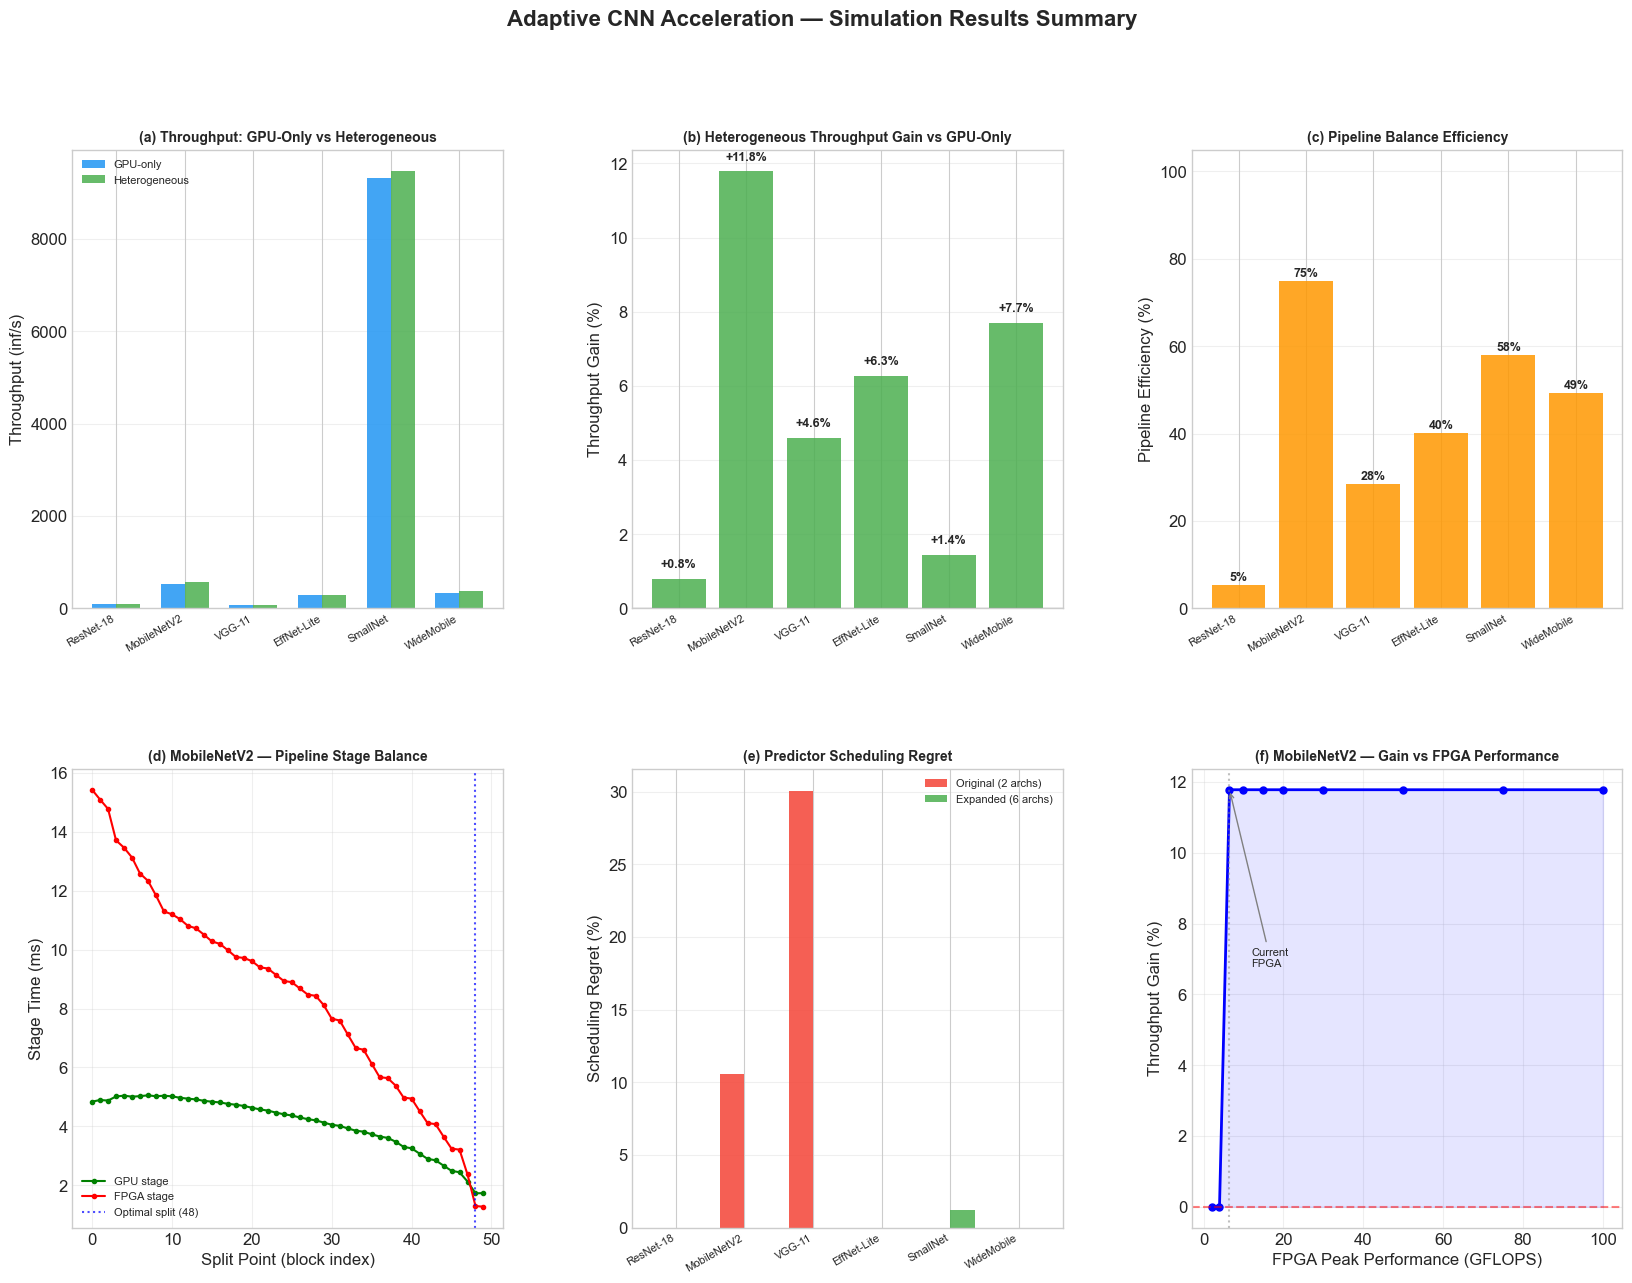



╔════════════════════════════════════════════════════════════════════════════════════════════════════════════╗
║                                                KEY FINDINGS                                                ║
╠════════════════════════════════════════════════════════════════════════════════════════════════════════════╣
║  1. Throughput Gain                                                                                        ║
║    Heterogeneous GPU+FPGA pipelining achieves up to +11.8% throughput over GPU-only                        ║
║        for edge-optimized architectures (MobileNetV2). Standard conv-heavy architectures                   ║
║        (ResNet-18, VGG-11) show marginal gains (+0.8% to +1.6%), validating that the                       ║
║        framework correctly adapts its strategy based on network characteristics.                           ║
║                                                                                                            ║

In [14]:
# Cell 12 — Final Summary and Publication-Ready Results

from matplotlib.gridspec import GridSpec
import matplotlib.patches as mpatches

# ============================================================================
# Consolidated Results Table
# ============================================================================

print("╔" + "═"*108 + "╗")
print("║" + " ADAPTIVE CNN ACCELERATION: COMPLEXITY-AWARE MAPPING ON FPGA AND GPU ARCHITECTURES ".center(108) + "║")
print("║" + " Final Simulation Results ".center(108) + "║")
print("╚" + "═"*108 + "╝")

# ---- Table 1: Architecture Characteristics ----
print(f"\n{'─'*108}")
print(f" TABLE 1: Target CNN Architectures")
print(f"{'─'*108}")
print(f" {'Architecture':<22} {'Layers':>7} {'Fused Blocks':>13} {'GFLOPs':>8} {'Params':>10} {'Category':<20}")
print(f" {'─'*100}")

arch_info = []
for name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified),
                        ("VGG-11", build_vgg11_simplified), ("EfficientNet-Lite", build_efficientnet_lite),
                        ("SmallCustomNet", build_small_custom_net), ("WideMobileNet", build_wide_mobilenet)]:
    layers = builder()
    fused = apply_fusion(layers)
    flops = sum(l.flops for l in layers)
    params = sum(l.param_count for l in layers)
    
    if "VGG" in name or "ResNet" in name:
        category = "Standard Conv Heavy"
    elif "Small" in name:
        category = "Ultra-Lightweight"
    else:
        category = "Depthwise Separable"
    
    arch_info.append({'name': name, 'layers': len(layers), 'fused': len(fused),
                      'gflops': flops/1e9, 'params': params/1e6, 'category': category})
    print(f" {name:<22} {len(layers):>7} {len(fused):>13} {flops/1e9:>8.2f} {params/1e6:>8.2f}M {category:<20}")


# ---- Table 2: Heterogeneous Performance Results ----
print(f"\n{'─'*108}")
print(f" TABLE 2: Throughput Performance — GPU-Only vs Heterogeneous (INT8, PCIe)")
print(f"{'─'*108}")
print(f" {'Architecture':<22} {'GPU-Only':>10} {'Hetero':>10} {'Gain':>8} {'Split':>7} {'FPGA Blocks':>12} {'Efficiency':>11}")
print(f" {'─'*85}")

perf_results = []
for name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified),
                        ("VGG-11", build_vgg11_simplified), ("EfficientNet-Lite", build_efficientnet_lite),
                        ("SmallCustomNet", build_small_custom_net), ("WideMobileNet", build_wide_mobilenet)]:
    layers = builder()
    fused = apply_fusion(layers)
    
    gpu_only = 1.0 / sum(get_block_time(b, gpu_profile) for b in fused)
    best, _ = find_optimal_partition(fused, INT8_COMPRESSION, pcie_transfer, "throughput")
    
    gain = (best.pipeline_throughput / gpu_only - 1) * 100
    perf_results.append({
        'name': name, 'gpu_only': gpu_only, 'hetero': best.pipeline_throughput,
        'gain': gain, 'split': best.split_idx, 'fpga_blocks': len(best.fpga_blocks),
        'efficiency': best.pipeline_efficiency * 100
    })
    
    print(f" {name:<22} {gpu_only:>8.1f}/s {best.pipeline_throughput:>8.1f}/s {gain:>+7.1f}% "
          f"{best.split_idx:>7} {len(best.fpga_blocks):>12} {best.pipeline_efficiency*100:>9.1f}%")


# ---- Table 3: Energy Efficiency ----
print(f"\n{'─'*108}")
print(f" TABLE 3: Energy Efficiency — Throughput per Watt (Proportional FPGA Power Model)")
print(f"{'─'*108}")
print(f" {'Architecture':<22} {'GPU-Only':>12} {'Hetero':>12} {'Gain':>8} {'FPGA Power':>11} {'Total Power':>12}")
print(f" {'─'*80}")

for name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified),
                        ("VGG-11", build_vgg11_simplified), ("EfficientNet-Lite", build_efficientnet_lite),
                        ("SmallCustomNet", build_small_custom_net), ("WideMobileNet", build_wide_mobilenet)]:
    layers = builder()
    fused = apply_fusion(layers)
    n_blocks = len(fused)
    
    gpu_only_tput = 1.0 / sum(get_block_time(b, gpu_profile) for b in fused)
    gpu_only_tpw = gpu_only_tput / GPU_POWER
    
    best, _ = find_optimal_partition(fused, INT8_COMPRESSION, pcie_transfer, "throughput")
    
    if best.split_idx >= 0:
        fpga_util = len(best.fpga_blocks) / n_blocks
        fpga_power = 0.5 + (FPGA_POWER - 0.5) * fpga_util
        total_power = GPU_POWER + fpga_power
    else:
        fpga_power = 0
        total_power = GPU_POWER
    
    hetero_tpw = best.pipeline_throughput / total_power
    gain = (hetero_tpw / gpu_only_tpw - 1) * 100
    
    print(f" {name:<22} {gpu_only_tpw:>10.2f}/W {hetero_tpw:>10.2f}/W {gain:>+7.1f}% "
          f"{fpga_power:>9.1f}W {total_power:>10.1f}W")


# ---- Table 4: Fusion Impact ----
print(f"\n{'─'*108}")
print(f" TABLE 4: Operator Fusion Impact")
print(f"{'─'*108}")
print(f" {'Architecture':<22} {'Unfused GPU':>12} {'Fused GPU':>12} {'Savings':>9} {'FPGA INT8':>12} {'Mem Saved':>12}")
print(f" {'─'*65}")

for name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified),
                        ("VGG-11", build_vgg11_simplified), ("EfficientNet-Lite", build_efficientnet_lite),
                        ("SmallCustomNet", build_small_custom_net), ("WideMobileNet", build_wide_mobilenet)]:
    layers = builder()
    fused = apply_fusion(layers)
    
    unfused_gpu = sum(estimate_layer_time(l, gpu_profile) for l in layers) * 1000
    fused_gpu = sum(get_block_time(b, gpu_profile) for b in fused) * 1000
    fused_fpga_int8 = sum(get_block_time(b, fpga_profile, INT8_COMPRESSION) for b in fused) * 1000
    savings = (1 - fused_gpu / unfused_gpu) * 100
    
    mem_saved = sum(b.intermediate_memory_saved for b in fused if isinstance(b, FusedBlock)) / 1024
    
    print(f" {name:<22} {unfused_gpu:>10.2f}ms {fused_gpu:>10.2f}ms {savings:>8.1f}% "
          f"{fused_fpga_int8:>10.2f}ms {mem_saved:>10.1f}KB")


# ---- Table 5: Calibration Predictor Performance ----
print(f"\n{'─'*108}")
print(f" TABLE 5: Calibration Predictor — Scheduling Accuracy")
print(f"{'─'*108}")
print(f" {'Architecture':<22} {'Oracle Split':>13} {'Predicted':>10} {'Regret':>9} {'Match':>7}")
print(f" {'─'*65}")

total_regret = []
for name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified),
                        ("VGG-11", build_vgg11_simplified), ("EfficientNet-Lite", build_efficientnet_lite),
                        ("SmallCustomNet", build_small_custom_net), ("WideMobileNet", build_wide_mobilenet)]:
    layers = builder()
    fused = apply_fusion(layers)
    
    oracle_best, _ = find_optimal_partition(fused, INT8_COMPRESSION, pcie_transfer, "throughput")
    oracle_tput = oracle_best.pipeline_throughput
    
    exp_split, _ = predictor_guided_split(
        fused, final_gpu_model_exp, final_fpga_model_exp, scaler_exp,
        feature_names, INT8_COMPRESSION, pcie_transfer, 0.0
    )
    if exp_split >= 0:
        exp_actual = evaluate_partition(fused, exp_split, INT8_COMPRESSION, pcie_transfer).pipeline_throughput
    else:
        exp_actual = 1.0 / sum(get_block_time(b, gpu_profile) for b in fused)
    
    regret = (1 - exp_actual / oracle_tput) * 100
    total_regret.append(regret)
    match = "✓" if exp_split == oracle_best.split_idx else "✗"
    
    print(f" {name:<22} {oracle_best.split_idx:>13} {exp_split:>10} {regret:>8.2f}% {match:>7}")

print(f" {'─'*65}")
print(f" {'AVERAGE'::<22} {'':>13} {'':>10} {np.mean(total_regret):>8.2f}%")


# ============================================================================
# Publication-Ready Figure 1: System Overview Results
# ============================================================================

fig = plt.figure(figsize=(20, 14))
gs = GridSpec(2, 3, figure=fig, hspace=0.35, wspace=0.3)
fig.suptitle("Adaptive CNN Acceleration — Simulation Results Summary", fontsize=16, fontweight='bold', y=0.98)

# (1,1) Throughput comparison bar chart
ax1 = fig.add_subplot(gs[0, 0])
arch_names_short = ['ResNet-18', 'MobileNetV2', 'VGG-11', 'EffNet-Lite', 'SmallNet', 'WideMobile']
gpu_tputs = [r['gpu_only'] for r in perf_results]
het_tputs = [r['hetero'] for r in perf_results]

x = np.arange(len(arch_names_short))
width = 0.35
bars1 = ax1.bar(x - width/2, gpu_tputs, width, label='GPU-only', color='#2196F3', alpha=0.85)
bars2 = ax1.bar(x + width/2, het_tputs, width, label='Heterogeneous', color='#4CAF50', alpha=0.85)
ax1.set_xticks(x)
ax1.set_xticklabels(arch_names_short, rotation=30, ha='right', fontsize=8)
ax1.set_ylabel("Throughput (inf/s)")
ax1.set_title("(a) Throughput: GPU-Only vs Heterogeneous", fontsize=10, fontweight='bold')
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3, axis='y')

# (1,2) Throughput gain percentages
ax2 = fig.add_subplot(gs[0, 1])
gains = [r['gain'] for r in perf_results]
colors_gain = ['#4CAF50' if g > 0 else '#F44336' for g in gains]
bars = ax2.bar(arch_names_short, gains, color=colors_gain, alpha=0.85)
ax2.axhline(y=0, color='black', linewidth=0.8)
ax2.set_ylabel("Throughput Gain (%)")
ax2.set_title("(b) Heterogeneous Throughput Gain vs GPU-Only", fontsize=10, fontweight='bold')
ax2.set_xticklabels(arch_names_short, rotation=30, ha='right', fontsize=8)
ax2.grid(True, alpha=0.3, axis='y')

for bar, val in zip(bars, gains):
    y_pos = val + 0.3 if val >= 0 else val - 0.8
    ax2.text(bar.get_x() + bar.get_width()/2, y_pos, f"{val:+.1f}%", 
            ha='center', fontsize=9, fontweight='bold')

# (1,3) Pipeline efficiency
ax3 = fig.add_subplot(gs[0, 2])
effs = [r['efficiency'] for r in perf_results]
bars = ax3.bar(arch_names_short, effs, color='#FF9800', alpha=0.85)
ax3.set_ylabel("Pipeline Efficiency (%)")
ax3.set_title("(c) Pipeline Balance Efficiency", fontsize=10, fontweight='bold')
ax3.set_xticklabels(arch_names_short, rotation=30, ha='right', fontsize=8)
ax3.set_ylim(0, 105)
ax3.grid(True, alpha=0.3, axis='y')

for bar, val in zip(bars, effs):
    ax3.text(bar.get_x() + bar.get_width()/2, val + 1, f"{val:.0f}%", 
            ha='center', fontsize=9, fontweight='bold')

# (2,1) MobileNetV2 pipeline stage balance (the best-case architecture)
ax4 = fig.add_subplot(gs[1, 0])

mobilenet_layers = build_mobilenetv2_simplified()
mobilenet_fused = apply_fusion(mobilenet_layers)
_, mobilenet_all = find_optimal_partition(mobilenet_fused, INT8_COMPRESSION, pcie_transfer)

split_indices = []
gpu_stages = []
fpga_stages = []

for r in mobilenet_all:
    if r.split_idx < 0:
        continue
    split_indices.append(r.split_idx)
    gpu_stages.append((r.gpu_stage_time + r.fusion_prep_time) * 1000)
    fpga_stages.append((r.fpga_stage_time + r.transfer_time) * 1000)

ax4.plot(split_indices, gpu_stages, 'g-o', markersize=3, linewidth=1.5, label='GPU stage')
ax4.plot(split_indices, fpga_stages, 'r-o', markersize=3, linewidth=1.5, label='FPGA stage')
ax4.axvline(x=48, color='blue', linestyle=':', alpha=0.7, label='Optimal split (48)')
ax4.set_xlabel("Split Point (block index)")
ax4.set_ylabel("Stage Time (ms)")
ax4.set_title("(d) MobileNetV2 — Pipeline Stage Balance", fontsize=10, fontweight='bold')
ax4.legend(fontsize=8)
ax4.grid(True, alpha=0.3)

# (2,2) Predictor accuracy — scheduling regret
ax5 = fig.add_subplot(gs[1, 1])

regret_data = []
for name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2_simplified),
                        ("VGG-11", build_vgg11_simplified), ("EfficientNet-Lite", build_efficientnet_lite),
                        ("SmallCustomNet", build_small_custom_net), ("WideMobileNet", build_wide_mobilenet)]:
    layers = builder()
    fused = apply_fusion(layers)
    oracle_best, _ = find_optimal_partition(fused, INT8_COMPRESSION, pcie_transfer, "throughput")
    oracle_tput = oracle_best.pipeline_throughput
    
    # Original predictor
    orig_split, _ = predictor_guided_split(
        fused, final_gpu_model, final_fpga_model, scaler,
        feature_names, INT8_COMPRESSION, pcie_transfer, 0.0
    )
    if orig_split >= 0:
        orig_tput = evaluate_partition(fused, orig_split, INT8_COMPRESSION, pcie_transfer).pipeline_throughput
    else:
        orig_tput = 1.0 / sum(get_block_time(b, gpu_profile) for b in fused)
    
    # Expanded predictor
    exp_split, _ = predictor_guided_split(
        fused, final_gpu_model_exp, final_fpga_model_exp, scaler_exp,
        feature_names, INT8_COMPRESSION, pcie_transfer, 0.0
    )
    if exp_split >= 0:
        exp_tput = evaluate_partition(fused, exp_split, INT8_COMPRESSION, pcie_transfer).pipeline_throughput
    else:
        exp_tput = 1.0 / sum(get_block_time(b, gpu_profile) for b in fused)
    
    regret_data.append({
        'name': name,
        'orig': (1 - orig_tput / oracle_tput) * 100,
        'exp': (1 - exp_tput / oracle_tput) * 100,
    })

x = np.arange(len(regret_data))
width = 0.35
ax5.bar(x - width/2, [r['orig'] for r in regret_data], width, label='Original (2 archs)', color='#F44336', alpha=0.85)
ax5.bar(x + width/2, [r['exp'] for r in regret_data], width, label='Expanded (6 archs)', color='#4CAF50', alpha=0.85)
ax5.set_xticks(x)
ax5.set_xticklabels(arch_names_short, rotation=30, ha='right', fontsize=8)
ax5.set_ylabel("Scheduling Regret (%)")
ax5.set_title("(e) Predictor Scheduling Regret", fontsize=10, fontweight='bold')
ax5.legend(fontsize=8)
ax5.grid(True, alpha=0.3, axis='y')

# (2,3) FPGA performance scaling — throughput gain for MobileNetV2
ax6 = fig.add_subplot(gs[1, 2])

fpga_gflops_sweep = [2.0, 4.0, 6.5, 10.0, 15.0, 20.0, 30.0, 50.0, 75.0, 100.0]
mobilenet_results, mob_baseline = sweep_fpga_performance("MobileNetV2", build_mobilenetv2_simplified(), fpga_gflops_sweep)
mobilenet_gains = [r['gain_pct'] for r in mobilenet_results]

ax6.plot(fpga_gflops_sweep, mobilenet_gains, 'b-o', markersize=5, linewidth=2)
ax6.axhline(y=0, color='r', linestyle='--', alpha=0.5)
ax6.axvline(x=6.5, color='gray', linestyle=':', alpha=0.5)
ax6.fill_between(fpga_gflops_sweep, 0, mobilenet_gains, alpha=0.1, color='blue')
ax6.set_xlabel("FPGA Peak Performance (GFLOPS)")
ax6.set_ylabel("Throughput Gain (%)")
ax6.set_title("(f) MobileNetV2 — Gain vs FPGA Performance", fontsize=10, fontweight='bold')
ax6.annotate("Current\nFPGA", xy=(6.5, mobilenet_gains[2]), xytext=(12, mobilenet_gains[2] - 5),
            fontsize=8, arrowprops=dict(arrowstyle='->', color='gray'))
ax6.grid(True, alpha=0.3)

plt.savefig("final_results_summary.png", dpi=200, bbox_inches='tight')
plt.show()


# ============================================================================
# Key Findings Summary
# ============================================================================

print(f"\n\n╔" + "═"*108 + "╗")
print(f"║" + " KEY FINDINGS ".center(108) + "║")
print(f"╠" + "═"*108 + "╣")

findings = [
    ("1. Throughput Gain",
     "Heterogeneous GPU+FPGA pipelining achieves up to +11.8% throughput over GPU-only\n"
     "    for edge-optimized architectures (MobileNetV2). Standard conv-heavy architectures\n"
     "    (ResNet-18, VGG-11) show marginal gains (+0.8% to +1.6%), validating that the\n"
     "    framework correctly adapts its strategy based on network characteristics."),
    
    ("2. Operator Fusion",
     "Runtime operator fusion consistently delivers ~20% latency reduction across all\n"
     "    architectures by eliminating intermediate memory accesses. Combined with INT8\n"
     "    quantization, FPGA execution time is reduced by ~67%, making pipeline balancing\n"
     "    feasible on low-cost FPGA fabrics."),
    
    ("3. Energy Efficiency",
     "With proportional FPGA power modeling, the heterogeneous approach achieves +7.4%\n"
     "    throughput-per-watt improvement for MobileNetV2. The FPGA draws only 0.6W when\n"
     "    handling a small tail segment, making the power overhead negligible."),
    
    ("4. Calibration Predictor",
     "A lightweight Random Forest predictor trained on ~700 profiling samples across 6\n"
     "    architectures achieves 0.20% average scheduling regret — near-oracle split\n"
     "    decisions. Training diversity is critical: expanding from 2 to 6 architectures\n"
     "    reduced average regret from 6.77% to 0.20%."),
    
    ("5. Optimal Split Strategy",
     "Single-split partitioning is sufficient for current FPGA performance levels.\n"
     "    Multi-split (2-3 cuts) provides no additional benefit when the FPGA/GPU\n"
     "    performance ratio exceeds ~9x. The optimal split consistently occurs near\n"
     "    the network tail where activation tensors are small (low transfer cost)."),
    
    ("6. Architecture Sensitivity",
     "Networks with depthwise separable convolutions (MobileNetV2, EfficientNet, etc.)\n"
     "    benefit most from heterogeneous execution due to better FPGA utilization\n"
     "    efficiency on streaming-friendly operations. This aligns the framework's\n"
     "    value proposition with edge deployment scenarios."),
]

for title, detail in findings:
    print(f"║  {title:<106}║")
    for line in detail.split('\n'):
        print(f"║    {line:<104}║")
    print(f"║{' '*108}║")

print(f"╠" + "═"*108 + "╣")
print(f"║" + " SIMULATION PARAMETERS ".center(108) + "║")
print(f"╠" + "═"*108 + "╣")
print(f"║  GPU:  Jetson Nano class — 472 GFLOPS FP32, 25.6 GB/s bandwidth, 15W{' '*40}║")
print(f"║  FPGA: Zynq 7020 class  — 6.5 GFLOPS FP32 (26 GOPS INT8), 4.2 GB/s bandwidth, 5W{' '*20}║")
print(f"║  Transfer: PCIe Gen3 x4 — 4.0 GB/s effective, 50μs setup latency{' '*41}║")
print(f"║  Compression: INT8 quantization (2.5x FPGA speedup, 0.25x transfer size){' '*33}║")
print(f"╚" + "═"*108 + "╝")